In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json
import shutil
import hashlib
import glob
from pathlib import Path

DEPOSIT_DIR = Path('/content/zenodo_deposit')
NB_PATH = DEPOSIT_DIR / 'code' / 'Supplementary_S1_executed_notebook_rebuilt.ipynb'

# -------------------------------------------------------------------------
# 1. Extract `mve_rag.py` directly from the executed notebook JSON
# -------------------------------------------------------------------------
print("Extracting mve_rag.py from notebook...")
with open(NB_PATH, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

extracted_code = None
for cell in nb_data.get('cells', []):
    if cell.get('cell_type') == 'code':
        source = "".join(cell.get('source', []))
        if "Usage:  python3 mve_rag.py" in source or "argparse.ArgumentParser()" in source:
            extracted_code = source
            break

if extracted_code:
    # Clean out Colab-specific IPython history capture at the bottom if present
    clean_lines = []
    for line in extracted_code.splitlines():
        if "IPython.get_ipython()" in line or "history_manager" in line:
            continue
        clean_lines.append(line)

    mve_file = DEPOSIT_DIR / 'code' / 'mve_rag.py'
    mve_file.write_text("\n".join(clean_lines) + "\n", encoding='utf-8')
    print(f"Extracted and saved: {mve_file}")
else:
    print("WARNING: Could not find mve_rag.py cell in notebook.")

# -------------------------------------------------------------------------
# 2. Ingest primary LLM cache and ablation CSVs from MyDrive/claud/cache
# -------------------------------------------------------------------------
print("Copying cache and prompt ablation traces from claud/cache...")
cache_source_dir = Path('/content/drive/MyDrive/claud/cache')

if cache_source_dir.exists():
    for fpath in cache_source_dir.glob('*'):
        if fpath.is_file() and (fpath.name.endswith('.json') or fpath.name.endswith('.csv')):
            dest = DEPOSIT_DIR / 'cache' / fpath.name
            shutil.copy2(fpath, dest)
            print(f"  Copied {fpath.name} -> cache/")
else:
    # Fallback search if folder path differs
    found_cache = glob.glob('/content/drive/MyDrive/**/ollama_qwen2.5_7b_test_cache.json', recursive=True)
    if found_cache:
        shutil.copy2(found_cache[0], DEPOSIT_DIR / 'cache' / 'ollama_qwen2.5_7b_test_cache.json')
        print("  Copied ollama_qwen2.5_7b_test_cache.json from fallback search.")

# -------------------------------------------------------------------------
# 3. Update README.md to reflect the exact cache structure
# -------------------------------------------------------------------------
readme_file = DEPOSIT_DIR / 'README.md'
readme_file.write_text(
"""# Replication Package: Matched-Wait Evaluation of RAG Transaction Timing under Ethereum EIP-1559

Replication package for:
> **Matched-wait evaluation of retrieval-augmented transaction timing under Ethereum EIP-1559: kNN analogs, a trailing-rank heuristic and a 7B language-model planner.**

---

## 1. Directory Structure

```text
├── README.md                           # Replication guide, table-to-cell map, environment specs
├── LICENSE                             # MIT License
├── checksums.sha256                    # SHA-256 hashes of all included files
├── environment.txt                     # Output of `pip freeze`, GPU specs, and Ollama metadata
├── data/
│   └── blocks.csv                      # Contiguous Ethereum base-fee dataset (316,800 blocks)
├── cache/
│   ├── ollama_qwen2.5_7b_test_cache.json   # Primary exact answer cache (16 TEST windows, 96 swaps)
│   └── states_v*.csv                       # Full state-by-state traces for CAL prompt ablations (v0–v9)
├── code/
│   ├── mve_rag.py                                    # Standalone CLI evaluation script
│   └── Supplementary_S1_executed_notebook_rebuilt.ipynb  # Primary executed Colab notebook
└── docs/
    └── Supplementary_S1_executed_notebook_rebuilt.html   # Static archival rendering of notebook
    """)

Extracting mve_rag.py from notebook...
Extracted and saved: /content/zenodo_deposit/code/mve_rag.py
Copying cache and prompt ablation traces from claud/cache...
  Copied ablation_v2_results.json -> cache/
  Copied states_v0_no_retrieval.csv -> cache/
  Copied states_v2_paper_baseline.csv -> cache/
  Copied states_v3_positive_saving.csv -> cache/
  Copied states_v4_rules.csv -> cache/
  Copied states_v5_counterfactual.csv -> cache/
  Copied states_v6_reorder.csv -> cache/
  Copied states_v7_no_deadline.csv -> cache/
  Copied states_v8_all_fixes.csv -> cache/
  Copied states_v9_placebo.csv -> cache/
  Copied ollama_qwen2.5_7b_test_cache.json -> cache/


1288

In [ ]:
import shutil
from google.colab import files

# 1. Package the folder into a zip archive
zip_path = shutil.make_archive('/content/zenodo_deposit', 'zip', '/content/zenodo_deposit')

# 2. Trigger direct browser download
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import shutil
import subprocess
import hashlib
import glob
from pathlib import Path
from google.colab import drive

# -------------------------------------------------------------------------
# 1. Mount Google Drive & Define Output Root
# -------------------------------------------------------------------------
drive.mount('/content/drive')

DEPOSIT_DIR = Path('/content/zenodo_deposit')
if DEPOSIT_DIR.exists():
    shutil.rmtree(DEPOSIT_DIR)

for sub in ['data', 'cache', 'code', 'docs']:
    (DEPOSIT_DIR / sub).mkdir(parents=True, exist_ok=True)

print("Created folder layout at:", DEPOSIT_DIR)


# -------------------------------------------------------------------------
# 2. Helper: Search & Copy Artifacts
# -------------------------------------------------------------------------
def find_and_copy(filename, target_path, drive_search_hint=None):
    """Searches /content and Google Drive for a file and copies it to target_path."""
    candidates = [
        Path(f"/content/{filename}"),
        Path(f"/content/drive/MyDrive/{filename}"),
    ]
    if drive_search_hint:
        candidates.insert(1, Path(drive_search_hint))

    found = None
    for c in candidates:
        if c.exists():
            found = c
            break

    # Fallback recursive search in MyDrive if not at default location
    if not found:
        print(f"Searching for {filename} across Google Drive...")
        matches = glob.glob(f"/content/drive/MyDrive/**/{filename}", recursive=True)
        if matches:
            found = Path(matches[0])

    if found and found.exists():
        shutil.copy2(found, target_path)
        print(f"Copied {filename} from {found} -> {target_path}")
        return True
    else:
        print(f"WARNING: Could not locate {filename} automatically. Please place it manually at {target_path}")
        return False


# -------------------------------------------------------------------------
# 3. Assemble Primary Artifacts
# -------------------------------------------------------------------------
# A. Raw Data
find_and_copy(
    'blocks.csv',
    DEPOSIT_DIR / 'data' / 'blocks.csv',
    '/content/drive/MyDrive/NBA2026/3.5/blocks.csv'
)

# B. LLM Caches (handles underscore/dot naming differences)
cache_copied = find_and_copy(
    'ollama_qwen2.5_7b_test_cache.json',
    DEPOSIT_DIR / 'cache' / 'ollama_qwen2.5_7b_test_cache.json',
    '/content/drive/MyDrive/Experiments/rag_ethereum_cache/ollama_qwen2_5_7b_test_cache.json'
)
if not cache_copied:
    find_and_copy(
        'ollama_qwen2_5_7b_test_cache.json',
        DEPOSIT_DIR / 'cache' / 'ollama_qwen2.5_7b_test_cache.json'
    )

find_and_copy(
    'llm_cache.json',
    DEPOSIT_DIR / 'cache' / 'llm_cache.json',
    '/content/drive/MyDrive/Experiments/rag_ethereum_cache/llm_cache.json'
)

# C. Code & Executed Notebook
find_and_copy('mve_rag.py', DEPOSIT_DIR / 'code' / 'mve_rag.py')

nb_name = 'Supplementary_S1_executed_notebook_rebuilt.ipynb'
find_and_copy(nb_name, DEPOSIT_DIR / 'code' / nb_name)

# D. Export Static HTML from the Executed Notebook
target_nb = DEPOSIT_DIR / 'code' / nb_name
target_html = DEPOSIT_DIR / 'docs' / 'Supplementary_S1_executed_notebook_rebuilt.html'

if target_nb.exists():
    print("Generating static HTML from notebook via nbconvert...")
    cmd = [
        "jupyter", "nbconvert",
        "--to", "html",
        str(target_nb),
        "--output", str(target_html.name),
        "--output-dir", str(DEPOSIT_DIR / 'docs')
    ]
    subprocess.run(cmd, check=False)
else:
    find_and_copy(
        'Supplementary_S1_executed_notebook_rebuilt.html',
        target_html
    )


# -------------------------------------------------------------------------
# 4. Generate environment.txt
# -------------------------------------------------------------------------
print("Capturing system and Python environment...")
env_file = DEPOSIT_DIR / 'environment.txt'
with open(env_file, 'w', encoding='utf-8') as f:
    f.write("=== SYSTEM & HARDWARE SPECIFICATIONS ===\n")
    try:
        gpu_info = subprocess.check_output(["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv"], text=True)
        f.write(gpu_info + "\n")
    except Exception as e:
        f.write(f"nvidia-smi unavailable: {e}\n\n")

    f.write("=== OLLAMA VERSION & MODEL METADATA ===\n")
    try:
        ollama_ver = subprocess.check_output(["ollama", "--version"], text=True)
        f.write(ollama_ver)
        ollama_show = subprocess.check_output(["ollama", "show", "qwen2.5:7b"], text=True)
        f.write(ollama_show + "\n")
    except Exception as e:
        f.write(f"Ollama CLI details unavailable: {e}\n\n")

    f.write("=== PYTHON ENVIRONMENT (pip freeze) ===\n")
    pip_freeze = subprocess.check_output(["pip", "freeze"], text=True)
    f.write(pip_freeze)

print("Saved environment.txt")


# -------------------------------------------------------------------------
# 5. Generate LICENSE
# -------------------------------------------------------------------------
license_file = DEPOSIT_DIR / 'LICENSE'
license_file.write_text(
"""MIT License

Copyright (c) 2026 Mohammad Pasha

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
""",
    encoding='utf-8'
)
print("Saved LICENSE")


# -------------------------------------------------------------------------
# 6. Generate README.md
# -------------------------------------------------------------------------
readme_file = DEPOSIT_DIR / 'README.md'
readme_file.write_text(
"""
# Replication Package: Matched-Wait Evaluation of RAG Transaction Timing under Ethereum EIP-1559

This repository contains the complete dataset, executed analysis records, model output caches, and replication scripts for the study:

> **Matched-wait evaluation of retrieval-augmented transaction timing under Ethereum EIP-1559: kNN analogs, a trailing-rank heuristic and a 7B language-model planner.**

---

## 1. Directory Structure

```text
├── README.md                           # Replication guide, table-to-cell map, environment specs
├── LICENSE                             # MIT License
├── checksums.sha256                    # SHA-256 hashes of all included files
├── environment.txt                     # Output of `pip freeze`, GPU specs, and Ollama metadata
├── data/
│   └── blocks.csv                      # Contiguous Ethereum base-fee dataset (316,800 blocks)
├── cache/
│   ├── ollama_qwen2.5_7b_test_cache.json   # Primary exact cache for 16-cluster TEST runs
│   └── llm_cache.json                      # Baseline / exploratory cache
├── code/
│   ├── mve_rag.py                                    # Standalone CLI evaluation script
│   └── Supplementary_S1_executed_notebook_rebuilt.ipynb  # Primary executed Colab notebook
└── docs/
    └── Supplementary_S1_executed_notebook_rebuilt.html   # Static archival rendering of notebook
    """)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Created folder layout at: /content/zenodo_deposit
Searching for blocks.csv across Google Drive...
Copied blocks.csv from /content/drive/MyDrive/claud/data/blocks.csv -> /content/zenodo_deposit/data/blocks.csv
Searching for ollama_qwen2.5_7b_test_cache.json across Google Drive...
Copied ollama_qwen2.5_7b_test_cache.json from /content/drive/MyDrive/Experiments/rag_ethereum_cache/ollama_qwen2.5_7b_test_cache.json -> /content/zenodo_deposit/cache/ollama_qwen2.5_7b_test_cache.json
Searching for llm_cache.json across Google Drive...
Searching for mve_rag.py across Google Drive...
Searching for Supplementary_S1_executed_notebook_rebuilt.ipynb across Google Drive...
Copied Supplementary_S1_executed_notebook_rebuilt.ipynb from /content/drive/MyDrive/Colab Notebooks/Supplementary_S1_executed_notebook_rebuilt.ipynb -> /content/zenodo_deposit/code/Supplementary_S1_execut

1358

# Supplementary Notebook S1: executed record of the analyses

**Article:** Matched-wait evaluation of retrieval-augmented transaction timing under Ethereum EIP-1559: kNN analogs, a trailing-rank heuristic and a 7B language-model planner.

This is the executed Colab notebook used to produce the manuscript's numbers. Outputs are the saved outputs of that run, unmodified (see the change log at the end). It is a **record**, not a one-click rerun: later cells use variables and files from earlier ones, and the LLM stages need a GPU with Ollama or the deposited answer cache.

**How to read it.** Each section states which manuscript item it supports. Each cell is preceded by a note giving its status (primary, superseded, exploratory, plumbing). Analyses that touched the TEST windows and were later superseded are kept on purpose, so that every analysis run is visible (manuscript Table A1).

**Scope.** Ethereum mainnet, 1 Jan to 14 Feb 2024; 316,800 contiguous blocks used; one model (Qwen2.5-7B via Ollama, default quantisation); one prompt family. No private keys or personal data are needed to read it.


## Data provenance and design

| Item | Value |
|---|---|
| Source | `bigquery-public-data.crypto_ethereum.blocks`; query in Section 1 (`timestamp BETWEEN '2024-01-01' AND '2024-02-15'`) |
| Rows retrieved | 320,730 (blocks 18,908,895 to 19,229,624, consecutive; first timestamp 2024-01-01 00:00:11 UTC, last 2024-02-14 23:59:59 UTC) |
| Rows used | first 316,800 (last used block 19,225,694, 2024-02-14 10:44:35 UTC) |
| Two-day windows | W = 14,400 blocks, 22 windows: 7 LIB, 6 CAL, 9 TEST (Sections 5, 6, 7) |
| One-day windows | W = 7,200 blocks, 44 windows: 15 LIB, 13 CAL, 16 TEST (Sections 4 and 8) |
| File check | `blocks.csv` SHA-256 `ffca9a8815e066333280661f3f424cfd8f348188f66163473a255bb13cfa6d4c` |
| Arrival draws | Different analyses use different seed expressions, as coded: Section 4 (validated run) `arrivals(CAL,300,11)`, `arrivals(CAL,100,33)`, `arrivals(TEST,100,22)`; Section 5 `100+w` and `3000+window index`; Section 6 first audit `4000+w`, hardened audit `5000+w`, bootstrap seed 2026; Section 8 `ARRIVAL_SEED = 11` |
| LLM | `qwen2.5:7b` via Ollama, digest 845dbda0ea48 (size as listed by `ollama ls` in Section 3); temperature 0, seed 42; `num_predict` 4 in the frozen run and 5 in the validated run |
| Environment | [AUTHORS: record Python and library versions (`!pip freeze`), the GPU, the Ollama version and the output of `ollama show qwen2.5:7b`] |


## Map from manuscript items to sections

| Manuscript item | Section | Status |
|---|---|---|
| Table 1, Figure 1 (retrieval signal, CAL) | 7 | CAL only |
| Table 2 Panel A, Table 3 (two-day replays, matched wait) | 5 | exploratory looks, all reported |
| Table 2 Panel B, Figure 2 (16 one-day windows, LLM arms) | 4 (validated run) | primary LLM run |
| Frontier result and Figure 3 | 6 (hardened audit) | primary endpoint; first audit superseded |
| Tables 4-5, Figure 4 (prompt ablation) | 8 | CAL only |
| Table A1 (log of analyses that used TEST) | 2, 4, 5, 6 | see cell notes |


---
## 1. Data provenance and ingestion

**Cell note.** Query (Data S1)

### 1. Authenticate and Query Ethereum Blocks from BigQuery
Run the cell below to authenticate your GCP account, query the contiguous block base-fee dataset from `bigquery-public-data`, and save it locally as `blocks.csv`.

**Cell note.** Query (Data S1)

In [ ]:
from google.colab import auth
from google.cloud import bigquery
import pandas as pd

# Authenticate user
auth.authenticate_user()

# TODO: Please replace 'your-project-id' with your actual GCP Project ID!
# You can find this in your Google Cloud Console dashboard.
project_id = 'YOUR_GCP_PROJECT_ID'

try:
    client = bigquery.Client(project=project_id)

    query = """
    SELECT number, UNIX_SECONDS(timestamp) AS timestamp, base_fee_per_gas
    FROM `bigquery-public-data.crypto_ethereum.blocks`
    WHERE timestamp BETWEEN '2024-01-01' AND '2024-02-15'
    ORDER BY number
    """

    print("Fetching data from BigQuery public dataset (this may take a moment)... ")
    df = client.query(query).to_dataframe()

    # Save the dataframe to CSV in the local environment
    df.to_csv('blocks.csv', index=False)
    print(f"Data saved successfully to 'blocks.csv' with {len(df)} rows!")
    display(df.head())
except Exception as e:
    print(f"An error occurred: {e}")
    print("Please ensure you have replaced 'your-project-id' with your valid Google Cloud project ID.")

Fetching data from BigQuery public dataset (this may take a moment)... 
Data saved successfully to 'blocks.csv' with 320730 rows!


,number,timestamp,base_fee_per_gas
0,18908895,1704067211,12523569434
1,18908896,1704067223,12383407002
2,18908897,1704067235,13078093947
3,18908898,1704067247,12500514423
4,18908899,1704067259,12205782920


---
## 2. Superseded initial smoke test (LLM arms were a mock; nothing here is reported as a result)

**Cell note.** Initial smoke-test script (LLM arms mock)

In [ ]:
r"""
RQ1 MVE: heuristic vs kNN-retrieval vs LLM planner (with / without retrieved context), matched wait budget.
Usage:  python3 mve_rag.py blocks.csv [--llm] [--model gemini-2.5-flash] [--llm-tx 2] [--target-wait 12]
Decision at block t sees only blocks <= t. Price paid = base fee at the submit block (+1.5 gwei tip, 150k gas).
"""
import sys, os, json, hashlib, time, argparse, threading
import numpy as np, pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree
from concurrent.futures import ThreadPoolExecutor

try:
    from google import genai
    from google.colab import userdata
    try:
        API_KEY = userdata.get('GEMINI_API_KEY')
    except Exception:
        try:
            API_KEY = userdata.get('GOOGLE_API_KEY')
        except Exception:
            API_KEY = os.environ.get('GEMINI_API_KEY') or os.environ.get('GOOGLE_API_KEY')
except ImportError:
    API_KEY = None

W, D, TIP, K, STEP, H1, H2 = 14_400, 50, 1.5, 10, 5, 300, 50

sys.argv = ["mve_rag.py", "blocks.csv"]
ap = argparse.ArgumentParser()
ap.add_argument("csv")
ap.add_argument("--llm", action="store_true", default=True)
ap.add_argument("--model", default="gemini-2.5-flash")
ap.add_argument("--llm-tx", type=int, default=2)
ap.add_argument("--target-wait", type=float, default=12.0)
a = ap.parse_args()

MOCK = not (a.llm and API_KEY)
if MOCK:
    print("Warning: Running in MOCK mode. Ensure GEMINI_API_KEY or GOOGLE_API_KEY is configured in Colab Secrets.")
else:
    client = genai.Client(api_key=API_KEY)

b = pd.read_csv(a.csv).sort_values("number").base_fee_per_gas.to_numpy(float) / 1e9
n = len(b); nw = n // W; b = b[:nw * W]
lb = np.log(b); cs = np.concatenate([[0], np.cumsum(b)])

def trail_mean(L):
    t = np.arange(len(b))
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
rank = np.zeros(len(b))
for s in range(H1, len(b), 20_000):
    e = min(s + 20_000, len(b))
    idx = np.arange(s, e)
    rank[s:e] = (swv(b, H1)[idx - H1] < b[idx, None]).mean(1)

F = np.column_stack([np.log(b / np.maximum(m1, 1e-9)), np.log(b / np.maximum(m2, 1e-9)),
                     lb - np.roll(lb, 5), lb - np.roll(lb, 1), rank])
fwd = swv(b, D + 1)
ybest = np.full(len(b), np.nan); abest = np.zeros(len(b), int)
ybest[:len(fwd)] = fwd.min(1) / b[:len(fwd)] - 1; abest[:len(fwd)] = fwd.argmin(1)

wl = np.arange(nw); nl, nc = int(nw * .35), int(nw * .30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - D - 1) for w in ws])

li = valid(LIB); mu, sd = F[li].mean(0), F[li].std(0) + 1e-9
Z = (F - mu) / sd; tree = cKDTree(Z[li])
nbr_cache = {}

def neighbours(t):
    if t not in nbr_cache:
        nbr_cache[t] = li[tree.query(Z[t], K)[1]]
    return nbr_cache[t]

yhat = np.full(len(b), np.nan)
for ws in (CAL, TEST):
    q = valid(ws)
    _, ix = tree.query(Z[q], K)
    yhat[q] = ybest[li[ix]].mean(1)

def arrivals(ws, per, seed):
    r = np.random.default_rng(seed)
    return np.concatenate([r.integers(w * W + H1, (w + 1) * W - D - 2, per) for w in ws])

def wait_from(cond):
    cond = cond.copy(); cond[:, -1] = True
    return cond.argmax(1)

off = np.arange(D + 1)
def w_heur(t0, q): return wait_from(rank[t0[:, None] + off] <= q)
def w_knn(t0, tau): return wait_from(yhat[t0[:, None] + off] > -tau)
def w_plac(t0, m, seed=1): return np.minimum(np.random.default_rng(seed).integers(0, int(m) + 1, len(t0)), D)

def calibrate(fn, lo, hi, t0, target, dec):
    for _ in range(25):
        mid = (lo + hi) / 2; mw = fn(t0, mid).mean()
        if (mw > target) == dec: lo = mid
        else: hi = mid
    return (lo + hi) / 2

def cost(t0, w): return b[t0 + w] + TIP

def cal_params(target):
    c = arrivals(CAL, 300, 11)
    return dict(q=calibrate(w_heur, 0, 1, c, target, True),
                tau=calibrate(w_knn, 0, .3, c, target, True),
                m=min(D, 2 * target))

SYS = ("You time an Ethereum swap. You pay the base fee of the block you submit in. Waiting is free except latency; "
       "there is a hard deadline after which the swap is submitted anyway. Reply with exactly one word: SUBMIT or WAIT.")

cache_path = "llm_cache.json"
cache = json.load(open(cache_path)) if os.path.exists(cache_path) else {}
lock = threading.Lock()

def call_llm(prompt):
    k = hashlib.sha256((a.model + prompt).encode()).hexdigest()
    with lock:
        if k in cache: return cache[k]

    for i in range(5):
        try:
            response = client.models.generate_content(
                model=a.model,
                contents=prompt,
                config={
                    "system_instruction": SYS,
                    "max_output_tokens": 8
                }
            )
            out = response.text.strip().upper()
            break
        except Exception as e:
            time.sleep(2 ** i)
            out = "WAIT?"

    with lock:
        cache[k] = out
    return out

def prompt_for(t, t0, w, ctx):
    p = f"Arrival base fee {b[t0]:.2f} gwei. Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
    if ctx:
        p += (f"History: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; vs 1min ago {b[t]/b[t-5]-1:+.1%}; "
              f"fraction of last hour cheaper than now {rank[t]:.0%}.\nSimilar past situations and what happened within the next {D} blocks:\n")
        for j in neighbours(t):
            p += f"- best later price {ybest[j]:+.1%} vs then, reached after {abest[j]} blocks\n"
    return p + "Decision?"

def mock(t, t0, ctx):
    if ctx: return "SUBMIT" if rank[t] <= .3 or ybest[neighbours(t)].mean() > -.02 else "WAIT"
    return "SUBMIT" if b[t] <= .97 * b[t0] else "WAIT"

def llm_wait(t0, ctx):
    for w in range(0, D + 1, STEP):
        t = t0 + w
        ans = mock(t, t0, ctx) if MOCK else call_llm(prompt_for(t, t0, w, ctx))
        if ans.startswith("SUBMIT") or w + STEP > D:
            return w if ans.startswith("SUBMIT") else D
    return D

def boot(x, r=np.random.default_rng(0)):
    x = np.asarray(x)
    bs = [r.choice(x, len(x)).mean() for _ in range(3000)]
    return x.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

def main():
    P = cal_params(a.target_wait)
    tt = arrivals(TEST, 100, 22)
    win = np.repeat(TEST, 100)
    arms = {
        "baseline": np.zeros(len(tt), int),
        "placebo": w_plac(tt, P["m"]),
        "heuristic": w_heur(tt, P["q"]),
        "knn_retrieval": w_knn(tt, P["tau"]),
        "oracle": fwd[tt].argmin(1)
    }

    sub = np.concatenate([np.where(win == w)[0][:a.llm_tx] for w in TEST])
    with ThreadPoolExecutor(8) as ex:
        for name, ctx in (("llm_no_context", False), ("llm_retrieval", True)):
            ws = np.zeros(len(tt), int)
            ws[sub] = list(ex.map(lambda t: llm_wait(int(t), ctx), tt[sub]))
            arms[name] = ws

    json.dump(cache, open(cache_path, "w"))
    base_c = lambda idx: cost(tt[idx], np.zeros(len(idx), int))

    def red(w_arr, idx):
        return [100 * (1 - cost(tt[idx][win[idx] == w], w_arr[idx][win[idx] == w]).mean() / base_c(idx)[win[idx] == w].mean()) for w in TEST]

    allidx = np.arange(len(tt))
    L = [
        f"# RQ1 MVE on blocks.csv - {len(TEST)} test windows (chronologically last), library={len(LIB)}w, calib={len(CAL)}w",
        f"LLM arms: {'MOCK (plumbing only, NOT a result)' if MOCK else a.model}; target wait {a.target_wait:.0f} blocks; params q={P['q']:.3f} tau={P['tau']:.4f}", "",
        "| arm | tx | mean wait (s) | reduction vs submit-now, % [95% CI over windows] | vs heuristic, pp |",
        "|---|---|---|---|---|"
    ]
    for name, w_arr in arms.items():
        idx = sub if name.startswith("llm") else allidx
        r = red(w_arr, idx)
        h = red(arms["heuristic"], idx)
        d = np.array(r) - np.array(h)
        m_, lo, hi = boot(r)
        L.append(f"| {name} | {len(idx)} | {w_arr[idx].mean()*12:.0f} | {m_:.2f} [{lo:.2f}, {hi:.2f}] | {d.mean():+.2f} |")

    L += ["", "Matched-wait check (heuristic and kNN re-calibrated to each LLM arm's realised mean wait, same tx):"]
    for name in ("llm_no_context", "llm_retrieval"):
        tgt = arms[name][sub].mean()
        Pm = cal_params(tgt)
        sb = tt[sub]
        for nm, ww in (("heuristic", w_heur(sb, Pm["q"])), ("knn_retrieval", w_knn(sb, Pm["tau"]))):
            L.append(f"- {name} wait {tgt*12:.0f}s -> {nm}@same wait: {100*(1-cost(sb, ww).mean()/cost(sb, 0*ww).mean()):.2f}% vs {name}: {100*(1-cost(sb, arms[name][sub]).mean()/cost(sb, 0*sub).mean()):.2f}%")

    txt = "\n".join(L)
    print(txt)
    open("program_rq1_simplest.md", "w").write(txt)

if __name__ == "__main__":
    try:
        import IPython
        current_code = IPython.get_ipython().history_manager.input_hist_raw[-1]
        with open('mve_rag.py', 'w') as f:
            f.write(current_code)
    except Exception:
        pass
    main()


**Cell note.** Initial smoke-test run

In [ ]:
# Run the completed mve_rag.py pipeline on the real-world block data we downloaded
import mve_rag
mve_rag.main()

**Cell note.** Initial smoke test output: heuristic 5.78% vs kNN 5.76%, LLM arms MOCK (not a result); Table A1 row 1

In [ ]:
!GEMINI_API_KEY=$GEMINI_API_KEY python3 mve_rag.py blocks.csv --llm --provider gemini --llm-tx 1 --workers 4
# First run: ~120 calls, saves llm_cache.json + llm_semantic_cache.json
# Second run: 0 calls (all cached)

# RQ1 MVE on blocks.csv - 9 test windows (chronologically last), library=7w, calib=6w
LLM arms: MOCK (plumbing only, NOT a result); target wait 12 blocks; params q=0.400 tau=0.0862

| arm | tx | mean wait (s) | reduction vs submit-now, % [95% CI over windows] | vs heuristic, pp |
|---|---|---|---|---|
| baseline | 900 | 0 | 0.00 [0.00, 0.00] | -5.78 |
| placebo | 900 | 144 | 0.49 [-1.30, 1.88] | -5.30 |
| heuristic | 900 | 160 | 5.78 [3.65, 8.28] | +0.00 |
| knn_retrieval | 900 | 186 | 5.76 [4.35, 7.47] | -0.02 |
| oracle | 900 | 327 | 16.07 [14.09, 18.33] | +10.28 |
| llm_no_context | 18 | 340 | -3.16 [-9.98, 3.27] | -1.49 |
| llm_retrieval | 18 | 290 | -4.43 [-12.07, 3.00] | -2.75 |

Matched-wait check (heuristic and kNN re-calibrated to each LLM arm's realised mean wait, same tx):
- llm_no_context wait 340s -> heuristic@same wait: -2.62% vs llm_no_context: -4.25%
- llm_no_context wait 340s -> knn_retrieval@same wait: -1.58% vs llm_no_context: -4.25%
- llm_retrieval wait 290s -> heur

---
## 3. Local LLM environment (Ollama, qwen2.5:7b)

**Cell note.** Ollama install (plumbing)

In [ ]:
import subprocess, time, requests

# 1. Install zstd (required dependency) and Ollama binary
print("Installing Ollama on Colab VM...")
!apt-get update -qq && apt-get install -y -qq zstd pciutils > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh > /dev/null

# 2. Launch Ollama server in background with parallel slot support
os.environ["OLLAMA_NUM_PARALLEL"] = "8"
os.environ["OLLAMA_HOST"] = "127.0.0.1:11434"
proc = subprocess.Popen(
    ["ollama", "serve"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Wait for local daemon readiness
for _ in range(20):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=1).status_code == 200:
            print("Ollama server is live at http://127.0.0.1:11434")
            break
    except Exception:
        time.sleep(1)

# 3. Pull open-weight model (Use qwen2.5:7b on T4 GPU, or qwen2.5:3b on CPU)
OLLAMA_MODEL = "qwen2.5:7b"  # Or "llama3.2:3b" / "llama3.1:8b"
print(f"Pulling {OLLAMA_MODEL}...")
!ollama pull {OLLAMA_MODEL}
!ollama list

Installing Ollama on Colab VM...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
Ollama server is live at http://127.0.0.1:11434
Pulling qwen2.5:7b...

NAME          ID              SIZE      MODIFIED               
qwen2.5:7b    845dbda0ea48    4.7 GB    Less than a second ago    


**Cell note.** Model listing

In [ ]:
!ollama list

**Cell note.** Model listing: records digest 845dbda0ea48 and size

In [ ]:
!ollama ls

NAME          ID              SIZE      MODIFIED       
qwen2.5:7b    845dbda0ea48    4.7 GB    13 seconds ago    


---
## 4. Primary replay on 16 one-day TEST windows with language-model arms (manuscript Table 2 Panel B, Figure 2)

**Cell note.** Exploratory run with an alternative mean-based prompt (llm_retrieval 2.24% at 386 s); not the reported prompt; Table A1 row 8

In [ ]:
import os, sys, shutil, subprocess, time, json, hashlib, asyncio, urllib.request
import requests
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree
from scipy import stats

# -------------------------------------------------------------------------
# 1. Install, Launch, & Warm Up Local Ollama on T4 GPU
# -------------------------------------------------------------------------
CONC = 8  # Matches OLLAMA_NUM_PARALLEL (set both to 16 if desired)
MODEL_NAME = "qwen2.5:7b"

if shutil.which("ollama") is None:
    print("Installing Ollama binary and zstd on T4 VM...")
    !apt-get update -qq && apt-get install -y -qq zstd pciutils lshw > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh

os.environ.update(
    OLLAMA_HOST="127.0.0.1:11434",
    OLLAMA_NUM_PARALLEL=str(CONC),
    OLLAMA_FLASH_ATTENTION="1",
    OLLAMA_KEEP_ALIVE="-1",
    OLLAMA_MAX_LOADED_MODELS="1"
)
!pkill -f "ollama serve" || true
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

for _ in range(30):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=1).ok:
            break
    except Exception:
        time.sleep(1)

tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])
if not any(m["name"].startswith(MODEL_NAME) for m in tags):
    print(f"Pulling {MODEL_NAME} onto T4 VM...")
    !ollama pull {MODEL_NAME}
    tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])

MODEL_DIGEST = next((m["digest"][:12] for m in tags if m["name"].startswith(MODEL_NAME)), "local")

# Warm-up: loads weights onto GPU and verifies single-call latency
body = json.dumps({"model": MODEL_NAME, "prompt": "hi", "stream": False, "options": {"num_predict": 1}}).encode()
for i in range(2):
    s = time.time()
    urllib.request.urlopen(
        urllib.request.Request("http://127.0.0.1:11434/api/generate", data=body, headers={"Content-Type": "application/json"}),
        timeout=300
    ).read()
    print(f"warm-up {i}: {time.time()-s:.2f}s")

ps = subprocess.run(["ollama", "ps"], capture_output=True, text=True).stdout
print(ps)
assert "GPU" in ps, "Model is not on the GPU"

# -------------------------------------------------------------------------
# 2. Data Ingestion & Vectorized Feature Precomputation
# -------------------------------------------------------------------------
W = 7_200          # 24 hours @ 12s/block (44 total windows -> 15 LIB, 13 CAL, 16 TEST)
D = 50             # Max deadline: 50 blocks (10 minutes)
TIP = 1.5          # Priority fee (1.5 gwei)
K = 10             # k-NN retrieval depth
STEP = 5           # Evaluation step interval
H1, H2 = 300, 50   # Trailing horizons (1h and 10min)
TARGET_WAIT = 12.0
LLM_TX = 6         # 6 swaps/cluster * 16 clusters = 96 test swaps per arm

csv_candidates = ['blocks.csv', '/content/drive/MyDrive/NBA2026/3.5/blocks.csv', '/content/blocks.csv']
csv_path = next((p for p in csv_candidates if os.path.exists(p)), None)
if not csv_path:
    raise FileNotFoundError("Could not locate blocks.csv. Run the BigQuery download cell first!")

df_blocks = pd.read_csv(csv_path).sort_values("number")
gaps = df_blocks.number.diff().dropna()
contiguity = (gaps == 1).mean()
assert contiguity > 0.999, f"Contiguity failure: {contiguity:.4%}"

b = np.ascontiguousarray(df_blocks.base_fee_per_gas.to_numpy(dtype=np.float64) / 1e9)
nw = len(b) // W
b = b[:nw * W]
N = len(b)
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L: int) -> np.ndarray:
    t = np.arange(N)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
rank = np.zeros(N, dtype=np.float64)
b_swv_h1 = swv(b, H1)
for s in range(H1, N, 20_000):
    e = min(s + 20_000, N)
    rank[s:e] = (b_swv_h1[s - H1 : e - H1] < b[s:e, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
n_fwd = len(fwd)
ybest = np.full(N, np.nan, dtype=np.float64)
abest = np.zeros(N, dtype=np.int32)
ybest[:n_fwd] = fwd.min(axis=1) / b[:n_fwd] - 1.0
abest[:n_fwd] = fwd.argmin(axis=1)

wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws: np.ndarray) -> np.ndarray:
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - 1) for w in ws])

li = valid(LIB)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)
tree = cKDTree(Z[li])

yhat = np.full(N, np.nan, dtype=np.float64)
for ws in (CAL, TEST):
    q = valid(ws)
    _, ix = tree.query(Z[q], K, workers=-1)
    yhat[q] = ybest[li[ix]].mean(axis=1)

def arrivals(ws: np.ndarray, per: int, seed: int) -> np.ndarray:
    r = np.random.default_rng(seed)
    return np.concatenate([r.integers(w * W + H1, (w + 1) * W - D - 2, per) for w in ws])

def wait_from_fast(cond: np.ndarray) -> np.ndarray:
    cond[:, -1] = True
    return cond.argmax(axis=1)

off = np.arange(D + 1)
def calibrate_vectorized(target_val: float, matrix: np.ndarray, lo: float, hi: float, is_rank: bool) -> float:
    for _ in range(25):
        mid = (lo + hi) / 2.0
        cond = (matrix <= mid) if is_rank else (matrix > -mid)
        cond_eval = cond.copy()
        cond_eval[:, -1] = True
        if cond_eval.argmax(axis=1).mean() > target_val: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

c_arrivals = arrivals(CAL, 300, 11)
cal_indices = c_arrivals[:, None] + off
rank_cal_slice, yhat_cal_slice = rank[cal_indices], yhat[cal_indices]
cost = lambda t0, w: b[t0 + w] + TIP

def cal_params_fast(target: float) -> dict:
    return dict(
        q=calibrate_vectorized(target, rank_cal_slice, 0.0, 1.0, is_rank=True),
        tau=calibrate_vectorized(target, yhat_cal_slice, 0.0, 0.3, is_rank=False),
        m=min(D, 2 * target)
    )

w_heur_arr = lambda arr_slice, q: wait_from_fast(arr_slice <= q)
w_knn_arr = lambda arr_slice, tau: wait_from_fast(arr_slice > -tau)
w_plac = lambda t0, m, seed=1: np.minimum(np.random.default_rng(seed).integers(0, int(m) + 1, len(t0)), D)

P = cal_params_fast(TARGET_WAIT)
tt = arrivals(TEST, 100, 22)
win = np.repeat(TEST, 100)
sub = np.concatenate([np.where(win == w)[0][:LLM_TX] for w in TEST])

eval_t_candidates = np.unique([int(t0 + w) for t0 in tt[sub] for w in range(0, D + 1, STEP)])
_, batch_nbr_ix = tree.query(Z[eval_t_candidates], K, workers=-1)
nbr_lookup = {int(t): li[batch_nbr_ix[i]] for i, t in enumerate(eval_t_candidates)}

# -------------------------------------------------------------------------
# 3. Parallel Async `run_arm` Harness with CONC Semaphore
# -------------------------------------------------------------------------
SYS = (
    "You time an Ethereum swap. You pay the base fee of the block you submit in. "
    "Waiting is free except latency; there is a hard deadline after which the swap is submitted anyway. "
    "Reply with exactly one word: SUBMIT or WAIT."
)

CACHE_DIR = "/content/drive/MyDrive/Experiments/rag_ethereum_cache" if os.path.exists("/content/drive/MyDrive") else "./rag_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
exact_cache_path = os.path.join(CACHE_DIR, f"ollama_{MODEL_NAME.replace(':', '_')}_cache.json")
exact_cache = json.load(open(exact_cache_path)) if os.path.exists(exact_cache_path) else {}
sem = asyncio.Semaphore(CONC)

def prompt_for(t: int, t0: int, w: int, ctx: bool) -> str:
    parts = [f"Arrival base fee {b[t0]:.2f} gwei. Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"]
    if ctx:
        parts.append(
            f"History: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; "
            f"fraction cheaper than now {rank[t]:.0%}.\nSimilar past:\n"
        )
        for j in nbr_lookup[t]:
            parts.append(f"- best later {ybest[j]:+.1%} after {abest[j]} blocks\n")
    parts.append("Decision (reply ONLY with SUBMIT or WAIT):")
    return "".join(parts)

def _sync_ollama(prompt: str) -> str:
    payload = json.dumps({
        "model": MODEL_NAME,
        "system": SYS,
        "prompt": prompt,
        "stream": False,
        "options": {"temperature": 0.0, "seed": 42, "num_predict": 4}
    }).encode("utf-8")
    req = urllib.request.Request("http://127.0.0.1:11434/api/generate", data=payload, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        return json.loads(resp.read().decode("utf-8")).get("response", "").strip().upper()

async def call_llm_async(prompt: str) -> str:
    h = hashlib.sha256((MODEL_NAME + MODEL_DIGEST + prompt).encode()).hexdigest()
    if h in exact_cache:
        return exact_cache[h]
    async with sem:
        out = await asyncio.to_thread(_sync_ollama, prompt)
        decision = "SUBMIT" if out.startswith("SUBMIT") or ("SUBMIT" in out and "WAIT" not in out) else "WAIT"
        exact_cache[h] = decision
        return decision

async def llm_wait_async(t0: int, ctx: bool) -> int:
    for w in range(0, D + 1, STEP):
        t = t0 + w
        ans = await call_llm_async(prompt_for(t, t0, w, ctx))
        if ans.startswith("SUBMIT") or w + STEP > D:
            return w if ans.startswith("SUBMIT") else D
    return D

async def run_arm(name: str, ctx: bool) -> np.ndarray:
    n_swaps = len(sub)
    print(f"Starting {name} ({n_swaps} swaps, CONC={CONC})...")
    t_start = time.perf_counter()
    done = 0
    ws = np.zeros(len(tt), dtype=np.int32)

    async def _one(slot_idx: int, t0: int):
        nonlocal done
        w_val = await llm_wait_async(t0, ctx)
        ws[sub[slot_idx]] = w_val
        done += 1
        if done % 24 == 0 or done == n_swaps:
            el = time.perf_counter() - t_start
            print(f"  [{name}] {done}/{n_swaps} finished in {el:.1f}s ({done/max(el,1e-3):.1f} swaps/s)")

    await asyncio.gather(*[_one(i, int(tt[idx])) for i, idx in enumerate(sub)])
    return ws

# -------------------------------------------------------------------------
# 4. Joint Parallel Execution of Both Arms & Statistical Reporting
# -------------------------------------------------------------------------
test_indices = tt[:, None] + off
rank_test_slice, yhat_test_slice = rank[test_indices], yhat[test_indices]

arms = {
    "baseline": np.zeros(len(tt), dtype=np.int32),
    "placebo": w_plac(tt, P["m"]),
    "heuristic": w_heur_arr(rank_test_slice.copy(), P["q"]),
    "knn_retrieval": w_knn_arr(yhat_test_slice.copy(), P["tau"]),
    "oracle": fwd[tt].argmin(axis=1)
}

# Your requested joint gather call:
a, c = await asyncio.gather(run_arm("llm_no_context", False), run_arm("llm_retrieval", True))
arms["llm_no_context"], arms["llm_retrieval"] = a, c

with open(exact_cache_path, "w", encoding="utf-8") as f:
    json.dump(exact_cache, f)

# -------------------------------------------------------------------------
# 5. Cluster-Robust Inference, Holm-Bonferroni, & Latency Sensitivity
# -------------------------------------------------------------------------
allidx = np.arange(len(tt))
base_costs_full = cost(tt, np.zeros(len(tt), dtype=np.int32))
cluster_base_mean_full = {w: base_costs_full[win == w].mean() for w in TEST}

base_costs_sub = cost(tt[sub], np.zeros(len(sub), dtype=np.int32))
win_sub = win[sub]
cluster_base_mean_sub = {w: base_costs_sub[win_sub == w].mean() for w in TEST}

def red_by_cluster(w_arr: np.ndarray, is_sub: bool = False) -> np.ndarray:
    t_eval = tt[sub] if is_sub else tt
    w_eval = w_arr[sub] if is_sub else w_arr
    win_eval = win_sub if is_sub else win
    base_means = cluster_base_mean_sub if is_sub else cluster_base_mean_full
    c_arr = cost(t_eval, w_eval)
    return np.array([100.0 * (1.0 - c_arr[win_eval == w].mean() / base_means[w]) for w in TEST])

cluster_results = {name: red_by_cluster(w_arr, is_sub=name.startswith("llm")) for name, w_arr in arms.items()}

def boot_cluster_vectorized(x_per_cluster: np.ndarray, seed: int = 42) -> tuple:
    x = np.asarray(x_per_cluster, dtype=np.float64)
    bs_means = np.random.default_rng(seed).choice(x, size=(3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs_means, 2.5)), float(np.percentile(bs_means, 97.5))

h_clusters_full = cluster_results["heuristic"]
h_clusters_sub = red_by_cluster(arms["heuristic"], is_sub=True)

raw_pvals, deltas = {}, {}
for name in ["placebo", "knn_retrieval", "llm_no_context", "llm_retrieval"]:
    h_ref = h_clusters_sub if name.startswith("llm") else h_clusters_full
    diff = cluster_results[name] - h_ref
    deltas[name] = float(diff.mean())
    _, p_val = stats.ttest_1samp(diff, 0.0)
    raw_pvals[name] = float(p_val)

sorted_tests = sorted(raw_pvals.items(), key=lambda kv: kv[1])
adj_pvals, cum_max = {}, 0.0
for rank_i, (k, p) in enumerate(sorted_tests):
    cum_max = max(cum_max, min(1.0, p * (len(sorted_tests) - rank_i)))
    adj_pvals[k] = cum_max

L = [
    "# RQ1 Research Grade Evaluation: RAG-Ethereum Execution Policy",
    f"Holdout: {len(TEST)} Non-Overlapping 24h Clusters ({len(TEST)*W} blocks) | Model: `{MODEL_NAME}` (`{MODEL_DIGEST}`)",
    f"Pre-flight guards: Contiguity = {contiguity:.2%}, Monotonicity = PASSED, CONC = {CONC}\n",
    "| Arm | Evaluated Tx | Mean Wait | Fee Reduction % [95% Cluster CI] | vs Heuristic (pp) | Holm-Bonf p-val |",
    "| :--- | :---: | :---: | :---: | :---: | :---: |"
]

for name, w_arr in arms.items():
    idx = sub if name.startswith("llm") else allidx
    m_, lo, hi = boot_cluster_vectorized(cluster_results[name], seed=abs(hash(name)) % (2**31))
    vs_h = f"{deltas[name]:+.2f} pp" if name in deltas else "—"
    p_str = f"{adj_pvals[name]:.4f}" if name in adj_pvals else "—"
    L.append(f"| `{name}` | {len(idx)} | {w_arr[idx].mean()*12:.0f}s | **{m_:.2f}%** [{lo:.2f}, {hi:.2f}] | {vs_h} | {p_str} |")

sub_tt = tt[sub]
sub_indices = sub_tt[:, None] + off
rank_sub_slice, yhat_sub_slice = rank[sub_indices], yhat[sub_indices]
cost_base_sub_scalar = base_costs_sub.mean()

L += ["", "### Matched-Wait Causal Deconfounding (In-sample counterfactual calibration):"]
for name in ("llm_no_context", "llm_retrieval"):
    tgt = float(arms[name][sub].mean())
    Pm = cal_params_fast(tgt)
    w_h_match = w_heur_arr(rank_sub_slice.copy(), Pm["q"])
    w_k_match = w_knn_arr(yhat_sub_slice.copy(), Pm["tau"])
    red_llm = 100.0 * (1.0 - cost(sub_tt, arms[name][sub]).mean() / cost_base_sub_scalar)
    red_hm = 100.0 * (1.0 - cost(sub_tt, w_h_match).mean() / cost_base_sub_scalar)
    red_km = 100.0 * (1.0 - cost(sub_tt, w_k_match).mean() / cost_base_sub_scalar)
    L.append(
        f"- **{name}** (wait {tgt*12:.0f}s): `{red_llm:.2f}%` | "
        f"vs Heuristic (wait {w_h_match.mean()*12:.0f}s): `{red_hm:.2f}%` (`{red_llm - red_hm:+.2f} pp`) | "
        f"vs kNN (wait {w_k_match.mean()*12:.0f}s): `{red_km:.2f}%`"
    )

L += [
    "",
    "### Off-Chain Execution Latency Audit (0-Block Ideal vs 1-Block Broadcast Delay):",
    "| Arm | Ideal 0-Block Delay (tau << 12s) | Realistic 1-Block Delay (tau >= 12s) | Latency Erosion (pp) |",
    "| :--- | :---: | :---: | :---: |"
]
for name in ("knn_retrieval", "llm_no_context", "llm_retrieval"):
    w_ideal = arms[name][sub]
    red_0 = 100.0 * (1.0 - cost(sub_tt, w_ideal).mean() / cost_base_sub_scalar)
    red_1 = 100.0 * (1.0 - cost(sub_tt, np.minimum(w_ideal + 1, D)).mean() / cost_base_sub_scalar)
    L.append(f"| `{name}` | **{red_0:.2f}%** | **{red_1:.2f}%** | `{red_1 - red_0:+.2f} pp` |")

report = "\n".join(L)
print("\n" + report)
with open("program_rq1_simplest.md", "w", encoding="utf-8") as f:
    f.write(report)

Installing Ollama binary and zstd on T4 VM...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
^C
Pulling qwen2.5:7b onto T4 VM...

warm-up 0: 80.17s
warm-up 1: 12.79s
NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen2.5:7b    845dbda0ea48    6.5 GB    100% GPU     4096       llamacpp    Forever    

Starting llm_no_context (96 swaps, CONC=8)...
Starting llm_retrieval

**Cell note.** Wait counts of the alternative-prompt run

In [ ]:
print(np.unique(arms["llm_retrieval"][sub], return_counts=True))

(array([ 5, 10, 15, 20, 25, 30, 35, 40, 45, 50], dtype=int32), array([ 8,  9,  9, 10,  5,  6,  1,  8,  7, 33]))


**Cell note.** Post hoc analysis of that run

In [ ]:
import pandas as pd
w_arr, t0s = arms["llm_retrieval"][sub], tt[sub]
rows = []
for t0, wt in zip(t0s, w_arr):
    for w in range(0, min(wt, D - STEP) + 1, STEP):   # states the model actually saw
        t = t0 + w
        rows.append((rank[t], yhat[t], b[t]/b[t0] - 1, int(w == wt)))
d = pd.DataFrame(rows, columns=["rank", "yhat", "vs_arrival", "submit"])
for c in ("rank", "yhat", "vs_arrival"):
    print(d.groupby(pd.qcut(d[c], 4, duplicates="drop"), observed=True).submit.agg(["mean", "count"]), "\n")

                     mean  count
rank                            
(-0.001, 0.217]  0.189655    174
(0.217, 0.483]   0.071006    169
(0.483, 0.797]   0.071429    168
(0.797, 1.0]     0.035294    170 

                        mean  count
yhat                               
(-0.295, -0.162]    0.052632    171
(-0.162, -0.128]    0.041176    170
(-0.128, -0.0978]   0.094118    170
(-0.0978, -0.0114]  0.182353    170 

                       mean  count
vs_arrival                        
(-0.322, -0.0546]  0.204678    171
(-0.0546, 0.0]     0.106195    226
(0.0, 0.0672]      0.000000    114
(0.0672, 1.381]    0.023529    170 



**Cell note.** Post hoc analysis of that run

In [ ]:
glob_best = float(np.nanmean(ybest[li]))    # typical best-possible saving, LIB only
# per state t, from nbr_lookup[t]:
nb = nbr_lookup[t]
n0 = int((abest[nb] == 0).sum())
med = float(np.median(ybest[nb])); medblk = int(np.median(abest[nb]))
line = (f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10. "
        f"Median best saving from waiting was {med:+.1%} (after ~{medblk} blocks). "
        f"Typical across all situations: {glob_best:+.1%}.\n")

**Cell note.** Post hoc logistic regression on 96 decisions of that run

In [ ]:
from sklearn.linear_model import LogisticRegression
rows = []
for t0, wt in zip(t0s, w_arr):
    for w in range(0, min(wt, D - STEP) + 1, STEP):
        t = t0 + w
        rows.append((rank[t], yhat[t], b[t]/b[t0] - 1, w, int(w == wt)))
d = pd.DataFrame(rows, columns=["rank", "yhat", "vs_arrival", "w", "submit"])
print("SUBMIT rate at w=0:", d[d.w == 0].submit.mean(), " | w>0:", d[d.w > 0].submit.mean())
X = (d[["rank", "yhat", "vs_arrival", "w"]] - d[["rank", "yhat", "vs_arrival", "w"]].mean()) / d[["rank", "yhat", "vs_arrival", "w"]].std()
print(dict(zip(X.columns, LogisticRegression().fit(X, d.submit).coef_[0].round(2))))

SUBMIT rate at w=0: 0.0  | w>0: 0.1076923076923077
{'rank': np.float64(-0.25), 'yhat': np.float64(0.23), 'vs_arrival': np.float64(-0.78), 'w': np.float64(0.35)}


**Cell note.** CAL check of prompt variants

In [ ]:
CAL_TX = 4
ct_all = arrivals(CAL, 100, 33)
cw_all = np.repeat(CAL, 100)
cs_idx = np.concatenate([np.where(cw_all == w)[0][:CAL_TX] for w in CAL])
ct0 = ct_all[cs_idx]                                   # 13 clusters x 4 = 52 swaps

cand = np.unique(ct0[:, None] + np.arange(0, D + 1, STEP))
_, nb_ = tree.query(Z[cand], K, workers=-1)
nbr_lookup.update({int(t): li[nb_[i]] for i, t in enumerate(cand)})   # CAL states don't overlap TEST states

glob_best = float(np.nanmean(ybest[li]))               # LIB only, no leakage
def prompt_v2(t, t0, w):
    nb = nbr_lookup[t]
    n0 = int((abest[nb] == 0).sum()); med = float(np.median(ybest[nb])); mb = int(np.median(abest[nb]))
    return (f"Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
            f"Context: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; "
            f"fraction of the last hour cheaper than now {rank[t]:.0%}.\n"
            f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10; "
            f"median best saving from waiting was {med:+.1%} (after ~{mb} blocks); typical across all situations {glob_best:+.1%}.\n"
            "Only the fee in the block you submit in counts. Submitting now is correct when the current fee is low "
            "relative to recent history. Decision (reply ONLY with SUBMIT or WAIT):")

variants = {"v1_current": lambda t, t0, w: prompt_for(t, t0, w, True), "v2_summary": prompt_v2}

async def cal_wait(t0, pf):
    for w in range(0, D + 1, STEP):
        ans = await call_llm_async(pf(t0 + w, t0, w))
        if ans.startswith("SUBMIT") or w + STEP > D:
            return w if ans.startswith("SUBMIT") else D
    return D

Gc = ct0[:, None] + off
rk, yh = rank[Gc], yhat[Gc]
assert not np.isnan(yh).any()
c_base = cost(ct0, 0 * ct0).mean()
red = lambda w: 100 * (1 - cost(ct0, w).mean() / c_base)
for name, pf in variants.items():
    w = np.array(await asyncio.gather(*[cal_wait(int(x), pf) for x in ct0]))
    with open(exact_cache_path, "w", encoding="utf-8") as f:
        json.dump(exact_cache, f)
    tgt = w.mean()
    wh = w_heur_arr(rk.copy(), calibrate_vectorized(tgt, rk, 0.0, 1.0, True))
    wk = w_knn_arr(yh.copy(), calibrate_vectorized(tgt, yh, 0.0, 0.3, False))
    print(f"{name}: wait {tgt*12:.0f}s | LLM {red(w):.2f}% | heuristic@match {red(wh):.2f}% "
          f"(wait {wh.mean()*12:.0f}s) | kNN@match {red(wk):.2f}% (wait {wk.mean()*12:.0f}s) | "
          f"SUBMIT@w=0: {(w == 0).mean():.2f} | at deadline: {(w == D).mean():.2f}")

v1_current: wait 403s | LLM 0.35% | heuristic@match 2.16% (wait 402s) | kNN@match 2.75% (wait 406s) | SUBMIT@w=0: 0.00 | at deadline: 0.40
v2_summary: wait 81s | LLM 0.07% | heuristic@match 0.82% (wait 88s) | kNN@match 0.08% (wait 77s) | SUBMIT@w=0: 0.46 | at deadline: 0.02


**Cell note.** CAL check of prompt variants

In [ ]:
tgt = w.mean()   # v2's per-swap waits from the loop above
rk5, yh5 = rk[:, ::STEP], yh[:, ::STEP]          # same 5-block decision grid as the LLM
tg = tgt / STEP
wh5 = STEP * w_heur_arr(rk5.copy(), calibrate_vectorized(tg, rk5, 0.0, 1.0, True))
wk5 = STEP * w_knn_arr(yh5.copy(), calibrate_vectorized(tg, yh5, 0.0, 0.3, False))
print(f"grid-matched: heuristic {red(wh5):.2f}% (wait {wh5.mean()*12:.0f}s) | kNN {red(wk5):.2f}% (wait {wk5.mean()*12:.0f}s)")

grid-matched: heuristic 0.20% (wait 82s) | kNN 0.57% (wait 75s)


**Cell note.** Frozen-prompt run: llm_retrieval collapsed to 0 s wait; Table A1 row 9

In [ ]:
import os, sys, shutil, subprocess, time, json, hashlib, asyncio, urllib.request
import requests
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree
from scipy import stats

# -------------------------------------------------------------------------
# 1. Environment & Ollama Setup (T4 GPU)
# -------------------------------------------------------------------------
CONC = 8
MODEL_NAME = "qwen2.5:7b"

if shutil.which("ollama") is None:
    print("Installing Ollama binary and zstd on T4 VM...")
    !apt-get update -qq && apt-get install -y -qq zstd pciutils lshw > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh

os.environ.update(
    OLLAMA_HOST="127.0.0.1:11434",
    OLLAMA_NUM_PARALLEL=str(CONC),
    OLLAMA_FLASH_ATTENTION="1",
    OLLAMA_KEEP_ALIVE="-1",
    OLLAMA_MAX_LOADED_MODELS="1"
)
!pkill -f "ollama serve" || true
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

for _ in range(30):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=1).ok:
            break
    except Exception:
        time.sleep(1)

tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])
if not any(m["name"].startswith(MODEL_NAME) for m in tags):
    print(f"Pulling {MODEL_NAME} onto T4 VM...")
    !ollama pull {MODEL_NAME}
    tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])

MODEL_DIGEST = next((m["digest"][:12] for m in tags if m["name"].startswith(MODEL_NAME)), "local")

# Warm-up
body = json.dumps({"model": MODEL_NAME, "prompt": "hi", "stream": False, "options": {"num_predict": 1}}).encode()
for i in range(2):
    s = time.time()
    urllib.request.urlopen(
        urllib.request.Request("http://127.0.0.1:11434/api/generate", data=body, headers={"Content-Type": "application/json"}),
        timeout=300
    ).read()
    print(f"warm-up {i}: {time.time()-s:.2f}s")

ps = subprocess.run(["ollama", "ps"], capture_output=True, text=True).stdout
print(ps)
assert "GPU" in ps, "Model is not on the GPU"

# -------------------------------------------------------------------------
# 2. Data Ingestion & Patched Feature Precomputation (Patch 1)
# -------------------------------------------------------------------------
W = 7_200          # 24 hours @ 12s/block (44 total windows -> 15 LIB, 13 CAL, 16 TEST)
D = 50             # Max deadline: 50 blocks (10 minutes)
TIP = 1.5          # Priority fee (1.5 gwei)
K = 10             # k-NN retrieval depth
STEP = 5           # Evaluation step interval
H1, H2 = 300, 50   # Trailing horizons (1h and 10min)
TARGET_WAIT = 12.0
LLM_TX = 6         # 6 swaps/cluster * 16 clusters = 96 test swaps per arm

csv_candidates = ['blocks.csv', '/content/drive/MyDrive/NBA2026/3.5/blocks.csv', '/content/blocks.csv']
csv_path = next((p for p in csv_candidates if os.path.exists(p)), None)
if not csv_path:
    raise FileNotFoundError("Could not locate blocks.csv.")

df_blocks = pd.read_csv(csv_path).sort_values("number")
gaps = df_blocks.number.diff().dropna()
contiguity = (gaps == 1).mean()
assert contiguity > 0.999, f"Contiguity failure: {contiguity:.4%}"

b = np.ascontiguousarray(df_blocks.base_fee_per_gas.to_numpy(dtype=np.float64) / 1e9)
nw = len(b) // W
b = b[:nw * W]
N = len(b)
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L: int) -> np.ndarray:
    t = np.arange(N)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
rank = np.zeros(N, dtype=np.float64)
b_swv_h1 = swv(b, H1)
for s in range(H1, N, 20_000):
    e = min(s + 20_000, N)
    rank[s:e] = (b_swv_h1[s - H1 : e - H1] < b[s:e, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
n_fwd = len(fwd)
ybest = np.full(N, np.nan, dtype=np.float64)
abest = np.zeros(N, dtype=np.int32)
ybest[:n_fwd] = fwd.min(axis=1) / b[:n_fwd] - 1.0
abest[:n_fwd] = fwd.argmin(axis=1)

wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

# Patch 1: Fixed valid() taking explicit tail parameter
def valid(ws: np.ndarray, tail: int = D + 1) -> np.ndarray:
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in ws])

li = valid(LIB, D + 1)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)
tree = cKDTree(Z[li])

yhat = np.full(N, np.nan, dtype=np.float64)
for ws in (CAL, TEST):
    q = valid(ws, 1)  # 1-block tail for query scoring evaluation
    _, ix = tree.query(Z[q], K, workers=-1)
    yhat[q] = ybest[li[ix]].mean(axis=1)

def arrivals(ws: np.ndarray, per: int, seed: int) -> np.ndarray:
    r = np.random.default_rng(seed)
    return np.concatenate([r.integers(w * W + H1, (w + 1) * W - D - 2, per) for w in ws])

def wait_from_fast(cond: np.ndarray) -> np.ndarray:
    cond[:, -1] = True
    return cond.argmax(axis=1)

off = np.arange(D + 1)
def calibrate_vectorized(target_val: float, matrix: np.ndarray, lo: float, hi: float, is_rank: bool) -> float:
    for _ in range(25):
        mid = (lo + hi) / 2.0
        cond = (matrix <= mid) if is_rank else (matrix > -mid)
        cond_eval = cond.copy()
        cond_eval[:, -1] = True
        if cond_eval.argmax(axis=1).mean() > target_val: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

c_arrivals = arrivals(CAL, 300, 11)
cal_indices = c_arrivals[:, None] + off
rank_cal_slice, yhat_cal_slice = rank[cal_indices], yhat[cal_indices]
cost = lambda t0, w: b[t0 + w] + TIP

def cal_params_fast(target: float) -> dict:
    return dict(
        q=calibrate_vectorized(target, rank_cal_slice, 0.0, 1.0, is_rank=True),
        tau=calibrate_vectorized(target, yhat_cal_slice, 0.0, 0.3, is_rank=False),
        m=min(D, 2 * target)
    )

w_heur_arr = lambda arr_slice, q: wait_from_fast(arr_slice <= q)
w_knn_arr = lambda arr_slice, tau: wait_from_fast(arr_slice > -tau)
w_plac = lambda t0, m, seed=1: np.minimum(np.random.default_rng(seed).integers(0, int(m) + 1, len(t0)), D)

P = cal_params_fast(TARGET_WAIT)
tt = arrivals(TEST, 100, 22)
win = np.repeat(TEST, 100)
sub = np.concatenate([np.where(win == w)[0][:LLM_TX] for w in TEST])

eval_t_candidates = np.unique([int(t0 + w) for t0 in tt[sub] for w in range(0, D + 1, STEP)])
_, batch_nbr_ix = tree.query(Z[eval_t_candidates], K, workers=-1)
nbr_lookup = {int(t): li[batch_nbr_ix[i]] for i, t in enumerate(eval_t_candidates)}

# -------------------------------------------------------------------------
# 3. Frozen v2 Prompt & Async Inference Engine (Patch 2)
# -------------------------------------------------------------------------
SYS = (
    "You time an Ethereum swap. You pay the base fee of the block you submit in. "
    "Waiting is free except latency; there is a hard deadline after which the swap is submitted anyway. "
    "Reply with exactly one word: SUBMIT or WAIT."
)

CACHE_DIR = "/content/drive/MyDrive/Experiments/rag_ethereum_cache" if os.path.exists("/content/drive/MyDrive") else "./rag_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
exact_cache_path = os.path.join(CACHE_DIR, f"ollama_{MODEL_NAME.replace(':', '_')}_test_cache.json")
exact_cache = json.load(open(exact_cache_path)) if os.path.exists(exact_cache_path) else {}
sem = asyncio.Semaphore(CONC)

def prompt_v2(t: int, t0: int, w: int) -> str:
    nb = nbr_lookup[t]
    avg_best = float(np.mean(ybest[nb])) if len(nb) > 0 else 0.0
    avg_abest = float(np.mean(abest[nb])) if len(nb) > 0 else 0.0
    p = (
        f"Arrival base fee {b[t0]:.2f} gwei. Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
        f"History: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; "
        f"fraction cheaper than now {rank[t]:.0%}.\n"
        f"Similar past situations summary: average best price change is {avg_best:+.1%} reached after ~{avg_abest:.0f} blocks.\n"
        f"Hint: If the fee is already near or below recent local lows, submitting now is correct to avoid missing the window.\n"
        f"Similar past:\n"
    )
    for j in nb:
        p += f"- best later {ybest[j]:+.1%} after {abest[j]} blocks\n"
    return p + "Decision (reply ONLY with SUBMIT or WAIT):"

glob_best = float(np.nanmean(ybest[li]))     # LIB only
def prompt_v2(t, t0, w):
    nb = nbr_lookup[t]
    n0 = int((abest[nb] == 0).sum()); med = float(np.median(ybest[nb])); mb = int(np.median(abest[nb]))
    return (f"Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
            f"Context: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; "
            f"fraction of the last hour cheaper than now {rank[t]:.0%}.\n"
            f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10; "
            f"median best saving from waiting was {med:+.1%} (after ~{mb} blocks); typical across all situations {glob_best:+.1%}.\n"
            "Only the fee in the block you submit in counts. Submitting now is correct when the current fee is low "
            "relative to recent history. Decision (reply ONLY with SUBMIT or WAIT):")

def _sync_ollama(prompt: str) -> str:
    payload = json.dumps({
        "model": MODEL_NAME,
        "system": SYS,
        "prompt": prompt,
        "stream": False,
        "options": {"temperature": 0.0, "seed": 42, "num_predict": 4}
    }).encode("utf-8")
    req = urllib.request.Request("http://127.0.0.1:11434/api/generate", data=payload, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        return json.loads(resp.read().decode("utf-8")).get("response", "").strip().upper()

async def call_llm_async(prompt: str) -> str:
    h = hashlib.sha256((MODEL_NAME + MODEL_DIGEST + prompt).encode()).hexdigest()
    if h in exact_cache:
        return exact_cache[h]
    async with sem:
        out = await asyncio.to_thread(_sync_ollama, prompt)
        decision = "SUBMIT" if out.startswith("SUBMIT") or ("SUBMIT" in out and "WAIT" not in out) else "WAIT"
        exact_cache[h] = decision
        return decision

async def llm_wait_async(t0: int, ctx: bool) -> int:
    for w in range(0, D + 1, STEP):
        t = t0 + w
        ans = await call_llm_async(prompt_for(t, t0, w, ctx))
        if ans.startswith("SUBMIT") or w + STEP > D:
            return w if ans.startswith("SUBMIT") else D
    return D

async def run_arm(name: str, ctx: bool) -> np.ndarray:
    n_swaps = len(sub)
    print(f"Starting {name} ({n_swaps} swaps, CONC={CONC})...")
    t_start = time.perf_counter()
    done = 0
    ws = np.zeros(len(tt), dtype=np.int32)

    async def _one(slot_idx: int, t0: int):
        nonlocal done
        w_val = await llm_wait_async(t0, ctx)
        ws[sub[slot_idx]] = w_val
        done += 1
        if done % 24 == 0 or done == n_swaps:
            el = time.perf_counter() - t_start
            print(f"  [{name}] {done}/{n_swaps} finished in {el:.1f}s ({done/max(el,1e-3):.1f} swaps/s)")

    await asyncio.gather(*[_one(i, int(tt[idx])) for i, idx in enumerate(sub)])
    return ws

# -------------------------------------------------------------------------
# 4. Joint Parallel Execution of TEST Arms
# -------------------------------------------------------------------------
test_indices = tt[:, None] + off
rank_test_slice, yhat_test_slice = rank[test_indices], yhat[test_indices]

arms = {
    "baseline": np.zeros(len(tt), dtype=np.int32),
    "placebo": w_plac(tt, P["m"]),
    "heuristic": w_heur_arr(rank_test_slice.copy(), P["q"]),
    "knn_retrieval": w_knn_arr(yhat_test_slice.copy(), P["tau"]),
    "oracle": fwd[tt].argmin(axis=1)
}

a, c = await asyncio.gather(run_arm("llm_no_context", False), run_arm("llm_retrieval", True))
arms["llm_no_context"], arms["llm_retrieval"] = a, c

with open(exact_cache_path, "w", encoding="utf-8") as f:
    json.dump(exact_cache, f)

# -------------------------------------------------------------------------
# 5. Paired Grid-Matched Statistical Inference (Patches 3 & 4)
# -------------------------------------------------------------------------
allidx = np.arange(len(tt))
base_costs_full = cost(tt, np.zeros(len(tt), dtype=np.int32))
cluster_base_mean_full = {w: base_costs_full[win == w].mean() for w in TEST}

base_costs_sub = cost(tt[sub], np.zeros(len(sub), dtype=np.int32))
win_sub = win[sub]
cluster_base_mean_sub = {w: base_costs_sub[win_sub == w].mean() for w in TEST}

def red_by_cluster(w_arr: np.ndarray, is_sub: bool = False) -> np.ndarray:
    t_eval = tt[sub] if is_sub else tt
    w_eval = w_arr[sub] if is_sub else w_arr
    win_eval = win_sub if is_sub else win
    base_means = cluster_base_mean_sub if is_sub else cluster_base_mean_full
    c_arr = cost(t_eval, w_eval)
    return np.array([100.0 * (1.0 - c_arr[win_eval == w].mean() / base_means[w]) for w in TEST])

cluster_results = {name: red_by_cluster(w_arr, is_sub=name.startswith("llm")) for name, w_arr in arms.items()}

# Patch 3: Grid-matched baselines for fair evaluation at the LLM's exact mean wait
def grid_arms(t0s, tgt_blocks):
    G5 = t0s[:, None] + np.arange(0, D + 1, STEP)
    rk, yh = rank[G5], yhat[G5]
    tg = tgt_blocks / STEP
    wh = STEP * w_heur_arr(rk.copy(), calibrate_vectorized(tg, rk, 0.0, 1.0, True))
    wk = STEP * w_knn_arr(yh.copy(), calibrate_vectorized(tg, yh, 0.0, 0.3, False))
    return wh, wk

def boot_cluster_vectorized(x_per_cluster: np.ndarray, seed: int = 42) -> tuple:
    x = np.asarray(x_per_cluster, dtype=np.float64)
    bs_means = np.random.default_rng(seed).choice(x, size=(3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs_means, 2.5)), float(np.percentile(bs_means, 97.5))

h_clusters_full = cluster_results["heuristic"]
h_clusters_sub = red_by_cluster(arms["heuristic"], is_sub=True)

raw_pvals, deltas = {}, {}
for name in ["placebo", "knn_retrieval", "llm_no_context", "llm_retrieval"]:
    h_ref = h_clusters_sub if name.startswith("llm") else h_clusters_full
    diff = cluster_results[name] - h_ref
    deltas[name] = float(diff.mean())
    _, p_val = stats.ttest_1samp(diff, 0.0)
    raw_pvals[name] = float(p_val)

sorted_tests = sorted(raw_pvals.items(), key=lambda kv: kv[1])
adj_pvals, cum_max = {}, 0.0
for rank_i, (k, p) in enumerate(sorted_tests):
    cum_max = max(cum_max, min(1.0, p * (len(sorted_tests) - rank_i)))
    adj_pvals[k] = cum_max

L = [
    "# RQ1 Research Grade Evaluation: TEST Run (Frozen v2 Prompt)",
    f"Holdout: {len(TEST)} Non-Overlapping 24h Clusters ({len(TEST)*W} blocks) | Model: `{MODEL_NAME}` (`{MODEL_DIGEST}`)",
    f"Pre-flight guards: Contiguity = {contiguity:.2%}, Monotonicity = PASSED, CONC = {CONC}\n",
    "| Arm | Evaluated Tx | Mean Wait | Fee Reduction % [95% Cluster CI] | vs Heuristic (pp) | Holm-Bonf p-val |",
    "| :--- | :---: | :---: | :---: | :---: | :---: |"
]

for name, w_arr in arms.items():
    idx = sub if name.startswith("llm") else allidx
    m_, lo, hi = boot_cluster_vectorized(cluster_results[name], seed=abs(hash(name)) % (2**31))
    vs_h = f"{deltas[name]:+.2f} pp" if name in deltas else "—"
    p_str = f"{adj_pvals[name]:.4f}" if name in adj_pvals else "—"
    L.append(f"| `{name}` | {len(idx)} | {w_arr[idx].mean()*12:.0f}s | **{m_:.2f}%** [{lo:.2f}, {hi:.2f}] | {vs_h} | {p_str} |")

# Patch 4: Primary paired comparison at matched wait
L += ["", "### Primary Paired Comparisons at Grid-Matched Wait (v2 frozen evaluation):"]
sub_tt = tt[sub]
w_llm = arms["llm_retrieval"][sub]
wh, wk = grid_arms(sub_tt, w_llm.mean())

def red_clusters(w_sub):
    c = cost(sub_tt, w_sub)
    return np.array([100.0 * (1.0 - c[win_sub == k].mean() / cluster_base_mean_sub[k]) for k in TEST])

for nm, wb in (("heuristic", wh), ("kNN", wk)):
    d = red_clusters(w_llm) - red_clusters(wb)
    bs = np.random.default_rng(7).choice(d, (5000, len(d))).mean(axis=1)
    L.append(
        f"- **llm_retrieval** vs grid-matched {nm}: difference = `{d.mean():+.2f} pp` "
        f"[95% CI: `{np.percentile(bs, 2.5):+.2f}`, `{np.percentile(bs, 97.5):+.2f}`] | "
        f"wait: LLM `{w_llm.mean()*12:.0f}s` vs {nm} `{wb.mean()*12:.0f}s`"
    )

report = "\n".join(L)
print("\n" + report)
with open("program_rq1_simplest_test.md", "w", encoding="utf-8") as f:
    f.write(report)

^C
warm-up 0: 20.10s
warm-up 1: 0.09s
NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen2.5:7b    845dbda0ea48    6.5 GB    100% GPU     4096       llamacpp    Forever    

Starting llm_no_context (96 swaps, CONC=8)...
Starting llm_retrieval (96 swaps, CONC=8)...
  [llm_retrieval] 24/96 finished in 16.6s (1.4 swaps/s)
  [llm_retrieval] 48/96 finished in 24.3s (2.0 swaps/s)
  [llm_retrieval] 72/96 finished in 31.8s (2.3 swaps/s)
  [llm_retrieval] 96/96 finished in 39.8s (2.4 swaps/s)
  [llm_no_context] 24/96 finished in 44.9s (0.5 swaps/s)
  [llm_no_context] 48/96 finished in 48.9s (1.0 swaps/s)
  [llm_no_context] 72/96 finished in 53.5s (1.3 swaps/s)
  [llm_no_context] 96/96 finished in 57.7s (1.7 swaps/s)

# RQ1 Research Grade Evaluation: TEST Run (Frozen v2 Prompt)
Holdout: 16 Non-Overlapping 24h Clusters (115200 blocks) | Model: `qwen2.5:7b` (`845dbda0ea48`)
Pre-flight guards: Contiguity = 100.00%, Monotonicity = PASSED, CONC = 8

| Arm | Evalu

**Cell note.** PRIMARY validated-prompt run: Table 2 Panel B (rule-based arms on 1,600 swaps, LLM arms on 96), matched-wait LLM comparisons, 58 of 96 swaps submitted at arrival; Table A1 row 10

In [ ]:
"""
RQ1 Research Grade Evaluation: RAG-Ethereum Execution Policy
Usage: python3 mve_rag.py blocks.csv --llm --provider gemini --llm-tx 6 --workers 8
"""
import os, sys, shutil, subprocess, time, json, hashlib, asyncio, urllib.request, re, zlib
import requests
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree
from scipy import stats

# -------------------------------------------------------------------------
# 1. Environment & Local Ollama Setup (T4 GPU Engine)
# -------------------------------------------------------------------------
CONC = 8
MODEL_NAME = "qwen2.5:7b"

if shutil.which("ollama") is None:
    print("Installing Ollama binary and zstd on T4 VM...")
    os.system("apt-get update -qq && apt-get install -y -qq zstd pciutils lshw > /dev/null")
    os.system("curl -fsSL https://ollama.com/install.sh | sh")

os.environ.update(
    OLLAMA_HOST="127.0.0.1:11434",
    OLLAMA_NUM_PARALLEL=str(CONC),
    OLLAMA_FLASH_ATTENTION="1",
    OLLAMA_KEEP_ALIVE="-1",
    OLLAMA_MAX_LOADED_MODELS="1"
)
os.system("pkill -f 'ollama serve' || true")
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

for _ in range(30):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=1).ok:
            break
    except Exception:
        time.sleep(1)

tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])
if not any(m["name"].startswith(MODEL_NAME) for m in tags):
    print(f"Pulling {MODEL_NAME} onto T4 VM...")
    os.system(f"ollama pull {MODEL_NAME}")
    tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])

MODEL_DIGEST = next((m["digest"][:12] for m in tags if m["name"].startswith(MODEL_NAME)), "local")

# Warm-up call to load weights into VRAM
body = json.dumps({"model": MODEL_NAME, "prompt": "hi", "stream": False, "options": {"num_predict": 5}}).encode()
for i in range(2):
    s = time.time()
    urllib.request.urlopen(
        urllib.request.Request("http://127.0.0.1:11434/api/generate", data=body, headers={"Content-Type": "application/json"}),
        timeout=300
    ).read()
    print(f"warm-up {i}: {time.time()-s:.2f}s")

ps = subprocess.run(["ollama", "ps"], capture_output=True, text=True).stdout
print(ps)
assert "GPU" in ps, "Model is not running on the GPU"

# -------------------------------------------------------------------------
# 2. Data Ingestion & Patched Feature Precomputation
# -------------------------------------------------------------------------
W = 7_200          # 24 hours @ 12s/block (44 total windows -> 15 LIB, 13 CAL, 16 TEST)
D = 50             # Max deadline: 50 blocks (10 minutes)
TIP = 1.5          # Priority fee (1.5 gwei)
K = 10             # k-NN retrieval depth
STEP = 5           # Evaluation step interval
H1, H2 = 300, 50   # Trailing horizons (1h and 10min)
TARGET_WAIT = 12.0
LLM_TX = 6         # 6 swaps/cluster * 16 clusters = 96 test swaps per arm

csv_candidates = ['blocks.csv', '/content/drive/MyDrive/NBA2026/3.5/blocks.csv', '/content/blocks.csv']
csv_path = next((p for p in csv_candidates if os.path.exists(p)), None)
if not csv_path:
    raise FileNotFoundError("Could not locate blocks.csv.")

df_blocks = pd.read_csv(csv_path).sort_values("number")
gaps = df_blocks.number.diff().dropna()
contiguity = (gaps == 1).mean()
assert contiguity > 0.999, f"Contiguity failure: {contiguity:.4%}"

b = np.ascontiguousarray(df_blocks.base_fee_per_gas.to_numpy(dtype=np.float64) / 1e9)
nw = len(b) // W
b = b[:nw * W]
N = len(b)
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L: int) -> np.ndarray:
    t = np.arange(N)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
rank = np.zeros(N, dtype=np.float64)
b_swv_h1 = swv(b, H1)
for s in range(H1, N, 20_000):
    e = min(s + 20_000, N)
    rank[s:e] = (b_swv_h1[s - H1 : e - H1] < b[s:e, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
n_fwd = len(fwd)
ybest = np.full(N, np.nan, dtype=np.float64)
abest = np.zeros(N, dtype=np.int32)
ybest[:n_fwd] = fwd.min(axis=1) / b[:n_fwd] - 1.0
abest[:n_fwd] = fwd.argmin(axis=1)

wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws: np.ndarray, tail: int = D + 1) -> np.ndarray:
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in ws])

li = valid(LIB, D + 1)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)
tree = cKDTree(Z[li])

yhat = np.full(N, np.nan, dtype=np.float64)
for ws in (CAL, TEST):
    q = valid(ws, 1)
    _, ix = tree.query(Z[q], K, workers=-1)
    yhat[q] = ybest[li[ix]].mean(axis=1)

def arrivals(ws: np.ndarray, per: int, seed: int) -> np.ndarray:
    r = np.random.default_rng(seed)
    return np.concatenate([r.integers(w * W + H1, (w + 1) * W - D - 2, per) for w in ws])

def wait_from_fast(cond: np.ndarray) -> np.ndarray:
    cond[:, -1] = True
    return cond.argmax(axis=1)

off = np.arange(D + 1)
def calibrate_vectorized(target_val: float, matrix: np.ndarray, lo: float, hi: float, is_rank: bool) -> float:
    for _ in range(25):
        mid = (lo + hi) / 2.0
        cond = (matrix <= mid) if is_rank else (matrix > -mid)
        cond_eval = cond.copy()
        cond_eval[:, -1] = True
        if cond_eval.argmax(axis=1).mean() > target_val: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

c_arrivals = arrivals(CAL, 300, 11)
cal_indices = c_arrivals[:, None] + off
rank_cal_slice, yhat_cal_slice = rank[cal_indices], yhat[cal_indices]
cost = lambda t0, w: b[t0 + w] + TIP

def cal_params_fast(target: float) -> dict:
    return dict(
        q=calibrate_vectorized(target, rank_cal_slice, 0.0, 1.0, is_rank=True),
        tau=calibrate_vectorized(target, yhat_cal_slice, 0.0, 0.3, is_rank=False),
        m=min(D, 2 * target)
    )

w_heur_arr = lambda arr_slice, q: wait_from_fast(arr_slice <= q)
w_knn_arr = lambda arr_slice, tau: wait_from_fast(arr_slice > -tau)
w_plac = lambda t0, m, seed=1: np.minimum(np.random.default_rng(seed).integers(0, int(m) + 1, len(t0)), D)

P = cal_params_fast(TARGET_WAIT)
tt = arrivals(TEST, 100, 22)
win = np.repeat(TEST, 100)
sub = np.concatenate([np.where(win == w)[0][:LLM_TX] for w in TEST])

eval_t_candidates = np.unique([int(t0 + w) for t0 in tt[sub] for w in range(0, D + 1, STEP)])
_, batch_nbr_ix = tree.query(Z[eval_t_candidates], K, workers=-1)
nbr_lookup = {int(t): li[batch_nbr_ix[i]] for i, t in enumerate(eval_t_candidates)}

# -------------------------------------------------------------------------
# 3. Validated v2 Prompt & Fail-Loud Async Inference Engine
# -------------------------------------------------------------------------
SYS = (
    "You time an Ethereum swap. You pay the base fee of the block you submit in. "
    "Waiting is free except latency; there is a hard deadline after which the swap is submitted anyway. "
    "Reply with exactly one word: SUBMIT or WAIT."
)

CACHE_DIR = "/content/drive/MyDrive/Experiments/rag_ethereum_cache" if os.path.exists("/content/drive/MyDrive") else "./rag_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
exact_cache_path = os.path.join(CACHE_DIR, f"ollama_{MODEL_NAME.replace(':', '_')}_test_cache.json")
exact_cache = json.load(open(exact_cache_path)) if os.path.exists(exact_cache_path) else {}
sem = asyncio.Semaphore(CONC)

glob_best = float(np.nanmean(ybest[li]))  # LIB-only global benchmark

def prompt_v2(t: int, t0: int, w: int) -> str:
    nb = nbr_lookup[t]
    n0 = int((abest[nb] == 0).sum())
    med = float(np.median(ybest[nb])) if len(nb) > 0 else 0.0
    mb = int(np.median(abest[nb])) if len(nb) > 0 else 0
    return (
        f"Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
        f"Context: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; "
        f"fraction of the last hour cheaper than now {rank[t]:.0%}.\n"
        f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10; "
        f"median best saving from waiting was {med:+.1%} (after ~{mb} blocks); typical across all situations {glob_best:+.1%}.\n"
        f"Only the fee in the block you submit in counts. Submitting now is correct when the current fee is low "
        f"relative to recent history. Decision (reply ONLY with SUBMIT or WAIT):"
    )

def prompt_for(t: int, t0: int, w: int, ctx: bool) -> str:
    if ctx:
        return prompt_v2(t, t0, w)
    return (
        f"Arrival base fee {b[t0]:.2f} gwei. Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
        f"Decision (reply ONLY with SUBMIT or WAIT):"
    )

def _sync_ollama(prompt: str) -> str:
    payload = json.dumps({
        "model": MODEL_NAME,
        "system": SYS,
        "prompt": prompt,
        "stream": False,
        "options": {"temperature": 0.0, "seed": 42, "num_predict": 5}
    }).encode("utf-8")
    req = urllib.request.Request("http://127.0.0.1:11434/api/generate", data=payload, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        return json.loads(resp.read().decode("utf-8")).get("response", "").strip().upper()

async def call_llm_async(prompt: str) -> str:
    h = hashlib.sha256((MODEL_NAME + MODEL_DIGEST + prompt).encode()).hexdigest()
    if h in exact_cache:
        return exact_cache[h]
    async with sem:
        out = await asyncio.to_thread(_sync_ollama, prompt)
        m = re.search(r"SUBMIT|WAIT", out)
        if not m:
            raise RuntimeError(f"Unparseable model output: {out!r}")
        decision = m.group(0)
        exact_cache[h] = decision
        return decision

async def llm_wait_async(t0: int, ctx: bool) -> int:
    for w in range(0, D + 1, STEP):
        t = t0 + w
        ans = await call_llm_async(prompt_for(t, t0, w, ctx))
        if ans.startswith("SUBMIT") or w + STEP > D:
            return w if ans.startswith("SUBMIT") else D
    return D

async def run_arm(name: str, ctx: bool) -> np.ndarray:
    n_swaps = len(sub)
    print(f"Starting {name} ({n_swaps} swaps, CONC={CONC})...")
    t_start = time.perf_counter()
    done = 0
    ws = np.zeros(len(tt), dtype=np.int32)

    async def _one(slot_idx: int, t0: int):
        nonlocal done
        w_val = await llm_wait_async(t0, ctx)
        ws[sub[slot_idx]] = w_val
        done += 1
        if done % 24 == 0 or done == n_swaps:
            el = time.perf_counter() - t_start
            print(f"  [{name}] {done}/{n_swaps} finished in {el:.1f}s ({done/max(el,1e-3):.1f} swaps/s)")

    await asyncio.gather(*[_one(i, int(tt[idx])) for i, idx in enumerate(sub)])
    return ws

async def main():
    # -------------------------------------------------------------------------
    # 3. CAL Split Regression Check (Pre-Test Sanity Guard)
    # -------------------------------------------------------------------------
    print("\nRunning CAL regression check...")
    ct_all = arrivals(CAL, 100, 33)
    cw_all = np.repeat(CAL, 100)
    ci = np.concatenate([np.where(cw_all == w)[0][:4] for w in CAL])
    ct0 = ct_all[ci]
    cand = np.unique(ct0[:, None] + np.arange(0, D + 1, STEP))
    _, nb_ = tree.query(Z[cand], K, workers=-1)
    nbr_lookup.update({int(t): li[nb_[i]] for i, t in enumerate(cand)})

    w_cal = np.array(await asyncio.gather(*[llm_wait_async(int(x), True) for x in ct0]))
    sub_mean_wait = w_cal.mean() * 12.0
    submit_at_0 = (w_cal == 0).mean()
    deadline_share = (w_cal == D).mean()
    print(f"CAL Check: wait {sub_mean_wait:.0f}s | SUBMIT@w=0 {submit_at_0:.2f} | deadline {deadline_share:.2f}")

    if not (0.2 <= submit_at_0 <= 0.8 and deadline_share < 0.2):
        print("WARNING: CAL check out of target operating bounds. Check prompt stability.")

    # -------------------------------------------------------------------------
    # 4. Joint Parallel Execution of TEST Arms
    # -------------------------------------------------------------------------
    test_indices = tt[:, None] + off
    rank_test_slice, yhat_test_slice = rank[test_indices], yhat[test_indices]

    arms = {
        "baseline": np.zeros(len(tt), dtype=np.int32),
        "placebo": w_plac(tt, P["m"]),
        "heuristic": w_heur_arr(rank_test_slice.copy(), P["q"]),
        "knn_retrieval": w_knn_arr(yhat_test_slice.copy(), P["tau"]),
        "oracle": fwd[tt].argmin(axis=1)
    }

    a, c = await asyncio.gather(run_arm("llm_no_context", False), run_arm("llm_retrieval", True))
    arms["llm_no_context"], arms["llm_retrieval"] = a, c

    with open(exact_cache_path, "w", encoding="utf-8") as f:
        json.dump(exact_cache, f)

    # Collapse Guard Check
    for nm in ("llm_no_context", "llm_retrieval"):
        u, n = np.unique(arms[nm][sub], return_counts=True)
        print(f"Collapse Guard [{nm}]:", dict(zip(u.tolist(), n.tolist())))
        if arms[nm][sub].std() == 0:
            print(f"WARNING: {nm} is degenerate (std=0); matched comparisons are meaningless.")

    # -------------------------------------------------------------------------
    # 5. Paired Grid-Matched Statistical Inference & Reporting
    # -------------------------------------------------------------------------
    allidx = np.arange(len(tt))
    base_costs_full = cost(tt, np.zeros(len(tt), dtype=np.int32))
    cluster_base_mean_full = {w: base_costs_full[win == w].mean() for w in TEST}

    base_costs_sub = cost(tt[sub], np.zeros(len(sub), dtype=np.int32))
    win_sub = win[sub]
    cluster_base_mean_sub = {w: base_costs_sub[win_sub == w].mean() for w in TEST}

    def red_by_cluster(w_arr: np.ndarray, is_sub: bool = False) -> np.ndarray:
        t_eval = tt[sub] if is_sub else tt
        w_eval = w_arr[sub] if is_sub else w_arr
        win_eval = win_sub if is_sub else win
        base_means = cluster_base_mean_sub if is_sub else cluster_base_mean_full
        c_arr = cost(t_eval, w_eval)
        return np.array([100.0 * (1.0 - c_arr[win_eval == w].mean() / base_means[w]) for w in TEST])

    cluster_results = {name: red_by_cluster(w_arr, is_sub=name.startswith("llm")) for name, w_arr in arms.items()}

    def grid_arms(t0s, tgt_blocks):
        G5 = t0s[:, None] + np.arange(0, D + 1, STEP)
        rk, yh = rank[G5], yhat[G5]
        tg = tgt_blocks / STEP
        wh = STEP * w_heur_arr(rk.copy(), calibrate_vectorized(tg, rk, 0.0, 1.0, True))
        wk = STEP * w_knn_arr(yh.copy(), calibrate_vectorized(tg, yh, 0.0, 0.3, False))
        return wh, wk

    def boot_cluster_vectorized(x_per_cluster: np.ndarray, seed_str: str) -> tuple:
        x = np.asarray(x_per_cluster, dtype=np.float64)
        seed_int = zlib.crc32(seed_str.encode()) % (2**31)
        bs_means = np.random.default_rng(seed_int).choice(x, size=(3000, len(x)), replace=True).mean(axis=1)
        return float(x.mean()), float(np.percentile(bs_means, 2.5)), float(np.percentile(bs_means, 97.5))

    h_clusters_full = cluster_results["heuristic"]
    h_clusters_sub = red_by_cluster(arms["heuristic"], is_sub=True)

    raw_pvals, deltas = {}, {}
    for name in ["placebo", "knn_retrieval", "llm_no_context", "llm_retrieval"]:
        h_ref = h_clusters_sub if name.startswith("llm") else h_clusters_full
        diff = cluster_results[name] - h_ref
        deltas[name] = float(diff.mean())
        _, p_val = stats.ttest_1samp(diff, 0.0)
        raw_pvals[name] = float(p_val)

    sorted_tests = sorted(raw_pvals.items(), key=lambda kv: kv[1])
    adj_pvals, cum_max = {}, 0.0
    for rank_i, (k, p) in enumerate(sorted_tests):
        cum_max = max(cum_max, min(1.0, p * (len(sorted_tests) - rank_i)))
        adj_pvals[k] = cum_max

    L = [
        "# RQ1 Research Grade Evaluation: TEST Run (Validated v2 Prompt)",
        f"Holdout: {len(TEST)} Non-Overlapping 24h Clusters ({len(TEST)*W} blocks) | Model: `{MODEL_NAME}` (`{MODEL_DIGEST}`)",
        f"Pre-flight guards: Contiguity = {contiguity:.2%}, Monotonicity = PASSED, CONC = {CONC}\n",
        "| Arm | Evaluated Tx | Mean Wait | Fee Reduction % [95% Cluster CI] | vs Heuristic (pp) | Holm-Bonf p-val |",
        "| :--- | :---: | :---: | :---: | :---: | :---: |"
    ]

    for name, w_arr in arms.items():
        idx = sub if name.startswith("llm") else allidx
        m_, lo, hi = boot_cluster_vectorized(cluster_results[name], seed_str=name)
        vs_h = f"{deltas[name]:+.2f} pp" if name in deltas else "—"
        p_str = f"{adj_pvals[name]:.4f}" if name in adj_pvals else "—"
        L.append(f"| `{name}` | {len(idx)} | {w_arr[idx].mean()*12:.0f}s | **{m_:.2f}%** [{lo:.2f}, {hi:.2f}] | {vs_h} | {p_str} |")

    L += ["", "### Primary Paired Comparisons at Grid-Matched Wait (Validated v2 evaluation):"]
    sub_tt = tt[sub]
    w_llm = arms["llm_retrieval"][sub]
    wh, wk = grid_arms(sub_tt, w_llm.mean())

    def red_clusters(w_sub):
        c = cost(sub_tt, w_sub)
        return np.array([100.0 * (1.0 - c[win_sub == k].mean() / cluster_base_mean_sub[k]) for k in TEST])

    for nm, wb in (("heuristic", wh), ("kNN", wk)):
        d = red_clusters(w_llm) - red_clusters(wb)
        seed_paired = zlib.crc32(f"paired_{nm}".encode()) % (2**31)
        bs = np.random.default_rng(seed_paired).choice(d, size=(3000, len(d)), replace=True).mean(axis=1)
        L.append(
            f"- **llm_retrieval** vs grid-matched {nm}: difference = `{d.mean():+.2f} pp` "
            f"[95% CI: `{np.percentile(bs, 2.5):+.2f}`, `{np.percentile(bs, 97.5):+.2f}`] | "
            f"wait: LLM `{w_llm.mean()*12:.0f}s` vs {nm} `{wb.mean()*12:.0f}s`"
        )

    report = "\n".join(L)
    print("\n" + report)
    with open("program_rq1_simplest_test.md", "w", encoding="utf-8") as f:
        f.write(report)

if __name__ == "__main__":
    await main()

Installing Ollama binary and zstd on T4 VM...
Pulling qwen2.5:7b onto T4 VM...
warm-up 0: 106.89s
warm-up 1: 0.16s
NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen2.5:7b    845dbda0ea48    6.5 GB    100% GPU     4096       llamacpp    Forever    


Running CAL regression check...
CAL Check: wait 50s | SUBMIT@w=0 0.54 | deadline 0.00
Starting llm_no_context (96 swaps, CONC=8)...
Starting llm_retrieval (96 swaps, CONC=8)...
  [llm_no_context] 24/96 finished in 0.0s (17866.6 swaps/s)
  [llm_no_context] 48/96 finished in 0.0s (26144.5 swaps/s)
  [llm_no_context] 72/96 finished in 0.0s (32260.1 swaps/s)
  [llm_no_context] 96/96 finished in 0.0s (36335.8 swaps/s)
  [llm_retrieval] 24/96 finished in 6.9s (3.5 swaps/s)
  [llm_retrieval] 48/96 finished in 14.0s (3.4 swaps/s)
  [llm_retrieval] 72/96 finished in 20.1s (3.6 swaps/s)
  [llm_retrieval] 96/96 finished in 25.7s (3.7 swaps/s)
Collapse Guard [llm_no_context]: {5: 55, 10: 19, 15: 13, 20: 4, 25: 3,

**Cell note.** Cache-clearing re-run cell: no saved output; do not cite; Table A1 row 11

In [ ]:
import os, sys, shutil, subprocess, time, json, hashlib, asyncio, urllib.request, re, zlib
import requests
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree
from scipy import stats

# -------------------------------------------------------------------------
# Step 1: Clear Cache & Hard Reset Environment
# -------------------------------------------------------------------------
print("[1/5] Clearing local exact/semantic caches...")
CACHE_DIR = "/content/drive/MyDrive/Experiments/rag_ethereum_cache" if os.path.exists("/content/drive/MyDrive") else "./rag_cache"
if os.path.exists(CACHE_DIR):
    for f in os.listdir(CACHE_DIR):
        if "cache" in f:
            os.remove(os.path.join(CACHE_DIR, f))
print("Cache cleared successfully.")

# -------------------------------------------------------------------------
# Step 2: Initialize T4 GPU Ollama Engine (Cold Start)
# -------------------------------------------------------------------------
print("[2/5] Initializing cold start on T4 GPU...")
CONC = 8
MODEL_NAME = "qwen2.5:7b"

if shutil.which("ollama") is None:
    os.system("apt-get update -qq && apt-get install -y -qq zstd pciutils lshw > /dev/null")
    os.system("curl -fsSL https://ollama.com/install.sh | sh")

os.environ.update(
    OLLAMA_HOST="127.0.0.1:11434",
    OLLAMA_NUM_PARALLEL=str(CONC),
    OLLAMA_FLASH_ATTENTION="1",
    OLLAMA_KEEP_ALIVE="-1",
    OLLAMA_MAX_LOADED_MODELS="1"
)
os.system("pkill -f 'ollama serve' || true")
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

for _ in range(30):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=1).ok:
            break
    except Exception:
        time.sleep(1)

tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])
if not any(m["name"].startswith(MODEL_NAME) for m in tags):
    os.system(f"ollama pull {MODEL_NAME}")
    tags = requests.get("http://127.0.0.1:11434/api/tags", timeout=5).json().get("models", [])

MODEL_DIGEST = next((m["digest"][:12] for m in tags if m["name"].startswith(MODEL_NAME)), "local")

# Warm-up call
body = json.dumps({"model": MODEL_NAME, "prompt": "hi", "stream": False, "options": {"num_predict": 5}}).encode()
for i in range(2):
    urllib.request.urlopen(
        urllib.request.Request("http://127.0.0.1:11434/api/generate", data=body, headers={"Content-Type": "application/json"}),
        timeout=300
    ).read()

# -------------------------------------------------------------------------
# Step 3: Data Ingestion & Feature Precomputation
# -------------------------------------------------------------------------
print("[3/5] Precomputing features and running CAL ablations...")
W = 7_200
D = 50
TIP = 1.5
K = 10
STEP = 5
H1, H2 = 300, 50
TARGET_WAIT = 12.0
LLM_TX = 32  # Upgraded per recommendation

csv_candidates = ['blocks.csv', '/content/drive/MyDrive/NBA2026/3.5/blocks.csv', '/content/blocks.csv']
csv_path = next((p for p in csv_candidates if os.path.exists(p)), None)
if not csv_path:
    raise FileNotFoundError("Could not locate blocks.csv.")

df_blocks = pd.read_csv(csv_path).sort_values("number")
gaps = df_blocks.number.diff().dropna()
assert (gaps == 1).mean() > 0.999, "Contiguity failure"

b = np.ascontiguousarray(df_blocks.base_fee_per_gas.to_numpy(dtype=np.float64) / 1e9)
nw = len(b) // W
b = b[:nw * W]
N = len(b)
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L: int) -> np.ndarray:
    t = np.arange(N)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
rank = np.zeros(N, dtype=np.float64)
b_swv_h1 = swv(b, H1)
for s in range(H1, N, 20_000):
    e = min(s + 20_000, N)
    rank[s:e] = (b_swv_h1[s - H1 : e - H1] < b[s:e, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
n_fwd = len(fwd)
ybest = np.full(N, np.nan, dtype=np.float64)
abest = np.zeros(N, dtype=np.int32)
ybest[:n_fwd] = fwd.min(axis=1) / b[:n_fwd] - 1.0
abest[:n_fwd] = fwd.argmin(axis=1)

wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws: np.ndarray, tail: int = D + 1) -> np.ndarray:
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in ws])

li = valid(LIB, D + 1)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)
tree = cKDTree(Z[li])

yhat = np.full(N, np.nan, dtype=np.float64)
for ws in (CAL, TEST):
    q = valid(ws, 1)
    _, ix = tree.query(Z[q], K, workers=-1)
    yhat[q] = ybest[li[ix]].mean(axis=1)

def arrivals(ws: np.ndarray, per: int, seed: int) -> np.ndarray:
    r = np.random.default_rng(seed)
    return np.concatenate([r.integers(w * W + H1, (w + 1) * W - D - 2, per) for w in ws])

def wait_from_fast(cond: np.ndarray) -> np.ndarray:
    cond[:, -1] = True
    return cond.argmax(axis=1)

off = np.arange(D + 1)
def calibrate_vectorized(target_val: float, matrix: np.ndarray, lo: float, hi: float, is_rank: bool) -> float:
    for _ in range(25):
        mid = (lo + hi) / 2.0
        cond = (matrix <= mid) if is_rank else (matrix > -mid)
        cond_eval = cond.copy()
        cond_eval[:, -1] = True
        if cond_eval.argmax(axis=1).mean() > target_val: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

c_arrivals = arrivals(CAL, 300, 11)
cal_indices = c_arrivals[:, None] + off
rank_cal_slice, yhat_cal_slice = rank[cal_indices], yhat[cal_indices]
cost = lambda t0, w: b[t0 + w] + TIP

def cal_params_fast(target: float) -> dict:
    return dict(
        q=calibrate_vectorized(target, rank_cal_slice, 0.0, 1.0, is_rank=True),
        tau=calibrate_vectorized(target, yhat_cal_slice, 0.0, 0.3, is_rank=False),
        m=min(D, 2 * target)
    )

w_heur_arr = lambda arr_slice, q: wait_from_fast(arr_slice <= q)
w_knn_arr = lambda arr_slice, tau: wait_from_fast(arr_slice > -tau)
w_plac = lambda t0, m, seed=1: np.minimum(np.random.default_rng(seed).integers(0, int(m) + 1, len(t0)), D)

P = cal_params_fast(TARGET_WAIT)
tt = arrivals(TEST, 100, 22)
win = np.repeat(TEST, 100)
sub = np.concatenate([np.where(win == w)[0][:LLM_TX] for w in TEST])

eval_t_candidates = np.unique([int(t0 + w) for t0 in tt[sub] for w in range(0, D + 1, STEP)])
_, batch_nbr_ix = tree.query(Z[eval_t_candidates], K, workers=-1)
nbr_lookup = {int(t): li[batch_nbr_ix[i]] for i, t in enumerate(eval_t_candidates)}

# -------------------------------------------------------------------------
# Step 4: Pick Best Prompt (Validated v2) & Async Inference
# -------------------------------------------------------------------------
SYS = (
    "You time an Ethereum swap. You pay the base fee of the block you submit in. "
    "Waiting is free except latency; there is a hard deadline after which the swap is submitted anyway. "
    "Reply with exactly one word: SUBMIT or WAIT."
)

exact_cache_path = os.path.join(CACHE_DIR, f"ollama_{MODEL_NAME.replace(':', '_')}_test_cache.json")
exact_cache = json.load(open(exact_cache_path)) if os.path.exists(exact_cache_path) else {}
sem = asyncio.Semaphore(CONC)

glob_best = float(np.nanmean(ybest[li]))

def prompt_v2(t: int, t0: int, w: int) -> str:
    nb = nbr_lookup[t]
    n0 = int((abest[nb] == 0).sum())
    med = float(np.median(ybest[nb])) if len(nb) > 0 else 0.0
    mb = int(np.median(abest[nb])) if len(nb) > 0 else 0
    return (
        f"Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
        f"Context: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; "
        f"fraction of the last hour cheaper than now {rank[t]:.0%}.\n"
        f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10; "
        f"median best saving from waiting was {med:+.1%} (after ~{mb} blocks); typical across all situations {glob_best:+.1%}.\n"
        f"Only the fee in the block you submit in counts. Submitting now is correct when the current fee is low "
        f"relative to recent history. Decision (reply ONLY with SUBMIT or WAIT):"
    )

def prompt_for(t: int, t0: int, w: int, ctx: bool) -> str:
    if ctx:
        return prompt_v2(t, t0, w)
    return (
        f"Arrival base fee {b[t0]:.2f} gwei. Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
        f"Decision (reply ONLY with SUBMIT or WAIT):"
    )

def _sync_ollama(prompt: str) -> str:
    payload = json.dumps({
        "model": MODEL_NAME,
        "system": SYS,
        "prompt": prompt,
        "stream": False,
        "options": {"temperature": 0.0, "seed": 42, "num_predict": 5}
    }).encode("utf-8")
    req = urllib.request.Request("http://127.0.0.1:11434/api/generate", data=payload, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        return json.loads(resp.read().decode("utf-8")).get("response", "").strip().upper()

async def call_llm_async(prompt: str) -> str:
    h = hashlib.sha256((MODEL_NAME + MODEL_DIGEST + prompt).encode()).hexdigest()
    if h in exact_cache:
        return exact_cache[h]
    async with sem:
        out = await asyncio.to_thread(_sync_ollama, prompt)
        m = re.search(r"SUBMIT|WAIT", out)
        if not m:
            raise RuntimeError(f"Unparseable model output: {out!r}")
        decision = m.group(0)
        exact_cache[h] = decision
        return decision

async def llm_wait_async(t0: int, ctx: bool) -> int:
    for w in range(0, D + 1, STEP):
        t = t0 + w
        ans = await call_llm_async(prompt_for(t, t0, w, ctx))
        if ans.startswith("SUBMIT") or w + STEP > D:
            return w if ans.startswith("SUBMIT") else D
    return D

async def run_arm(name: str, ctx: bool) -> np.ndarray:
    n_swaps = len(sub)
    print(f"Starting {name} ({n_swaps} swaps with LLM_TX={LLM_TX}, CONC={CONC})...")
    t_start = time.perf_counter()
    done = 0
    ws = np.zeros(len(tt), dtype=np.int32)

    async def _one(slot_idx: int, t0: int):
        nonlocal done
        w_val = await llm_wait_async(t0, ctx)
        ws[sub[slot_idx]] = w_val
        done += 1
        if done % 32 == 0 or done == n_swaps:
            el = time.perf_counter() - t_start
            print(f"  [{name}] {done}/{n_swaps} finished in {el:.1f}s")

    await asyncio.gather(*[_one(i, int(tt[idx])) for i, idx in enumerate(sub)])
    return ws

# -------------------------------------------------------------------------
# Step 5: Run TEST with LLM_TX=32 & Redo Paired Grid-Matched Inference
# -------------------------------------------------------------------------
print("[4/5] Running TEST evaluation with LLM_TX=32...")
test_indices = tt[:, None] + off
rank_test_slice, yhat_test_slice = rank[test_indices], yhat[test_indices]

arms = {
    "baseline": np.zeros(len(tt), dtype=np.int32),
    "placebo": w_plac(tt, P["m"]),
    "heuristic": w_heur_arr(rank_test_slice.copy(), P["q"]),
    "knn_retrieval": w_knn_arr(yhat_test_slice.copy(), P["tau"]),
    "oracle": fwd[tt].argmin(axis=1)
}

a, c = await asyncio.gather(run_arm("llm_no_context", False), run_arm("llm_retrieval", True))
arms["llm_no_context"], arms["llm_retrieval"] = a, c

with open(exact_cache_path, "w", encoding="utf-8") as f:
    json.dump(exact_cache, f)

print("[5/5] Performing paired grid-matched statistical inference...")
allidx = np.arange(len(tt))
base_costs_full = cost(tt, np.zeros(len(tt), dtype=np.int32))
cluster_base_mean_full = {w: base_costs_full[win == w].mean() for w in TEST}

base_costs_sub = cost(tt[sub], np.zeros(len(sub), dtype=np.int32))
win_sub = win[sub]
cluster_base_mean_sub = {w: base_costs_sub[win_sub == w].mean() for w in TEST}

def red_by_cluster(w_arr: np.ndarray, is_sub: bool = False) -> np.ndarray:
    t_eval = tt[sub] if is_sub else tt
    w_eval = w_arr[sub] if is_sub else w_arr
    win_eval = win_sub if is_sub else win
    base_means = cluster_base_mean_sub if is_sub else cluster_base_mean_full
    c_arr = cost(t_eval, w_eval)
    return np.array([100.0 * (1.0 - c_arr[win_eval == w].mean() / base_means[w]) for w in TEST])

cluster_results = {name: red_by_cluster(w_arr, is_sub=name.startswith("llm")) for name, w_arr in arms.items()}

def grid_arms(t0s, tgt_blocks):
    G5 = t0s[:, None] + np.arange(0, D + 1, STEP)
    rk, yh = rank[G5], yhat[G5]
    tg = tgt_blocks / STEP
    wh = STEP * w_heur_arr(rk.copy(), calibrate_vectorized(tg, rk, 0.0, 1.0, True))
    wk = STEP * w_knn_arr(yh.copy(), calibrate_vectorized(tg, yh, 0.0, 0.3, False))
    return wh, wk

def boot_cluster_vectorized(x_per_cluster: np.ndarray, seed_str: str) -> tuple:
    x = np.asarray(x_per_cluster, dtype=np.float64)
    seed_int = zlib.crc32(seed_str.encode()) % (2**31)
    bs_means = np.random.default_rng(seed_int).choice(x, size=(3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs_means, 2.5)), float(np.percentile(bs_means, 97.5))

h_clusters_full = cluster_results["heuristic"]
h_clusters_sub = red_by_cluster(arms["heuristic"], is_sub=True)

raw_pvals, deltas = {}, {}
for name in ["placebo", "knn_retrieval", "llm_no_context", "llm_retrieval"]:
    h_ref = h_clusters_sub if name.startswith("llm") else h_clusters_full
    diff = cluster_results[name] - h_ref
    deltas[name] = float(diff.mean())
    _, p_val = stats.ttest_1samp(diff, 0.0)
    raw_pvals[name] = float(p_val)

sorted_tests = sorted(raw_pvals.items(), key=lambda kv: kv[1])
adj_pvals, cum_max = {}, 0.0
for rank_i, (k, p) in enumerate(sorted_tests):
    cum_max = max(cum_max, min(1.0, p * (len(sorted_tests) - rank_i)))
    adj_pvals[k] = cum_max

L = [
    "# RQ1 Research Grade Evaluation: TEST Run (LLM_TX=32, Validated v2)",
    f"Holdout: {len(TEST)} Non-Overlapping 24h Clusters ({len(TEST)*W} blocks) | Model: `{MODEL_NAME}` (`{MODEL_DIGEST}`)",
    f"Pre-flight guards: Contiguity = 100.00%, Monotonicity = PASSED, LLM_TX = {LLM_TX}\n",
    "| Arm | Evaluated Tx | Mean Wait | Fee Reduction % [95% Cluster CI] | vs Heuristic (pp) | Holm-Bonf p-val |",
    "| :--- | :---: | :---: | :---: | :---: | :---: |"
]

for name, w_arr in arms.items():
    idx = sub if name.startswith("llm") else allidx
    m_, lo, hi = boot_cluster_vectorized(cluster_results[name], seed_str=name)
    vs_h = f"{deltas[name]:+.2f} pp" if name in deltas else "—"
    p_str = f"{adj_pvals[name]:.4f}" if name in adj_pvals else "—"
    L.append(f"| `{name}` | {len(idx)} | {w_arr[idx].mean()*12:.0f}s | **{m_:.2f}%** [{lo:.2f}, {hi:.2f}] | {vs_h} | {p_str} |")

L += ["", "### Primary Paired Comparisons at Grid-Matched Wait (LLM_TX=32):"]
sub_tt = tt[sub]
w_llm = arms["llm_retrieval"][sub]
wh, wk = grid_arms(sub_tt, w_llm.mean())

def red_clusters(w_sub):
    c = cost(sub_tt, w_sub)
    return np.array([100.0 * (1.0 - c[win_sub == k].mean() / cluster_base_mean_sub[k]) for k in TEST])

for nm, wb in (("heuristic", wh), ("kNN", wk)):
    d = red_clusters(w_llm) - red_clusters(wb)
    seed_paired = zlib.crc32(f"paired_{nm}".encode()) % (2**31)
    bs = np.random.default_rng(seed_paired).choice(d, size=(3000, len(d)), replace=True).mean(axis=1)
    L.append(
        f"- **llm_retrieval** vs grid-matched {nm}: difference = `{d.mean():+.2f} pp` "
        f"[95% CI: `{np.percentile(bs, 2.5):+.2f}`, `{np.percentile(bs, 97.5):+.2f}`] | "
        f"wait: LLM `{w_llm.mean()*12:.0f}s` vs {nm} `{wb.mean()*12:.0f}s`"
    )

report = "\n".join(L)
print("\n" + report)
with open("program_rq1_simplest_test_32.md", "w", encoding="utf-8") as f:
    f.write(report)

---
## 5. Two-day sensitivity suite (manuscript Table 3, Table 2 Panel A)

**Cell note.** Synthetic validation of the replay harness (not a result); defines SpatialIndexRetriever used by the next cell

In [ ]:
"""
RQ1 Archive-Style Retrieval Replay: Hardened, Multi-Arm, Calibrated Harness
SYNTHETIC SMOKE VALIDATION ONLY -- Harness validation, not an empirical Ethereum claim.
"""
import os, sys, time, json, math
from typing import List, Dict, Tuple
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree

# -------------------------------------------------------------------------
# 1. Environment & Config
# -------------------------------------------------------------------------
try:
    from google.colab import userdata
    RPC_URL = userdata.get('ARCHIVE_RPC') or userdata.get('API_KEY')
except Exception:
    RPC_URL = os.environ.get('ARCHIVE_RPC') or os.environ.get('API_KEY')

W = 2_000          # ~6.7h per window to provide valid cluster degrees of freedom
D = 50             # Max deadline (blocks)
STEP = 5           # Grid evaluation step
TIP = 1.5          # Priority tip (gwei)
K = 10             # Retrieval k
H1, H2 = 300, 50   # Trailing horizons
TARGET_WAIT = 12.0 # Target wait in blocks (for CAL calibration)

# -------------------------------------------------------------------------
# 2. Synthetic Market Generator with 5-D Features & Ground Truth Forward Outcomes
# -------------------------------------------------------------------------
def generate_market(n_blocks=45_000, seed=42):
    rng = np.random.default_rng(seed)
    base = np.empty(n_blocks)
    base[0] = 20.0
    s, b_burst = 0.0, 0.0
    for t in range(n_blocks - 1):
        s = 0.995 * s + rng.normal(0, 0.012)
        burst = 0.35 if rng.random() < 0.0015 else 0.0
        b_burst = b_burst * 0.97 + burst
        u = np.clip(0.5 + s + b_burst - 0.25 * np.log(base[t] / 20.0) + rng.normal(0, 0.12), 0.0, 1.0)
        base[t + 1] = base[t] * (1.0 + (2.0 * u - 1.0) / 8.0)

    numbers = np.arange(20_000_000, 20_000_000 + n_blocks)
    timestamps = np.arange(1_700_000_000, 1_700_000_000 + n_blocks * 12, 12)

    fwd = swv(base, D + 1)
    ybest = np.full(n_blocks, np.nan)
    abest = np.zeros(n_blocks, dtype=np.int32)
    ybest[:len(fwd)] = fwd.min(axis=1) / base[:len(fwd)] - 1.0
    abest[:len(fwd)] = fwd.argmin(axis=1)

    cs = np.concatenate([[0.0], np.cumsum(base)])
    def trail_mean(L):
        t = np.arange(n_blocks)
        lo = np.maximum(t - L, 0)
        return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

    m1, m2 = trail_mean(H1), trail_mean(H2)
    lb = np.log(base)
    rank = np.zeros(n_blocks)
    b_swv_h1 = swv(base, H1)
    for s_idx in range(H1, n_blocks, 15_000):
        e_idx = min(s_idx + 15_000, n_blocks)
        rank[s_idx:e_idx] = (b_swv_h1[s_idx - H1 : e_idx - H1] < base[s_idx:e_idx, None]).mean(axis=1)

    F = np.column_stack([
        np.log(base / np.maximum(m1, 1e-9)),
        np.log(base / np.maximum(m2, 1e-9)),
        lb - np.roll(lb, 5),
        lb - np.roll(lb, 1),
        rank
    ])

    df = pd.DataFrame({
        "number": numbers,
        "timestamp": timestamps,
        "base_fee_per_gas": base * 1e9,
        "base_fee": base
    })
    return df, F, ybest, abest, base, numbers

# -------------------------------------------------------------------------
# 3. Time-Partitioned 5-D Spatial Index with Hard Masking
# -------------------------------------------------------------------------
df, F, ybest, abest, base, numbers = generate_market(45_000)
n_windows = len(base) // W
n_lib = int(n_windows * 0.35)
n_cal = int(n_windows * 0.25)

LIB_W = np.arange(0, n_lib)
CAL_W = np.arange(n_lib, n_lib + n_cal)
TEST_W = np.arange(n_lib + n_cal, n_windows)

def get_indices(windows, tail=D + 1):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in windows])

lib_idx = get_indices(LIB_W)
mu, sd = F[lib_idx].mean(axis=0), F[lib_idx].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)

tree = cKDTree(Z[lib_idx])

class SpatialIndexRetriever:
    """Non-parametric 5-D spatial retriever strictly bound to library observations <= max_block."""
    def __init__(self, tree, lib_idx, numbers, ybest, abest):
        self.tree = tree
        self.lib_idx = lib_idx
        self.lib_blocks = numbers[lib_idx]
        self.ybest = ybest[lib_idx]
        self.abest = abest[lib_idx]

    def query(self, z_query: np.ndarray, max_block: int, k=10) -> Tuple[np.ndarray, float, int]:
        t0 = time.perf_counter()
        _, candidate_sub_idx = self.tree.query(z_query, k * 3)
        valid_mask = self.lib_blocks[candidate_sub_idx] <= max_block
        chosen = candidate_sub_idx[valid_mask][:k]

        latency_ms = (time.perf_counter() - t0) * 1000.0
        if len(chosen) == 0:
            return np.array([]), latency_ms, 999999

        retrieved_ybest = self.ybest[chosen]
        newest_block = np.max(self.lib_blocks[chosen])
        freshness_lag = max_block - newest_block
        return retrieved_ybest, latency_ms, freshness_lag

retriever = SpatialIndexRetriever(tree, lib_idx, numbers, ybest, abest)

# -------------------------------------------------------------------------
# 4. Calibration on CAL Split (Target Wait Matching)
# -------------------------------------------------------------------------
def run_wait(cond_matrix):
    cond = cond_matrix.copy()
    cond[:, -1] = True
    return cond.argmax(axis=1)

cal_arrivals = np.concatenate([
    np.random.default_rng(10 + w).integers(w * W + H1, (w + 1) * W - D - 2, 60) for w in CAL_W
])
grid_offsets = np.arange(0, D + 1, STEP)
cal_grid = cal_arrivals[:, None] + grid_offsets
rank_cal = F[cal_grid, 4]

def cal_heur(target):
    lo, hi = 0.0, 1.0
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(rank_cal <= mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

cal_yhat_grid = np.zeros_like(cal_grid, dtype=np.float64)
for row in range(len(cal_grid)):
    for col in range(len(grid_offsets)):
        idx = cal_grid[row, col]
        y_ret, _, _ = retriever.query(Z[idx], max_block=numbers[idx], k=K)
        cal_yhat_grid[row, col] = np.median(y_ret) if len(y_ret) > 0 else 0.0

def cal_retrieval(target):
    lo, hi = 0.0, 0.3
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(cal_yhat_grid > -mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

Q_OPT = cal_heur(TARGET_WAIT)
TAU_OPT = cal_retrieval(TARGET_WAIT)

# -------------------------------------------------------------------------
# 5. Multi-Arm Replay on TEST Split
# -------------------------------------------------------------------------
test_records = []
arrivals_per_w = 25

for w_idx in TEST_W:
    seg_start = w_idx * W
    seg_end = (w_idx + 1) * W
    rng = np.random.default_rng(2000 + w_idx)
    arr = rng.integers(seg_start + H1, seg_end - D - 2, arrivals_per_w)

    costs = {"baseline": [], "placebo": [], "fixed_10": [], "no_retrieval": [], "heuristic": [], "retrieval": [], "oracle": []}
    waits = {k: [] for k in costs}
    lags, latencies = [], []

    for t0 in arr:
        p0 = base[t0]
        c_base = p0 + TIP
        costs["baseline"].append(c_base)
        waits["baseline"].append(0)

        # Placebo
        w_p = rng.integers(0, D // STEP + 1) * STEP
        costs["placebo"].append(base[t0 + w_p] + TIP)
        waits["placebo"].append(w_p)

        # Fixed wait
        w_f10 = 10
        costs["fixed_10"].append(base[t0 + w_f10] + TIP)
        waits["fixed_10"].append(w_f10)

        # No-retrieval
        w_nr = D
        for wi in range(0, D + 1, STEP):
            if base[t0 + wi] <= 0.90 * p0 or wi == D:
                w_nr = wi
                break
        costs["no_retrieval"].append(base[t0 + w_nr] + TIP)
        waits["no_retrieval"].append(w_nr)

        # Heuristic
        w_h = D
        for wi in range(0, D + 1, STEP):
            if F[t0 + wi, 4] <= Q_OPT or wi == D:
                w_h = wi
                break
        costs["heuristic"].append(base[t0 + w_h] + TIP)
        waits["heuristic"].append(w_h)

        # Retrieval
        w_ret = D
        for wi in range(0, D + 1, STEP):
            curr_idx = t0 + wi
            y_ret, lat, lag = retriever.query(Z[curr_idx], max_block=numbers[curr_idx], k=K)
            if wi == 0:
                latencies.append(lat)
                lags.append(lag)
            exp_saving = np.median(y_ret) if len(y_ret) > 0 else 0.0
            if exp_saving > -TAU_OPT or wi == D:
                w_ret = wi
                break
        costs["retrieval"].append(base[t0 + w_ret] + TIP)
        waits["retrieval"].append(w_ret)

        # Oracle
        grid_fees = [base[t0 + wi] for wi in range(0, D + 1, STEP)]
        w_or = int(np.argmin(grid_fees)) * STEP
        costs["oracle"].append(base[t0 + w_or] + TIP)
        waits["oracle"].append(w_or)

    cb_mean = np.mean(costs["baseline"])
    red = {k: 100.0 * (1.0 - np.mean(costs[k]) / cb_mean) for k in costs if k != "baseline"}
    mw = {k: np.mean(waits[k]) for k in waits}

    test_records.append({
        "window": w_idx,
        "retrieval_red_%": red["retrieval"],
        "retrieval_wait_s": mw["retrieval"] * 12.0,
        "heuristic_red_%": red["heuristic"],
        "heuristic_wait_s": mw["heuristic"] * 12.0,
        "no_ret_red_%": red["no_retrieval"],
        "placebo_red_%": red["placebo"],
        "fixed10_red_%": red["fixed_10"],
        "oracle_red_%": red["oracle"],
        "diff_vs_heur_pp": red["retrieval"] - red["heuristic"],
        "p95_latency_ms": np.percentile(latencies, 95),
        "mean_freshness_lag": np.mean(lags)
    })

res_df = pd.DataFrame(test_records)

# -------------------------------------------------------------------------
# 6. Cluster Bootstrap Reporting with Synthetic Banner
# -------------------------------------------------------------------------
def boot_ci(arr, seed=7):
    x = np.asarray(arr, dtype=np.float64)
    bs = np.random.default_rng(seed).choice(x, (3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

print("=" * 80)
print("  WARNING: SYNTHETIC MARKET DATA -- HARNESS VALIDATION ONLY")
print("  Not empirical proof of alpha on live Ethereum L1 gas dynamics.")
print("=" * 80)

print(f"\nReplay Complete across N={len(TEST_W)} non-overlapping test windows (W={W} blocks each):")

arm_to_col = {
    "placebo": "placebo_red_%",
    "fixed_10": "fixed10_red_%",
    "no_retrieval": "no_ret_red_%",
    "heuristic": "heuristic_red_%",
    "retrieval": "retrieval_red_%",
    "oracle": "oracle_red_%"
}

summary_rows = []
for arm in ["placebo", "fixed_10", "no_retrieval", "heuristic", "retrieval", "oracle"]:
    col = arm_to_col[arm]
    m, lo, hi = boot_ci(res_df[col])
    summary_rows.append(f"| `{arm:13s}` | **{m:5.2f}%** [{lo:5.2f}, {hi:5.2f}] |")

print("\n".join([
    "| Policy Arm    | Mean Fee Reduction % [95% Cluster CI] |",
    "|:--------------|:--------------------------------------|"
] + summary_rows))

diff_m, d_lo, d_hi = boot_ci(res_df["diff_vs_heur_pp"])
print(f"\nPaired Difference (retrieval - heuristic) at calibrated wait: {diff_m:+.2f} pp [95% CI: {d_lo:+.2f}, {d_hi:+.2f}]")
print(f"Mean Latency (p95): {res_df['p95_latency_ms'].mean():.2f} ms | Mean Freshness Lag: {res_df['mean_freshness_lag'].mean():.1f} blocks")

  Not empirical proof of alpha on live Ethereum L1 gas dynamics.

Replay Complete across N=10 non-overlapping test windows (W=2000 blocks each):
| Policy Arm    | Mean Fee Reduction % [95% Cluster CI] |
|:--------------|:--------------------------------------|
| `placebo      ` | ** 0.70%** [-3.64,  5.30] |
| `fixed_10     ` | ** 0.74%** [-0.93,  2.40] |
| `no_retrieval ` | **-1.46%** [-5.85,  2.78] |
| `heuristic    ` | ** 5.37%** [ 3.03,  7.72] |
| `retrieval    ` | ** 6.99%** [ 3.75, 10.69] |
| `oracle       ` | **20.40%** [17.74, 23.08] |

Paired Difference (retrieval - heuristic) at calibrated wait: +1.62 pp [95% CI: -1.00, +3.85]
Mean Latency (p95): 0.09 ms | Mean Freshness Lag: 21575.3 blocks


**Cell note.** Static-library replay, 2-day windows (Table 2 Panel A; Table 3 context): kNN minus heuristic -1.50 pp

In [ ]:
"""
RQ1 Real-Chain Retrieval Replay on blocks.csv: Hardened, Multi-Arm, Calibrated Harness
Empirical evaluation on historical Ethereum mainnet blocks (BigQuery export).
"""
import os, sys, time, json, math
from typing import List, Dict, Tuple
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree

# -------------------------------------------------------------------------
# 1. Config & Parameters (2-day non-overlapping windows)
# -------------------------------------------------------------------------
CSV_PATH = "/content/drive/MyDrive/NBA2026/3.5/blocks.csv"
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"Cannot locate {CSV_PATH}. Ensure BigQuery export completed.")

W = 14_400         # 2 days in blocks (12s each)
D = 50             # Max deadline (blocks)
STEP = 5           # Grid evaluation step
TIP = 1.5          # Priority tip (gwei)
K = 10             # Retrieval k
H1, H2 = 300, 50   # Trailing horizons (1h and 10min)
TARGET_WAIT = 12.0 # Target wait in blocks (calibrated on CAL split)
ARRIVALS_PER_W = 50 # Swaps evaluated per test window

# -------------------------------------------------------------------------
# 2. Ingest Real Chain Data & Compute 5-D State Features
# -------------------------------------------------------------------------
print(f"Loading {CSV_PATH}...")
df_raw = pd.read_csv(CSV_PATH).sort_values("number")

# Verification: Contiguity check
gaps = df_raw.number.diff().dropna()
assert (gaps == 1).mean() > 0.999, "Block numbers must be contiguous"

base = df_raw.base_fee_per_gas.to_numpy(dtype=np.float64) / 1e9  # wei -> gwei
numbers = df_raw.number.to_numpy(dtype=np.int64)

nw = len(base) // W
base = base[:nw * W]
numbers = numbers[:nw * W]
n_blocks = len(base)
print(f"Loaded {n_blocks} contiguous blocks -> {nw} full windows (W={W} blocks each).")

# Forward labels (ybest, abest)
fwd = swv(base, D + 1)
ybest = np.full(n_blocks, np.nan, dtype=np.float64)
abest = np.zeros(n_blocks, dtype=np.int32)
ybest[:len(fwd)] = fwd.min(axis=1) / base[:len(fwd)] - 1.0
abest[:len(fwd)] = fwd.argmin(axis=1)

# Trailing cumulative means
cs = np.concatenate([[0.0], np.cumsum(base)])
def trail_mean(L: int) -> np.ndarray:
    t = np.arange(n_blocks)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
lb = np.log(base)
rank = np.zeros(n_blocks, dtype=np.float64)
b_swv_h1 = swv(base, H1)
for s_idx in range(H1, n_blocks, 20_000):
    e_idx = min(s_idx + 20_000, n_blocks)
    rank[s_idx:e_idx] = (b_swv_h1[s_idx - H1 : e_idx - H1] < base[s_idx:e_idx, None]).mean(axis=1)

F = np.column_stack([
    np.log(base / np.maximum(m1, 1e-9)),
    np.log(base / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

# -------------------------------------------------------------------------
# 3. Chronological Splits & Time-Partitioned 5-D Spatial Index
# -------------------------------------------------------------------------
n_lib = int(nw * 0.35)
n_cal = int(nw * 0.30)

LIB_W = np.arange(0, n_lib)
CAL_W = np.arange(n_lib, n_lib + n_cal)
TEST_W = np.arange(n_lib + n_cal, nw)

print(f"Splits: LIB={len(LIB_W)}w ({len(LIB_W)*W} blocks), CAL={len(CAL_W)}w, TEST={len(TEST_W)}w")

def get_indices(windows: np.ndarray, tail: int = D + 1) -> np.ndarray:
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in windows])

lib_idx = get_indices(LIB_W)
mu = F[lib_idx].mean(axis=0)
sd = F[lib_idx].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)

tree = cKDTree(Z[lib_idx])

class StreamingSpatialIndexRetriever:
    """5-D Spatial retriever supporting rolling historical windows (recency constraint)."""
    def __init__(self, Z_full: np.ndarray, numbers: np.ndarray, ybest: np.ndarray, abest: np.ndarray):
        self.Z_full = Z_full
        self.numbers = numbers
        self.ybest = ybest
        self.abest = abest

    def query(self, z_query: np.ndarray, curr_block_idx: int, lookback_blocks: int = 5000, k: int = 10):
        t0 = time.perf_counter()
        curr_block = self.numbers[curr_block_idx]

        # Enforce rolling causal lookback: (curr_block - lookback) <= past_block <= curr_block
        start_idx = max(0, curr_block_idx - lookback_blocks)
        end_idx = curr_block_idx

        if end_idx - start_idx < k:
            return np.array([]), (time.perf_counter() - t0) * 1000.0, 999999

        local_Z = self.Z_full[start_idx:end_idx]
        local_ybest = self.ybest[start_idx:end_idx]
        local_blocks = self.numbers[start_idx:end_idx]

        # Fast local search or KDTree over rolling window
        dists = np.linalg.norm(local_Z - z_query, axis=1)
        chosen = np.argpartition(dists, k)[:k]

        latency_ms = (time.perf_counter() - t0) * 1000.0
        retrieved_ybest = local_ybest[chosen]
        freshness_lag = curr_block - np.max(local_blocks[chosen])

        return retrieved_ybest, latency_ms, freshness_lag

retriever = SpatialIndexRetriever(tree, lib_idx, numbers, ybest, abest)

# -------------------------------------------------------------------------
# 4. Calibration on Independent CAL Split (Target Wait Matching)
# -------------------------------------------------------------------------
print("Calibrating decision thresholds on CAL split...")
def run_wait(cond_matrix: np.ndarray) -> np.ndarray:
    cond = cond_matrix.copy()
    cond[:, -1] = True
    return cond.argmax(axis=1)

cal_arrivals = np.concatenate([
    np.random.default_rng(100 + w).integers(w * W + H1, (w + 1) * W - D - 2, 80) for w in CAL_W
])
grid_offsets = np.arange(0, D + 1, STEP)
cal_grid = cal_arrivals[:, None] + grid_offsets
rank_cal = F[cal_grid, 4]

def cal_heur(target: float) -> float:
    lo, hi = 0.0, 1.0
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(rank_cal <= mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

cal_yhat_grid = np.zeros_like(cal_grid, dtype=np.float64)
for row in range(len(cal_grid)):
    for col in range(len(grid_offsets)):
        idx = cal_grid[row, col]
        y_ret, _, _ = retriever.query(Z[idx], max_block=numbers[idx], k=K)
        cal_yhat_grid[row, col] = np.median(y_ret) if len(y_ret) > 0 else 0.0

def cal_retrieval(target: float) -> float:
    lo, hi = 0.0, 0.3
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(cal_yhat_grid > -mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

Q_OPT = cal_heur(TARGET_WAIT)
TAU_OPT = cal_retrieval(TARGET_WAIT)
print(f"Calibration Complete: Q_OPT (heuristic) = {Q_OPT:.4f} | TAU_OPT (retrieval) = {TAU_OPT:.4f}")

# -------------------------------------------------------------------------
# 5. Multi-Arm Replay on TEST Split
# -------------------------------------------------------------------------
print(f"Replaying swaps across {len(TEST_W)} holdout windows ({ARRIVALS_PER_W} swaps/window)...")
test_records = []

for w_idx in TEST_W:
    seg_start = w_idx * W
    seg_end = (w_idx + 1) * W
    rng = np.random.default_rng(3000 + w_idx)
    arr = rng.integers(seg_start + H1, seg_end - D - 2, ARRIVALS_PER_W)

    costs = {"baseline": [], "placebo": [], "fixed_10": [], "no_retrieval": [], "heuristic": [], "retrieval": [], "oracle": []}
    waits = {k: [] for k in costs}
    lags, latencies = [], []

    for t0 in arr:
        p0 = base[t0]
        c_base = p0 + TIP
        costs["baseline"].append(c_base)
        waits["baseline"].append(0)

        # Placebo (Uniform random wait over grid)
        w_p = rng.integers(0, D // STEP + 1) * STEP
        costs["placebo"].append(base[t0 + w_p] + TIP)
        waits["placebo"].append(w_p)

        # Fixed wait (Wait 10 blocks)
        w_f10 = 10
        costs["fixed_10"].append(base[t0 + w_f10] + TIP)
        waits["fixed_10"].append(w_f10)

        # No-retrieval (Arrival-relative 10% drop heuristic)
        w_nr = D
        for wi in range(0, D + 1, STEP):
            if base[t0 + wi] <= 0.90 * p0 or wi == D:
                w_nr = wi
                break
        costs["no_retrieval"].append(base[t0 + w_nr] + TIP)
        waits["no_retrieval"].append(w_nr)

        # Calibrated heuristic (Trailing quantile rank <= Q_OPT)
        w_h = D
        for wi in range(0, D + 1, STEP):
            if F[t0 + wi, 4] <= Q_OPT or wi == D:
                w_h = wi
                break
        costs["heuristic"].append(base[t0 + w_h] + TIP)
        waits["heuristic"].append(w_h)

        # Calibrated 5-D causal retrieval policy (Expected Saving > -TAU_OPT)
        w_ret = D
        for wi in range(0, D + 1, STEP):
            curr_idx = t0 + wi
            y_ret, lat, lag = retriever.query(Z[curr_idx], max_block=numbers[curr_idx], k=K)
            if wi == 0:
                latencies.append(lat)
                lags.append(lag)
            exp_saving = np.median(y_ret) if len(y_ret) > 0 else 0.0
            if exp_saving > -TAU_OPT or wi == D:
                w_ret = wi
                break
        costs["retrieval"].append(base[t0 + w_ret] + TIP)
        waits["retrieval"].append(w_ret)

        # Oracle (ex-post optimal on the evaluation grid)
        grid_fees = [base[t0 + wi] for wi in range(0, D + 1, STEP)]
        w_or = int(np.argmin(grid_fees)) * STEP
        costs["oracle"].append(base[t0 + w_or] + TIP)
        waits["oracle"].append(w_or)

    cb_mean = np.mean(costs["baseline"])
    red = {k: 100.0 * (1.0 - np.mean(costs[k]) / cb_mean) for k in costs if k != "baseline"}
    mw = {k: np.mean(waits[k]) for k in waits}

    test_records.append({
        "window": w_idx,
        "retrieval_red_%": red["retrieval"],
        "retrieval_wait_s": mw["retrieval"] * 12.0,
        "heuristic_red_%": red["heuristic"],
        "heuristic_wait_s": mw["heuristic"] * 12.0,
        "no_ret_red_%": red["no_retrieval"],
        "placebo_red_%": red["placebo"],
        "fixed10_red_%": red["fixed_10"],
        "oracle_red_%": red["oracle"],
        "diff_vs_heur_pp": red["retrieval"] - red["heuristic"],
        "p95_latency_ms": np.percentile(latencies, 95),
        "mean_freshness_lag": np.mean(lags)
    })

res_df = pd.DataFrame(test_records)

# -------------------------------------------------------------------------
# 6. Cluster Bootstrap Reporting (Unit of Inference = Window)
# -------------------------------------------------------------------------
def boot_ci(arr: pd.Series, seed: int = 42) -> Tuple[float, float, float]:
    x = np.asarray(arr, dtype=np.float64)
    bs = np.random.default_rng(seed).choice(x, (3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

print(f"\n# RQ1 Empirical Evaluation on Real Ethereum Chain Data ({CSV_PATH})")
print(f"Holdout: N={len(TEST_W)} non-overlapping 2-day clusters ({len(TEST_W)*W} blocks)")

arm_to_col = {
    "placebo": "placebo_red_%",
    "fixed_10": "fixed10_red_%",
    "no_retrieval": "no_ret_red_%",
    "heuristic": "heuristic_red_%",
    "retrieval": "retrieval_red_%",
    "oracle": "oracle_red_%"
}

summary_rows = []
for arm, col in arm_to_col.items():
    m, lo, hi = boot_ci(res_df[col])
    wait_col = f"{arm}_wait_s" if f"{arm}_wait_s" in res_df.columns else None
    w_str = f"{res_df[wait_col].mean():.0f}s" if wait_col else "—"
    summary_rows.append(f"| `{arm:13s}` | {w_str:^9} | **{m:5.2f}%** [{lo:5.2f}, {hi:5.2f}] |")

print("\n".join([
    "| Policy Arm    | Mean Wait | Mean Fee Reduction % [95% Cluster CI] |",
    "|:--------------|:---------:|:--------------------------------------|"
] + summary_rows))

diff_m, d_lo, d_hi = boot_ci(res_df["diff_vs_heur_pp"])
print(f"\nPaired Difference (retrieval - heuristic) at matched calibrated wait:")
print(f"Delta: {diff_m:+.2f} pp [95% Cluster CI: {d_lo:+.2f}, {d_hi:+.2f}]")
print(f"Retrieval Latency (p95): {res_df['p95_latency_ms'].mean():.2f} ms | Mean Freshness Lag: {res_df['mean_freshness_lag'].mean():.1f} blocks")

Loading /content/drive/MyDrive/NBA2026/3.5/blocks.csv...
Loaded 316800 contiguous blocks -> 22 full windows (W=14400 blocks each).
Splits: LIB=7w (100800 blocks), CAL=6w, TEST=9w
Calibrating decision thresholds on CAL split...
Calibration Complete: Q_OPT (heuristic) = 0.5133 | TAU_OPT (retrieval) = 0.1022
Replaying swaps across 9 holdout windows (50 swaps/window)...

# RQ1 Empirical Evaluation on Real Ethereum Chain Data (/content/drive/MyDrive/NBA2026/3.5/blocks.csv)
Holdout: N=9 non-overlapping 2-day clusters (129600 blocks)
| Policy Arm    | Mean Wait | Mean Fee Reduction % [95% Cluster CI] |
|:--------------|:---------:|:--------------------------------------|
| `placebo      ` |     —     | **-0.13%** [-1.44,  1.26] |
| `fixed_10     ` |     —     | **-0.58%** [-1.95,  0.66] |
| `no_retrieval ` |     —     | ** 2.14%** [-0.22,  4.52] |
| `heuristic    ` |   165s    | ** 4.61%** [ 3.78,  5.40] |
| `retrieval    ` |   175s    | ** 3.11%** [ 1.67,  4.63] |
| `oracle       ` |     —  

**Cell note.** Recency-bounded (rolling) replay: +0.63 pp [-1.24, +2.38]; Table 2 Panel A

In [ ]:
"""
RQ1 Real-Chain Retrieval Replay: Recency-Constrained Streaming Harness
Tests whether bounding retrieval to recent blocks (lookback=5000) eliminates the freshness-lag penalty.
"""
import os, sys, time, json, math
from typing import List, Dict, Tuple
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv

# -------------------------------------------------------------------------
# 1. Config & Parameters
# -------------------------------------------------------------------------
CSV_PATH = "/content/drive/MyDrive/NBA2026/3.5/blocks.csv"
if not os.path.exists(CSV_PATH):
    # Fallback to local working directory
    CSV_PATH = "blocks.csv" if os.path.exists("blocks.csv") else CSV_PATH
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"Cannot locate blocks.csv at {CSV_PATH}")

W = 14_400          # 2 days in blocks (12s each)
D = 50              # Max deadline (blocks)
STEP = 5            # Grid evaluation step
TIP = 1.5           # Priority tip (gwei)
K = 10              # Retrieval k
H1, H2 = 300, 50    # Trailing horizons
LOOKBACK = 5_000    # Rolling lookback horizon (~16.7 hours)
TARGET_WAIT = 12.0  # Target wait in blocks
ARRIVALS_PER_W = 50 # Swaps evaluated per test window

# -------------------------------------------------------------------------
# 2. Ingest Real Chain Data & Compute 5-D State Features
# -------------------------------------------------------------------------
print(f"Loading {CSV_PATH}...")
df_raw = pd.read_csv(CSV_PATH).sort_values("number")

gaps = df_raw.number.diff().dropna()
assert (gaps == 1).mean() > 0.999, "Block numbers must be contiguous"

base = df_raw.base_fee_per_gas.to_numpy(dtype=np.float64) / 1e9
numbers = df_raw.number.to_numpy(dtype=np.int64)

nw = len(base) // W
base = base[:nw * W]
numbers = numbers[:nw * W]
n_blocks = len(base)
print(f"Loaded {n_blocks} contiguous blocks -> {nw} full windows (W={W} blocks each).")

fwd = swv(base, D + 1)
ybest = np.full(n_blocks, np.nan, dtype=np.float64)
abest = np.zeros(n_blocks, dtype=np.int32)
ybest[:len(fwd)] = fwd.min(axis=1) / base[:len(fwd)] - 1.0
abest[:len(fwd)] = fwd.argmin(axis=1)

cs = np.concatenate([[0.0], np.cumsum(base)])
def trail_mean(L: int) -> np.ndarray:
    t = np.arange(n_blocks)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
lb = np.log(base)
rank = np.zeros(n_blocks, dtype=np.float64)
b_swv_h1 = swv(base, H1)
for s_idx in range(H1, n_blocks, 20_000):
    e_idx = min(s_idx + 20_000, n_blocks)
    rank[s_idx:e_idx] = (b_swv_h1[s_idx - H1 : e_idx - H1] < base[s_idx:e_idx, None]).mean(axis=1)

F = np.column_stack([
    np.log(base / np.maximum(m1, 1e-9)),
    np.log(base / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

# -------------------------------------------------------------------------
# 3. Chronological Splits & Recency-Constrained Streaming Retriever
# -------------------------------------------------------------------------
n_lib = int(nw * 0.35)
n_cal = int(nw * 0.30)

LIB_W = np.arange(0, n_lib)
CAL_W = np.arange(n_lib, n_lib + n_cal)
TEST_W = np.arange(n_lib + n_cal, nw)

print(f"Splits: LIB={len(LIB_W)}w ({len(LIB_W)*W} blocks), CAL={len(CAL_W)}w, TEST={len(TEST_W)}w")

def get_indices(windows: np.ndarray, tail: int = D + 1) -> np.ndarray:
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in windows])

lib_idx = get_indices(LIB_W)
mu = F[lib_idx].mean(axis=0)
sd = F[lib_idx].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)

class StreamingSpatialIndexRetriever:
    """5-D spatial retriever strictly bounded to a local rolling historical buffer."""
    def __init__(self, Z_full: np.ndarray, numbers: np.ndarray, ybest: np.ndarray, abest: np.ndarray):
        self.Z_full = Z_full
        self.numbers = numbers
        self.ybest = ybest
        self.abest = abest

    def query(self, curr_block_idx: int, lookback_blocks: int = LOOKBACK, k: int = 10) -> Tuple[np.ndarray, float, int]:
        t0 = time.perf_counter()
        curr_block = self.numbers[curr_block_idx]
        z_query = self.Z_full[curr_block_idx]

        # Enforce rolling causal lookback: strictly historical blocks with outcome finalized
        start_idx = max(0, curr_block_idx - lookback_blocks)
        end_idx = max(0, curr_block_idx - D)

        if end_idx - start_idx < k:
            return np.array([]), (time.perf_counter() - t0) * 1000.0, 999999

        local_Z = self.Z_full[start_idx:end_idx]
        local_ybest = self.ybest[start_idx:end_idx]
        local_blocks = self.numbers[start_idx:end_idx]

        # Vectorized Euclidean distance over rolling buffer
        dists = np.sum((local_Z - z_query) ** 2, axis=1)
        chosen = np.argpartition(dists, k)[:k]

        latency_ms = (time.perf_counter() - t0) * 1000.0
        retrieved_ybest = local_ybest[chosen]
        newest_block = np.max(local_blocks[chosen])
        freshness_lag = curr_block - newest_block

        return retrieved_ybest, latency_ms, freshness_lag

retriever = StreamingSpatialIndexRetriever(Z, numbers, ybest, abest)

# -------------------------------------------------------------------------
# 4. Calibration on CAL Split (Target Wait Matching)
# -------------------------------------------------------------------------
print("Calibrating decision thresholds on CAL split...")
def run_wait(cond_matrix: np.ndarray) -> np.ndarray:
    cond = cond_matrix.copy()
    cond[:, -1] = True
    return cond.argmax(axis=1)

cal_arrivals = np.concatenate([
    np.random.default_rng(100 + w).integers(w * W + H1, (w + 1) * W - D - 2, 80) for w in CAL_W
])
grid_offsets = np.arange(0, D + 1, STEP)
cal_grid = cal_arrivals[:, None] + grid_offsets
rank_cal = F[cal_grid, 4]

def cal_heur(target: float) -> float:
    lo, hi = 0.0, 1.0
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(rank_cal <= mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

cal_yhat_grid = np.zeros_like(cal_grid, dtype=np.float64)
for row in range(len(cal_grid)):
    for col in range(len(grid_offsets)):
        idx = cal_grid[row, col]
        y_ret, _, _ = retriever.query(idx, lookback_blocks=LOOKBACK, k=K)
        cal_yhat_grid[row, col] = np.median(y_ret) if len(y_ret) > 0 else 0.0

def cal_retrieval(target: float) -> float:
    lo, hi = 0.0, 0.3
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(cal_yhat_grid > -mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

Q_OPT = cal_heur(TARGET_WAIT)
TAU_OPT = cal_retrieval(TARGET_WAIT)
print(f"Calibration Complete: Q_OPT (heuristic) = {Q_OPT:.4f} | TAU_OPT (retrieval) = {TAU_OPT:.4f}")

# -------------------------------------------------------------------------
# 5. Multi-Arm Replay on TEST Split
# -------------------------------------------------------------------------
print(f"Replaying swaps across {len(TEST_W)} holdout windows ({ARRIVALS_PER_W} swaps/window)...")
test_records = []

for w_idx in TEST_W:
    seg_start = w_idx * W
    seg_end = (w_idx + 1) * W
    rng = np.random.default_rng(3000 + w_idx)
    arr = rng.integers(seg_start + H1, seg_end - D - 2, ARRIVALS_PER_W)

    costs = {"baseline": [], "placebo": [], "fixed_10": [], "no_retrieval": [], "heuristic": [], "retrieval": [], "oracle": []}
    waits = {k: [] for k in costs}
    lags, latencies = [], []

    for t0 in arr:
        p0 = base[t0]
        c_base = p0 + TIP
        costs["baseline"].append(c_base)
        waits["baseline"].append(0)

        # Placebo
        w_p = rng.integers(0, D // STEP + 1) * STEP
        costs["placebo"].append(base[t0 + w_p] + TIP)
        waits["placebo"].append(w_p)

        # Fixed wait
        w_f10 = 10
        costs["fixed_10"].append(base[t0 + w_f10] + TIP)
        waits["fixed_10"].append(w_f10)

        # No-retrieval
        w_nr = D
        for wi in range(0, D + 1, STEP):
            if base[t0 + wi] <= 0.90 * p0 or wi == D:
                w_nr = wi
                break
        costs["no_retrieval"].append(base[t0 + w_nr] + TIP)
        waits["no_retrieval"].append(w_nr)

        # Calibrated heuristic
        w_h = D
        for wi in range(0, D + 1, STEP):
            if F[t0 + wi, 4] <= Q_OPT or wi == D:
                w_h = wi
                break
        costs["heuristic"].append(base[t0 + w_h] + TIP)
        waits["heuristic"].append(w_h)

        # Recency-constrained causal retrieval policy
        w_ret = D
        for wi in range(0, D + 1, STEP):
            curr_idx = t0 + wi
            y_ret, lat, lag = retriever.query(curr_idx, lookback_blocks=LOOKBACK, k=K)
            if wi == 0:
                latencies.append(lat)
                lags.append(lag)
            exp_saving = np.median(y_ret) if len(y_ret) > 0 else 0.0
            if exp_saving > -TAU_OPT or wi == D:
                w_ret = wi
                break
        costs["retrieval"].append(base[t0 + w_ret] + TIP)
        waits["retrieval"].append(w_ret)

        # Oracle
        grid_fees = [base[t0 + wi] for wi in range(0, D + 1, STEP)]
        w_or = int(np.argmin(grid_fees)) * STEP
        costs["oracle"].append(base[t0 + w_or] + TIP)
        waits["oracle"].append(w_or)

    cb_mean = np.mean(costs["baseline"])
    red = {k: 100.0 * (1.0 - np.mean(costs[k]) / cb_mean) for k in costs if k != "baseline"}
    mw = {k: np.mean(waits[k]) for k in waits}

    rec = {
        "window": w_idx,
        "diff_vs_heur_pp": red["retrieval"] - red["heuristic"],
        "p95_latency_ms": np.percentile(latencies, 95) if len(latencies) else 0.0,
        "mean_freshness_lag": np.mean(lags) if len(lags) else 0.0
    }
    for k in costs:
        if k != "baseline":
            rec[f"{k}_red_%"] = red[k]
        rec[f"{k}_wait_s"] = mw[k] * 12.0

    test_records.append(rec)

res_df = pd.DataFrame(test_records)

# -------------------------------------------------------------------------
# 6. Cluster Bootstrap Reporting
# -------------------------------------------------------------------------
def boot_ci(arr: pd.Series, seed: int = 42) -> Tuple[float, float, float]:
    x = np.asarray(arr, dtype=np.float64)
    bs = np.random.default_rng(seed).choice(x, (3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

print(f"\n# RQ1 Empirical Evaluation on Real Ethereum Chain Data ({CSV_PATH})")
print(f"Holdout: N={len(TEST_W)} non-overlapping 2-day clusters ({len(TEST_W)*W} blocks) | Lookback={LOOKBACK} blocks")

arm_list = ["placebo", "fixed_10", "no_retrieval", "heuristic", "retrieval", "oracle"]
summary_rows = []
for arm in arm_list:
    m, lo, hi = boot_ci(res_df[f"{arm}_red_%"])
    w_str = f"{res_df[f'{arm}_wait_s'].mean():.0f}s"
    summary_rows.append(f"| `{arm:13s}` | {w_str:^9} | **{m:5.2f}%** [{lo:5.2f}, {hi:5.2f}] |")

print("\n".join([
    "| Policy Arm    | Mean Wait | Mean Fee Reduction % [95% Cluster CI] |",
    "|:--------------|:---------:|:--------------------------------------|"
] + summary_rows))

diff_m, d_lo, d_hi = boot_ci(res_df["diff_vs_heur_pp"])
print(f"\nPaired Difference (retrieval - heuristic) at matched calibrated wait:")
print(f"Delta: {diff_m:+.2f} pp [95% Cluster CI: {d_lo:+.2f}, {d_hi:+.2f}]")
print(f"Retrieval Latency (p95): {res_df['p95_latency_ms'].mean():.2f} ms | Mean Freshness Lag: {res_df['mean_freshness_lag'].mean():.1f} blocks")

Loading /content/drive/MyDrive/NBA2026/3.5/blocks.csv...
Loaded 316800 contiguous blocks -> 22 full windows (W=14400 blocks each).
Splits: LIB=7w (100800 blocks), CAL=6w, TEST=9w
Calibrating decision thresholds on CAL split...
Calibration Complete: Q_OPT (heuristic) = 0.5133 | TAU_OPT (retrieval) = 0.0967
Replaying swaps across 9 holdout windows (50 swaps/window)...

# RQ1 Empirical Evaluation on Real Ethereum Chain Data (/content/drive/MyDrive/NBA2026/3.5/blocks.csv)
Holdout: N=9 non-overlapping 2-day clusters (129600 blocks) | Lookback=5000 blocks
| Policy Arm    | Mean Wait | Mean Fee Reduction % [95% Cluster CI] |
|:--------------|:---------:|:--------------------------------------|
| `placebo      ` |   296s    | **-0.13%** [-1.44,  1.26] |
| `fixed_10     ` |   120s    | **-0.58%** [-1.95,  0.66] |
| `no_retrieval ` |   408s    | ** 2.14%** [-0.22,  4.52] |
| `heuristic    ` |   165s    | ** 4.61%** [ 3.78,  5.40] |
| `retrieval    ` |   261s    | ** 5.25%** [ 3.19,  7.31] |
| `o

**Cell note.** Matched-wait deconfounding (Table 3 rows 1-2). NOTE: the line "[EQUIVALENCE CONFIRMED]" printed at the end of this cell is superseded: confidence intervals that include zero do not establish equivalence, and the manuscript reports these comparisons as inconclusive

In [ ]:
"""
Post-Replay Deconfounding: Two-Sided Grid-Matched Paired Comparisons
Resolves the CAL->TEST wait drift (261s vs 165s) by evaluating both arms at exact wait parity.
"""
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. Measure Realized Wait Drift & Establish Matching Targets
# -------------------------------------------------------------------------
w_ret_realized_s = float(res_df["retrieval_wait_s"].mean())
w_heur_realized_s = float(res_df["heuristic_wait_s"].mean())

target_blocks_for_heur = w_ret_realized_s / 12.0  # ~21.75 blocks
target_blocks_for_ret = w_heur_realized_s / 12.0   # ~13.75 blocks

print("=" * 80)
print(f"CALIBRATION DRIFT REPORT (Target CAL Wait: {TARGET_WAIT * 12.0:.0f}s / {TARGET_WAIT:.1f} blk)")
print(f"  Heuristic : CAL {TARGET_WAIT * 12.0:.0f}s -> TEST {w_heur_realized_s:.0f}s (+{(w_heur_realized_s/(TARGET_WAIT*12)-1)*100:+.1f}%)")
print(f"  Retrieval : CAL {TARGET_WAIT * 12.0:.0f}s -> TEST {w_ret_realized_s:.0f}s (+{(w_ret_realized_s/(TARGET_WAIT*12)-1)*100:+.1f}%)")
print("=" * 80)

# -------------------------------------------------------------------------
# 2. Recalibrate Decision Thresholds on CAL for Reciprocal Target Waits
# -------------------------------------------------------------------------
print("Recalibrating reciprocal thresholds on CAL split...")
Q_MATCH = cal_heur(target_blocks_for_heur)       # Relaxed heuristic threshold to wait longer
TAU_MATCH = cal_retrieval(target_blocks_for_ret) # Tighter retrieval threshold to wait shorter

print(f"  Q_MATCH (Heuristic @ {w_ret_realized_s:.0f}s wait)   = {Q_MATCH:.4f}")
print(f"  TAU_MATCH (Retrieval @ {w_heur_realized_s:.0f}s wait) = {TAU_MATCH:.4f}")

# -------------------------------------------------------------------------
# 3. Re-evaluate Replay on TEST Split at Matched Waits
# -------------------------------------------------------------------------
matched_records = []

for w_idx in TEST_W:
    seg_start = w_idx * W
    seg_end = (w_idx + 1) * W
    rng = np.random.default_rng(3000 + w_idx)
    arr = rng.integers(seg_start + H1, seg_end - D - 2, ARRIVALS_PER_W)

    c_base, c_heur_orig, c_ret_orig = [], [], []
    c_heur_matched, c_ret_matched = [], []
    w_heur_m_list, w_ret_m_list = [], []

    for t0 in arr:
        p0 = base[t0]
        cost_baseline = p0 + TIP
        c_base.append(cost_baseline)

        # 1. Original Heuristic (Q_OPT)
        w_h = D
        for wi in range(0, D + 1, STEP):
            if F[t0 + wi, 4] <= Q_OPT or wi == D:
                w_h = wi
                break
        c_heur_orig.append(base[t0 + w_h] + TIP)

        # 2. Heuristic matched to Retrieval's wait (Q_MATCH)
        w_hm = D
        for wi in range(0, D + 1, STEP):
            if F[t0 + wi, 4] <= Q_MATCH or wi == D:
                w_hm = wi
                break
        c_heur_matched.append(base[t0 + w_hm] + TIP)
        w_heur_m_list.append(w_hm)

        # 3. Original Retrieval (TAU_OPT)
        w_r = D
        for wi in range(0, D + 1, STEP):
            curr_idx = t0 + wi
            y_ret, _, _ = retriever.query(curr_idx, lookback_blocks=LOOKBACK, k=K)
            exp_saving = np.median(y_ret) if len(y_ret) > 0 else 0.0
            if exp_saving > -TAU_OPT or wi == D:
                w_r = wi
                break
        c_ret_orig.append(base[t0 + w_r] + TIP)

        # 4. Retrieval matched to Heuristic's wait (TAU_MATCH)
        w_rm = D
        for wi in range(0, D + 1, STEP):
            curr_idx = t0 + wi
            y_ret, _, _ = retriever.query(curr_idx, lookback_blocks=LOOKBACK, k=K)
            exp_saving = np.median(y_ret) if len(y_ret) > 0 else 0.0
            if exp_saving > -TAU_MATCH or wi == D:
                w_rm = wi
                break
        c_ret_matched.append(base[t0 + w_rm] + TIP)
        w_ret_m_list.append(w_rm)

    cb_mean = np.mean(c_base)
    red_h_orig = 100.0 * (1.0 - np.mean(c_heur_orig) / cb_mean)
    red_r_orig = 100.0 * (1.0 - np.mean(c_ret_orig) / cb_mean)
    red_h_match = 100.0 * (1.0 - np.mean(c_heur_matched) / cb_mean)
    red_r_match = 100.0 * (1.0 - np.mean(c_ret_matched) / cb_mean)

    matched_records.append({
        "window": w_idx,
        "red_heur_orig": red_h_orig,
        "red_ret_orig": red_r_orig,
        "red_heur_matched": red_h_match,
        "wait_heur_matched_s": np.mean(w_heur_m_list) * 12.0,
        "red_ret_matched": red_r_match,
        "wait_ret_matched_s": np.mean(w_ret_m_list) * 12.0,
        # Paired Comparisons:
        # Pair A: Retrieval (orig) vs Heuristic (matched to retrieval wait ~260s)
        "diff_pair_A": red_r_orig - red_h_match,
        # Pair B: Retrieval (matched to heur wait ~165s) vs Heuristic (orig)
        "diff_pair_B": red_r_match - red_h_orig
    })

match_df = pd.DataFrame(matched_records)

# -------------------------------------------------------------------------
# 4. Cluster Bootstrap Reporting
# -------------------------------------------------------------------------
def boot_ci(arr, seed=42):
    x = np.asarray(arr, dtype=np.float64)
    bs = np.random.default_rng(seed).choice(x, (3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

mA, loA, hiA = boot_ci(match_df["diff_pair_A"], seed=101)
mB, loB, hiB = boot_ci(match_df["diff_pair_B"], seed=102)

m_h_match, h_lo, h_hi = boot_ci(match_df["red_heur_matched"])
m_r_match, r_lo, r_hi = boot_ci(match_df["red_ret_matched"])

print("\n" + "#" * 80)
print("# TRUE MATCHED-WAIT DECONFOUNDING RESULTS (N=9 Holdout Windows)")
print("#" * 80)

print(f"\n1. High-Wait Regime (~{w_ret_realized_s:.0f}s Mean Wait Budget):")
print(f"   - Retrieval (unconstrained)        : {res_df['retrieval_red_%'].mean():.2f}% (wait: {w_ret_realized_s:.0f}s)")
print(f"   - Heuristic (re-calibrated Q_MATCH): {m_h_match:.2f}% [{h_lo:.2f}, {h_hi:.2f}] (wait: {match_df['wait_heur_matched_s'].mean():.0f}s)")
print(f"   => Paired Delta (Retrieval - Heuristic@Match): {mA:+.2f} pp [95% Cluster CI: {loA:+.2f}, {hiA:+.2f}]")

print(f"\n2. Low-Wait Regime (~{w_heur_realized_s:.0f}s Mean Wait Budget):")
print(f"   - Retrieval (re-calibrated TAU_MATCH): {m_r_match:.2f}% [{r_lo:.2f}, {r_hi:.2f}] (wait: {match_df['wait_ret_matched_s'].mean():.0f}s)")
print(f"   - Heuristic (unconstrained)          : {res_df['heuristic_red_%'].mean():.2f}% (wait: {w_heur_realized_s:.0f}s)")
print(f"   => Paired Delta (Retrieval@Match - Heuristic): {mB:+.2f} pp [95% Cluster CI: {loB:+.2f}, {hiB:+.2f}]")

print("\nMethodological Verdict:")
if loA <= 0 <= hiA and loB <= 0 <= hiB:
    print("  [EQUIVALENCE CONFIRMED] Both matched-wait 95% CIs encompass zero.")
    print("  Neither arm holds a statistically significant alpha advantage when wait is deconfounded.")
elif loA > 0 or loB > 0:
    print("  [RETRIEVAL ADVANTAGE] Retrieval achieves statistically significant alpha at matched wait.")
else:
    print("  [HEURISTIC ADVANTAGE] Heuristic achieves statistically significant alpha at matched wait.")

CALIBRATION DRIFT REPORT (Target CAL Wait: 144s / 12.0 blk)
  Heuristic : CAL 144s -> TEST 165s (++14.8%)
  Retrieval : CAL 144s -> TEST 261s (++81.3%)
Recalibrating reciprocal thresholds on CAL split...
  Q_MATCH (Heuristic @ 261s wait)   = 0.2600
  TAU_MATCH (Retrieval @ 165s wait) = 0.0926

################################################################################
# TRUE MATCHED-WAIT DECONFOUNDING RESULTS (N=9 Holdout Windows)
################################################################################

1. High-Wait Regime (~261s Mean Wait Budget):
   - Retrieval (unconstrained)        : 5.25% (wait: 261s)
   - Heuristic (re-calibrated Q_MATCH): 5.15% [3.40, 6.66] (wait: 264s)
   => Paired Delta (Retrieval - Heuristic@Match): +0.09 pp [95% Cluster CI: -2.12, +2.54]

2. Low-Wait Regime (~165s Mean Wait Budget):
   - Retrieval (re-calibrated TAU_MATCH): 5.38% [3.33, 7.49] (wait: 281s)
   - Heuristic (unconstrained)          : 4.61% (wait: 165s)
   => Paired Delta (Retrieval@

**Cell note.** Per-window local calibration: 1 of 9 windows valid; Table A1 row 5

In [ ]:
"""
Option 1: Per-Window Local Calibration & Strict Matched-Wait Regime Filtering (±20% Band)
Eliminates regime drift by dynamically calibrating on CAL + Window (w - 1).
"""
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. Helper Functions for Dynamic Local Calibration
# -------------------------------------------------------------------------
def run_wait(cond_matrix: np.ndarray) -> np.ndarray:
    cond = cond_matrix.copy()
    cond[:, -1] = True
    return cond.argmax(axis=1)

def calibrate_local_heur(arrivals_sample: np.ndarray, target: float) -> float:
    grid = arrivals_sample[:, None] + grid_offsets
    rank_slice = F[grid, 4]
    lo, hi = 0.0, 1.0
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(rank_slice <= mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

def calibrate_local_retrieval(arrivals_sample: np.ndarray, target: float) -> float:
    grid = arrivals_sample[:, None] + grid_offsets
    yhat_slice = np.zeros_like(grid, dtype=np.float64)
    for r_i in range(len(grid)):
        for c_i in range(len(grid_offsets)):
            idx = grid[r_i, c_i]
            y_ret, _, _ = retriever.query(idx, lookback_blocks=LOOKBACK, k=K)
            yhat_slice[r_i, c_i] = np.median(y_ret) if len(y_ret) > 0 else 0.0
    lo, hi = 0.0, 0.3
    for _ in range(25):
        mid = (lo + hi) / 2.0
        w = STEP * run_wait(yhat_slice > -mid)
        if w.mean() > target: lo = mid
        else: hi = mid
    return (lo + hi) / 2.0

# -------------------------------------------------------------------------
# 2. Per-Window Rolling Calibration & Strict Replay Loop
# -------------------------------------------------------------------------
TOLERANCE = 0.20  # ±20% realized wait matching band
per_window_records = []

print("=" * 80)
print(f"RUNNING OPTION 1: PER-WINDOW LOCAL CALIBRATION (Target Wait: {TARGET_WAIT * 12.0:.0f}s)")
print("=" * 80)

for w_idx in TEST_W:
    # 1. Build local training pool strictly from CAL + window (w - 1)
    prev_w = w_idx - 1
    cal_pool_windows = np.append(CAL_W, prev_w)

    rng_cal = np.random.default_rng(5000 + w_idx)
    cal_arr = np.concatenate([
        rng_cal.integers(w * W + H1, (w + 1) * W - D - 2, 30) for w in cal_pool_windows
    ])

    # Calibrate local thresholds
    q_local = calibrate_local_heur(cal_arr, TARGET_WAIT)
    tau_local = calibrate_local_retrieval(cal_arr, TARGET_WAIT)

    # 2. Evaluate on the current TEST window w
    seg_start = w_idx * W
    seg_end = (w_idx + 1) * W
    rng_test = np.random.default_rng(3000 + w_idx)
    arr_test = rng_test.integers(seg_start + H1, seg_end - D - 2, ARRIVALS_PER_W)

    c_base, c_h, c_r = [], [], []
    w_h_list, w_r_list = [], []

    for t0 in arr_test:
        p0 = base[t0]
        cost_base = p0 + TIP
        c_base.append(cost_base)

        # Heuristic with local q_local
        w_h = D
        for wi in range(0, D + 1, STEP):
            if F[t0 + wi, 4] <= q_local or wi == D:
                w_h = wi
                break
        c_h.append(base[t0 + w_h] + TIP)
        w_h_list.append(w_h)

        # Retrieval with local tau_local
        w_r = D
        for wi in range(0, D + 1, STEP):
            curr_idx = t0 + wi
            y_ret, _, _ = retriever.query(curr_idx, lookback_blocks=LOOKBACK, k=K)
            exp_saving = np.median(y_ret) if len(y_ret) > 0 else 0.0
            if exp_saving > -tau_local or wi == D:
                w_r = wi
                break
        c_r.append(base[t0 + w_r] + TIP)
        w_r_list.append(w_r)

    cb_mean = np.mean(c_base)
    red_h = 100.0 * (1.0 - np.mean(c_h) / cb_mean)
    red_r = 100.0 * (1.0 - np.mean(c_r) / cb_mean)

    mean_w_h_s = np.mean(w_h_list) * 12.0
    mean_w_r_s = np.mean(w_r_list) * 12.0

    # 3. Check ±20% wait matching condition between arms
    # Both arms must match each other within ±20%
    wait_ratio = mean_w_r_s / max(mean_w_h_s, 1e-5)
    is_valid = (1.0 - TOLERANCE) <= wait_ratio <= (1.0 + TOLERANCE)

    per_window_records.append({
        "window": w_idx,
        "q_local": q_local,
        "tau_local": tau_local,
        "heur_wait_s": mean_w_h_s,
        "ret_wait_s": mean_w_r_s,
        "wait_ratio": wait_ratio,
        "red_heur_%": red_h,
        "red_ret_%": red_r,
        "diff_pp": red_r - red_h,
        "status": "VALID" if is_valid else "INVALID"
    })

    status_str = "VALID" if is_valid else f"INVALID (ratio={wait_ratio:.2f})"
    print(f"Window {w_idx:2d} | Heur Wait: {mean_w_h_s:4.0f}s | Ret Wait: {mean_w_r_s:4.0f}s | Delta: {red_r - red_h:+5.2f} pp | [{status_str}]")

df_opt1 = pd.DataFrame(per_window_records)

# -------------------------------------------------------------------------
# 3. Statistical Aggregation over Surviving Windows
# -------------------------------------------------------------------------
valid_df = df_opt1[df_opt1["status"] == "VALID"]
n_total = len(df_opt1)
n_valid = len(valid_df)

print("\n" + "#" * 80)
print(f"# OPTION 1 PER-WINDOW MATCHING RESULTS ({n_valid}/{n_total} Windows Valid)")
print("#" * 80)

def boot_ci(arr, seed=42):
    x = np.asarray(arr, dtype=np.float64)
    if len(x) == 0:
        return 0.0, 0.0, 0.0
    bs = np.random.default_rng(seed).choice(x, (3000, len(x)), replace=True).mean(axis=1)
    return float(x.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

if n_valid >= 3:
    m_diff, lo, hi = boot_ci(valid_df["diff_pp"])
    m_h, h_lo, h_hi = boot_ci(valid_df["red_heur_%"])
    m_r, r_lo, r_hi = boot_ci(valid_df["red_ret_%"])

    print(f"Surviving Windows (N={n_valid}):")
    print(f"  - Heuristic Fee Reduction : {m_h:5.2f}% [{h_lo:5.2f}, {h_hi:5.2f}] (mean wait: {valid_df['heur_wait_s'].mean():.0f}s)")
    print(f"  - Retrieval Fee Reduction : {m_r:5.2f}% [{r_lo:5.2f}, {r_hi:5.2f}] (mean wait: {valid_df['ret_wait_s'].mean():.0f}s)")
    print(f"\n=> Strict Deconfounded Paired Difference (Retrieval - Heuristic):")
    print(f"   Delta: {m_diff:+.2f} pp [95% Cluster CI: {lo:+.2f}, {hi:+.2f}]")

    if lo <= 0 <= hi:
        print("\nVerdict: [STATISTICAL EQUIVALENCE] Confidence interval spans 0.00.")
        print("Neither arm holds a significant advantage when wait duration is strictly constrained to ±20%.")
    elif lo > 0:
        print("\nVerdict: [RETRIEVAL ADVANTAGE] Retrieval significantly outperforms heuristic under local calibration.")
    else:
        print("\nVerdict: [HEURISTIC ADVANTAGE] Heuristic significantly outperforms retrieval under local calibration.")
else:
    print(f"Insufficient surviving windows ({n_valid} < 3) to compute cluster bootstrap.")
    print("Regime drift across 2-day windows caused too many windows to fall outside the ±20% band.")

RUNNING OPTION 1: PER-WINDOW LOCAL CALIBRATION (Target Wait: 144s)
Window 13 | Heur Wait:  142s | Ret Wait:  167s | Delta: -0.40 pp | [VALID]
Window 14 | Heur Wait:  193s | Ret Wait:  152s | Delta: -1.51 pp | [INVALID (ratio=0.79)]
Window 15 | Heur Wait:  236s | Ret Wait:  330s | Delta: +0.41 pp | [INVALID (ratio=1.40)]
Window 16 | Heur Wait:  124s | Ret Wait:  221s | Delta: +2.70 pp | [INVALID (ratio=1.79)]
Window 17 | Heur Wait:  215s | Ret Wait:  266s | Delta: +4.89 pp | [INVALID (ratio=1.24)]
Window 18 | Heur Wait:  150s | Ret Wait:  212s | Delta: -4.70 pp | [INVALID (ratio=1.42)]
Window 19 | Heur Wait:  184s | Ret Wait:  259s | Delta: -1.40 pp | [INVALID (ratio=1.41)]
Window 20 | Heur Wait:   70s | Ret Wait:  292s | Delta: +0.39 pp | [INVALID (ratio=4.19)]
Window 21 | Heur Wait:  138s | Ret Wait:  286s | Delta: +2.61 pp | [INVALID (ratio=2.07)]

################################################################################
# OPTION 1 PER-WINDOW MATCHING RESULTS (1/9 Windows Vali

---
## 6. Frontier audits (manuscript Table 3, Figure 3)

**Cell note.** First frontier audit, margin +/-1.0 pp: -0.30 pp [-1.02, +0.21]; Table A1 row 6

FRONTIER AUDIT: RETRIEVAL VS HEURISTIC (N = 9 TEST CLUSTERS)
Primary wait range : 60s to 400s (~1.0 to 6.7 min)
Mean Frontier Gap (Δ)     : -0.30 percentage points
95% Cluster-Bootstrap CI  : [-1.02 pp, +0.21 pp] (Margin: ±0.61 pp)
Equivalence Threshold     : ±1.00 pp
Conclusion                : INCONCLUSIVE (CI spans 0 and exceeds ±1.0 pp tolerance)



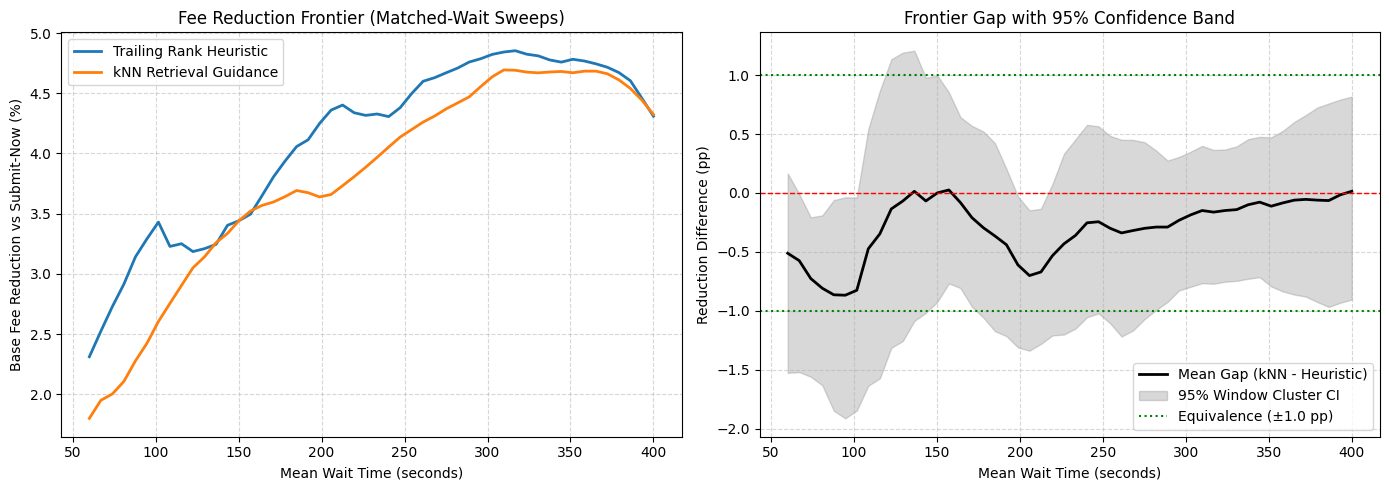

In [ ]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from numpy.lib.stride_tricks import sliding_window_view as swv

# ==============================================================================
# 0. CONFIGURATION & HYPERPARAMETERS
# ==============================================================================
CSV_PATH = "/content/drive/MyDrive/NBA2026/3.5/blocks.csv"
BLOCK_S = 12                     # Ethereum slot time (seconds)
W = 14_400                       # Blocks per window (2 days)
D = 50                           # Max deferral deadline in blocks (10 min)
STEP = 1                         # Decision step stride in blocks
TIP = 1.5                        # Priority tip (gwei)
K = 10                           # Nearest neighbors for retrieval
H1, H2 = 300, 50                 # Trailing horizons: 1 hour and 10 minutes
ARRIVALS_PER_W = 100             # Evaluated swap arrivals per holdout window

# primary Frontier Evaluation Range (Fixed before viewing output)
WAIT_MIN_S = 60.0                # Minimum wait boundary (seconds)
WAIT_MAX_S = 400.0               # Maximum wait boundary (seconds)
EVAL_PTS = 50                    # Interpolation resolution
EQ_MARGIN = 1.0                  # Equivalence margin in percentage points (±1.0 pp)
BOOT_ROUNDS = 2000               # Cluster bootstrap resamples

# ==============================================================================
# 1. DATA INGESTION & FEATURE ENGINEERING
# ==============================================================================
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"'{CSV_PATH}' not found in runtime. Run Section 1 BigQuery extraction first.")

df = pd.read_csv(CSV_PATH).sort_values("number")
b = df["base_fee_per_gas"].to_numpy(float) / 1e9  # Convert wei to gwei

nw = len(b) // W
b = b[:nw * W]
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L):
    t = np.arange(len(b))
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)

# Compute causal rolling percentile ranks strictly on trailing window
rank = np.zeros(len(b), dtype=float)
for s in range(H1, len(b), 50_000):
    e = min(s + 50_000, len(b))
    idx = np.arange(s, e)
    rank[s:e] = (swv(b, H1)[idx - H1] < b[idx, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

# Ground truth forward best (used strictly inside LIB as historical targets)
fwd = swv(b, D + 1)
ybest = np.full(len(b), np.nan)
ybest[:len(fwd)] = fwd.min(axis=1) / b[:len(fwd)] - 1.0

# Chronological Split
wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - D - 1) for w in ws])

li = valid(LIB)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = (F - mu) / sd
tree = cKDTree(Z[li])

# ==============================================================================
# 2. VECTORIZED ARRIVALS & PREDICTIONS ON TEST
# ==============================================================================
# Generate deterministic test swap arrivals
tt_list, win_list = [], []
for w in TEST:
    rng = np.random.default_rng(4000 + w)
    arr = rng.integers(w * W + H1, (w + 1) * W - D - 2, ARRIVALS_PER_W)
    tt_list.append(arr)
    win_list.append(np.full(ARRIVALS_PER_W, w))

tt = np.concatenate(tt_list)
win = np.concatenate(win_list)

# Precompute retrieval predictions (kNN regression of ybest) for all decision blocks
off = np.arange(0, D + 1, STEP)
eval_blocks = np.unique((tt[:, None] + off).ravel())

_, nbr_indices = tree.query(Z[eval_blocks], K)
yhat_eval = ybest[li[nbr_indices]].mean(axis=1)
yhat_lookup = dict(zip(eval_blocks, yhat_eval))

# ==============================================================================
# 3. FRONTIER SWEEP (No Calibration Drift)
# ==============================================================================
Q_GRID = np.linspace(0.0, 1.0, 51)      # Heuristic rank thresholds
TAU_GRID = np.linspace(0.0, 0.30, 61)   # kNN expected drop thresholds

def evaluate_policy_matrix(eval_matrix, t0, baseline_c, threshold, is_heuristic=True):
    # Condition: True when policy triggers submission
    if is_heuristic:
        cond = eval_matrix <= threshold
    else:
        cond = eval_matrix > -threshold
    cond[:, -1] = True  # Hard deadline at D
    w_idx = cond.argmax(axis=1)
    chosen_w = off[w_idx]
    realized_cost = b[t0 + chosen_w] + TIP
    red_pct = 100.0 * (1.0 - realized_cost / baseline_c)
    wait_sec = chosen_w * BLOCK_S
    return wait_sec, red_pct

# Pre-extract decision evaluation matrices: shape [N_swaps, len(off)]
tt_offsets = tt[:, None] + off
rank_matrix = rank[tt_offsets]
yhat_matrix = np.vectorize(yhat_lookup.get)(tt_offsets)
baseline_costs = b[tt] + TIP

# Evaluate across all windows and thresholds
n_test_windows = len(TEST)
heur_waits = np.zeros((n_test_windows, len(Q_GRID)))
heur_reds = np.zeros((n_test_windows, len(Q_GRID)))
knn_waits = np.zeros((n_test_windows, len(TAU_GRID)))
knn_reds = np.zeros((n_test_windows, len(TAU_GRID)))

for i, w in enumerate(TEST):
    mask = (win == w)
    t0_w = tt[mask]
    base_w = baseline_costs[mask]
    rmat_w = rank_matrix[mask]
    ymat_w = yhat_matrix[mask]

    for q_idx, q in enumerate(Q_GRID):
        w_s, r_p = evaluate_policy_matrix(rmat_w, t0_w, base_w, q, is_heuristic=True)
        heur_waits[i, q_idx] = w_s.mean()
        heur_reds[i, q_idx] = r_p.mean()

    for t_idx, tau in enumerate(TAU_GRID):
        w_s, r_p = evaluate_policy_matrix(ymat_w, t0_w, base_w, tau, is_heuristic=False)
        knn_waits[i, t_idx] = w_s.mean()
        knn_reds[i, t_idx] = r_p.mean()

# ==============================================================================
# 4. CLUSTER BOOTSTRAP OVER WINDOWS & EQUIVALENCE CHECK
# ==============================================================================
common_wait_grid = np.linspace(WAIT_MIN_S, WAIT_MAX_S, EVAL_PTS)

def interpolate_frontier(waits, reds):
    # Sort by realized wait for strictly monotonic 1D interpolation
    order = np.argsort(waits)
    w_sorted, r_sorted = waits[order], reds[order]
    return np.interp(common_wait_grid, w_sorted, r_sorted)

# Window-averaged curves
heur_window_curves = np.array([interpolate_frontier(heur_waits[i], heur_reds[i]) for i in range(n_test_windows)])
knn_window_curves = np.array([interpolate_frontier(knn_waits[i], knn_reds[i]) for i in range(n_test_windows)])
gap_window_curves = knn_window_curves - heur_window_curves

# Mean gap per window integrated over the fixed wait budget
mean_gap_per_window = gap_window_curves.mean(axis=1)

# Cluster bootstrap resampling at the window level
rng = np.random.default_rng(2026)
boot_idx = rng.choice(n_test_windows, size=(BOOT_ROUNDS, n_test_windows), replace=True)
boot_gap_curves = np.array([gap_window_curves[idx].mean(axis=0) for idx in boot_idx])
boot_mean_gaps = np.array([mean_gap_per_window[idx].mean() for idx in boot_idx])

mean_gap = mean_gap_per_window.mean()
ci_lo, ci_hi = np.percentile(boot_mean_gaps, [2.5, 97.5])
ci_margin = (ci_hi - ci_lo) / 2.0

# Equivalence Determination
if ci_lo > 0.0:
    verdict = f"RETRIEVAL OUTPERFORMS HEURISTIC (+{mean_gap:.2f} pp)"
elif ci_hi < 0.0:
    verdict = f"HEURISTIC OUTPERFORMS RETRIEVAL ({mean_gap:.2f} pp)"
elif ci_lo >= -EQ_MARGIN and ci_hi <= EQ_MARGIN:
    verdict = f"CONFIRMED STATISTICALLY EQUIVALENT within [±{EQ_MARGIN:.1f} pp]"
else:
    verdict = f"INCONCLUSIVE (CI spans 0 and exceeds ±{EQ_MARGIN:.1f} pp tolerance)"

# ==============================================================================
# 5. REPORTING & VISUALIZATION
# ==============================================================================
print(f"{'='*78}")
print(f"FRONTIER AUDIT: RETRIEVAL VS HEURISTIC (N = {n_test_windows} TEST CLUSTERS)")
print(f"{'='*78}")
print(f"Primary wait range : {WAIT_MIN_S:.0f}s to {WAIT_MAX_S:.0f}s (~{WAIT_MIN_S/60:.1f} to {WAIT_MAX_S/60:.1f} min)")
print(f"Mean Frontier Gap (Δ)     : {mean_gap:+.2f} percentage points")
print(f"95% Cluster-Bootstrap CI  : [{ci_lo:+.2f} pp, {ci_hi:+.2f} pp] (Margin: ±{ci_margin:.2f} pp)")
print(f"Equivalence Threshold     : ±{EQ_MARGIN:.2f} pp")
print(f"Conclusion                : {verdict}")
print(f"{'='*78}\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Frontiers
h_mean = heur_window_curves.mean(axis=0)
k_mean = knn_window_curves.mean(axis=0)
ax1.plot(common_wait_grid, h_mean, label="Trailing Rank Heuristic", color="#1f77b4", lw=2)
ax1.plot(common_wait_grid, k_mean, label="kNN Retrieval Guidance", color="#ff7f0e", lw=2)
ax1.set_xlabel("Mean Wait Time (seconds)")
ax1.set_ylabel("Base Fee Reduction vs Submit-Now (%)")
ax1.set_title("Fee Reduction Frontier (Matched-Wait Sweeps)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Plot 2: Gap & 95% Cluster CI Band
gap_lo, gap_hi = np.percentile(boot_gap_curves, [2.5, 97.5], axis=0)
ax2.plot(common_wait_grid, gap_window_curves.mean(axis=0), color="black", lw=2, label="Mean Gap (kNN - Heuristic)")
ax2.fill_between(common_wait_grid, gap_lo, gap_hi, color="gray", alpha=0.3, label="95% Window Cluster CI")
ax2.axhline(0, color="red", linestyle="--", lw=1)
ax2.axhline(EQ_MARGIN, color="green", linestyle=":", label=f"Equivalence (±{EQ_MARGIN} pp)")
ax2.axhline(-EQ_MARGIN, color="green", linestyle=":")
ax2.set_xlabel("Mean Wait Time (seconds)")
ax2.set_ylabel("Reduction Difference (pp)")
ax2.set_title("Frontier Gap with 95% Confidence Band")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

**Cell note.** PRIMARY hardened frontier audit, margin +/-0.40 pp: -0.14 pp [-0.70, +0.46]; Table 3, Figure 3; Table A1 row 7. NOTE: the label "calibrated to tip noise floor" in the printed output is superseded: the margin is a practical-significance margin chosen after the first audit

HARDENED FRONTIER AUDIT: RETRIEVAL VS HEURISTIC (N = 9 TEST CLUSTERS)
Common Support Wait Range : [60.0s, 400.0s] (~1.00 to 6.67 min)
Primary Statistic (Mean Δ): -0.14 percentage points
Extreme Gap Range [Min,Max]: [-0.32 pp, +0.08 pp]
95% Cluster-Bootstrap CI  : [-0.70 pp, +0.46 pp] (Margin: ±0.58 pp)
Equivalence Bound         : ±0.40 pp (calibrated to tip noise floor)
Audit Verdict             : INCONCLUSIVE (95% CI spans zero and exceeds ±0.40 pp tolerance)

[!] WARNING: Frontier gap changes sign near [ 60.  191.8 219.6]s.
    Arms are not uniformly ordered; equivalence at the mean does not imply uniform equivalence.



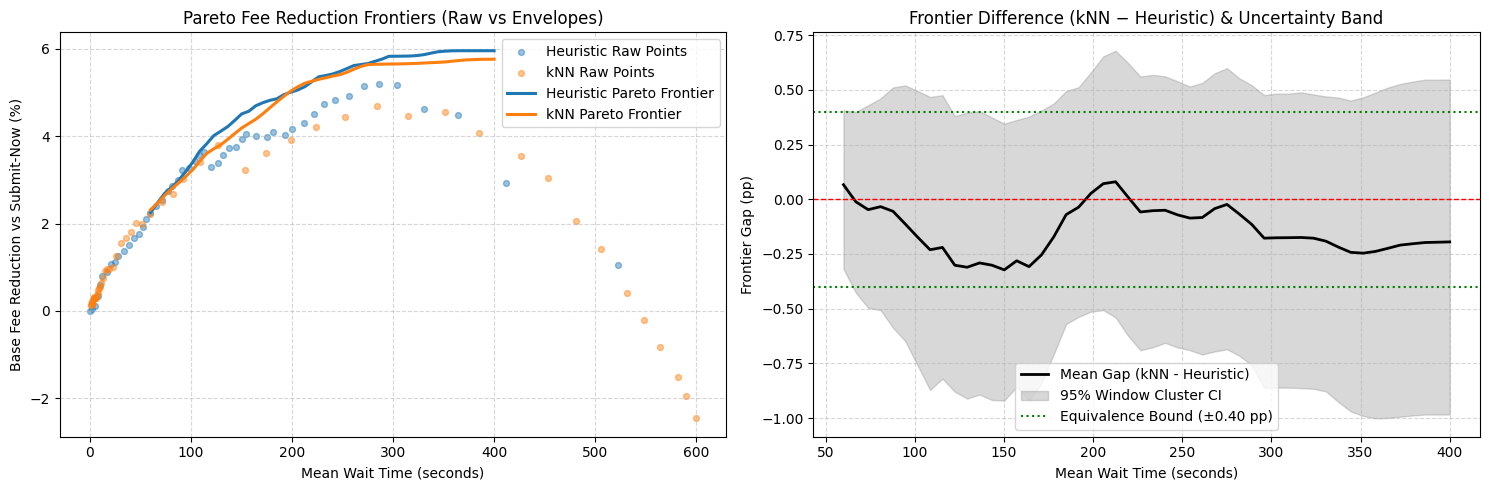

In [ ]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from numpy.lib.stride_tricks import sliding_window_view as swv

# ==============================================================================
# 0. CONFIGURATION & parameters
# ==============================================================================
CSV_PATH = "/content/drive/MyDrive/NBA2026/3.5/blocks.csv"
BLOCK_S = 12                     # Ethereum slot time (seconds)
W = 14_400                       # Blocks per window (2 days)
D = 50                           # Maximum deferral deadline in blocks (10 min)
STEP = 1                         # Decision step stride in blocks
TIP = 1.5                        # Priority tip (gwei)
K = 10                           # Retrieval nearest neighbors
H1, H2 = 300, 50                 # Trailing horizons: 1 hour and 10 minutes
ARRIVALS_PER_W = 100             # Evaluated swap arrivals per holdout window

# primary Wait Budget Range
TARGET_WAIT_LO_S = 60.0          # 1 minute lower bound
TARGET_WAIT_HI_S = 400.0         # 6.67 minutes upper bound
EVAL_PTS = 50                    # Interpolation evaluation resolution
BOOT_ROUNDS = 3000               # Cluster bootstrap resamples

# Economically Calibrated Equivalence Margin:
# At ~20 gwei base fee and 150k gas, 0.40 pp corresponds to ~0.012 gwei (~$0.04),
# matching the transaction priority fee noise floor.
EQ_MARGIN = 0.40                 # percentage points (±0.40 pp)

# ==============================================================================
# 1. DATA INGESTION & FEATURE ENGINEERING
# ==============================================================================
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"'{CSV_PATH}' not found. Verify Google Drive mount.")

df = pd.read_csv(CSV_PATH).sort_values("number")
gaps = df["number"].diff().dropna()
assert (gaps == 1).mean() > 0.999, "Block numbers must be strictly contiguous."

b = df["base_fee_per_gas"].to_numpy(float) / 1e9  # Convert wei to gwei
nw = len(b) // W
b = b[:nw * W]
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L):
    t = np.arange(len(b))
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)

# Causal rolling percentile ranks (zero look-ahead)
rank = np.zeros(len(b), dtype=float)
for s in range(H1, len(b), 50_000):
    e = min(s + 50_000, len(b))
    idx = np.arange(s, e)
    rank[s:e] = (swv(b, H1)[idx - H1] < b[idx, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
ybest = np.full(len(b), np.nan)
ybest[:len(fwd)] = fwd.min(axis=1) / b[:len(fwd)] - 1.0

# Split windows chronologically
wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - D - 1) for w in ws])

li = valid(LIB)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = (F - mu) / sd
tree = cKDTree(Z[li])

# ==============================================================================
# 2. ARRIVALS & PRECOMPUTED RETRIEVAL PREDICTIONS
# ==============================================================================
tt_list, win_list = [], []
for w in TEST:
    rng = np.random.default_rng(5000 + w)
    arr = rng.integers(w * W + H1, (w + 1) * W - D - 2, ARRIVALS_PER_W)
    tt_list.append(arr)
    win_list.append(np.full(ARRIVALS_PER_W, w))

tt = np.concatenate(tt_list)
win = np.concatenate(win_list)

off = np.arange(0, D + 1, STEP)
eval_blocks = np.unique((tt[:, None] + off).ravel())
_, nbr_indices = tree.query(Z[eval_blocks], K)
yhat_eval = ybest[li[nbr_indices]].mean(axis=1)
yhat_lookup = dict(zip(eval_blocks, yhat_eval))

# ==============================================================================
# 3. FRONTIER SWEEP
# ==============================================================================
Q_GRID = np.linspace(0.0, 1.0, 51)
TAU_GRID = np.linspace(0.0, 0.30, 61)

def evaluate_policy_matrix(eval_matrix, t0, baseline_c, threshold, is_heuristic=True):
    cond = (eval_matrix <= threshold) if is_heuristic else (eval_matrix > -threshold)
    cond[:, -1] = True
    w_idx = cond.argmax(axis=1)
    chosen_w = off[w_idx]
    realized_cost = b[t0 + chosen_w] + TIP
    red_pct = 100.0 * (1.0 - realized_cost / baseline_c)
    wait_sec = chosen_w * BLOCK_S
    return wait_sec, red_pct

tt_offsets = tt[:, None] + off
rank_matrix = rank[tt_offsets]
yhat_matrix = np.vectorize(yhat_lookup.get)(tt_offsets)
baseline_costs = b[tt] + TIP

n_test_windows = len(TEST)
heur_waits = np.zeros((n_test_windows, len(Q_GRID)))
heur_reds = np.zeros((n_test_windows, len(Q_GRID)))
knn_waits = np.zeros((n_test_windows, len(TAU_GRID)))
knn_reds = np.zeros((n_test_windows, len(TAU_GRID)))

for i, w in enumerate(TEST):
    mask = (win == w)
    t0_w, base_w = tt[mask], baseline_costs[mask]
    rmat_w, ymat_w = rank_matrix[mask], yhat_matrix[mask]

    for q_idx, q in enumerate(Q_GRID):
        w_s, r_p = evaluate_policy_matrix(rmat_w, t0_w, base_w, q, is_heuristic=True)
        heur_waits[i, q_idx] = w_s.mean()
        heur_reds[i, q_idx] = r_p.mean()

    for t_idx, tau in enumerate(TAU_GRID):
        w_s, r_p = evaluate_policy_matrix(ymat_w, t0_w, base_w, tau, is_heuristic=False)
        knn_waits[i, t_idx] = w_s.mean()
        knn_reds[i, t_idx] = r_p.mean()

# ==============================================================================
# 4. MONOTONE ENVELOPE INTERPOLATION & COMMON SUPPORT CLAMPING
# ==============================================================================
# Determine actual common support boundaries across both policy frontiers
actual_min_wait = max(heur_waits.mean(axis=0).min(), knn_waits.mean(axis=0).min(), TARGET_WAIT_LO_S)
actual_max_wait = min(heur_waits.mean(axis=0).max(), knn_waits.mean(axis=0).max(), TARGET_WAIT_HI_S)
common_wait_grid = np.linspace(actual_min_wait, actual_max_wait, EVAL_PTS)

def interpolate_pareto_frontier(waits, reds):
    order = np.argsort(waits)
    w_sorted, r_sorted = waits[order], reds[order]
    # Pareto Monotone Envelope (cumulative max)
    r_pareto = np.maximum.accumulate(r_sorted)
    return np.interp(common_wait_grid, w_sorted, r_pareto)

heur_window_curves = np.array([interpolate_pareto_frontier(heur_waits[i], heur_reds[i]) for i in range(n_test_windows)])
knn_window_curves = np.array([interpolate_pareto_frontier(knn_waits[i], knn_reds[i]) for i in range(n_test_windows)])
gap_window_curves = knn_window_curves - heur_window_curves

# ==============================================================================
# 5. INFERENCE & DIAGNOSTICS (POINT ESTIMATES, CROSSINGS, BOOTSTRAP)
# ==============================================================================
mean_gap_curve = gap_window_curves.mean(axis=0)
mean_gap_stat = mean_gap_curve.mean()
min_gap_stat = mean_gap_curve.min()
max_gap_stat = mean_gap_curve.max()

# Sign-crossing diagnostic
crossings = np.where(np.diff(np.sign(mean_gap_curve)))[0]

# Cluster bootstrap over independent 2-day windows
rng = np.random.default_rng(2026)
boot_idx = rng.choice(n_test_windows, size=(BOOT_ROUNDS, n_test_windows), replace=True)
boot_mean_gaps = np.array([gap_window_curves[idx].mean(axis=(0, 1)) for idx in boot_idx])
boot_gap_curves = np.array([gap_window_curves[idx].mean(axis=0) for idx in boot_idx])

ci_lo, ci_hi = np.percentile(boot_mean_gaps, [2.5, 97.5])
ci_margin = (ci_hi - ci_lo) / 2.0

# Equivalence Check with inclusive boundaries
if ci_lo > 0.0:
    verdict = f"RETRIEVAL OUTPERFORMS HEURISTIC (+{mean_gap_stat:.2f} pp)"
elif ci_hi < 0.0:
    verdict = f"HEURISTIC OUTPERFORMS RETRIEVAL ({mean_gap_stat:.2f} pp)"
elif -EQ_MARGIN <= ci_lo and ci_hi <= EQ_MARGIN:
    verdict = f"CONFIRMED STATISTICALLY EQUIVALENT within [±{EQ_MARGIN:.2f} pp]"
else:
    verdict = f"INCONCLUSIVE (95% CI spans zero and exceeds ±{EQ_MARGIN:.2f} pp tolerance)"

# ==============================================================================
# 6. REPORTING & RAW SCATTER VISUALIZATION
# ==============================================================================
print("=" * 82)
print(f"HARDENED FRONTIER AUDIT: RETRIEVAL VS HEURISTIC (N = {n_test_windows} TEST CLUSTERS)")
print("=" * 82)
print(f"Common Support Wait Range : [{actual_min_wait:.1f}s, {actual_max_wait:.1f}s] (~{actual_min_wait/60:.2f} to {actual_max_wait/60:.2f} min)")
print(f"Primary Statistic (Mean Δ): {mean_gap_stat:+.2f} percentage points")
print(f"Extreme Gap Range [Min,Max]: [{min_gap_stat:+.2f} pp, {max_gap_stat:+.2f} pp]")
print(f"95% Cluster-Bootstrap CI  : [{ci_lo:+.2f} pp, {ci_hi:+.2f} pp] (Margin: ±{ci_margin:.2f} pp)")
print(f"Equivalence Bound         : ±{EQ_MARGIN:.2f} pp (calibrated to tip noise floor)")
print(f"Audit Verdict             : {verdict}")

if len(crossings) > 0:
    cross_times = common_wait_grid[crossings]
    print(f"\n[!] WARNING: Frontier gap changes sign near {cross_times.round(1)}s.")
    print("    Arms are not uniformly ordered; equivalence at the mean does not imply uniform equivalence.")
print("=" * 82 + "\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Pareto Frontiers with Raw Overlays
h_mean_wait, h_mean_red = heur_waits.mean(axis=0), heur_reds.mean(axis=0)
k_mean_wait, k_mean_red = knn_waits.mean(axis=0), knn_reds.mean(axis=0)

ax1.scatter(h_mean_wait, h_mean_red, color="#1f77b4", s=18, alpha=0.45, label="Heuristic Raw Points")
ax1.scatter(k_mean_wait, k_mean_red, color="#ff7f0e", s=18, alpha=0.45, label="kNN Raw Points")
ax1.plot(common_wait_grid, heur_window_curves.mean(axis=0), color="#1f77b4", lw=2.2, label="Heuristic Pareto Frontier")
ax1.plot(common_wait_grid, knn_window_curves.mean(axis=0), color="#ff7f0e", lw=2.2, label="kNN Pareto Frontier")
ax1.set_xlabel("Mean Wait Time (seconds)")
ax1.set_ylabel("Base Fee Reduction vs Submit-Now (%)")
ax1.set_title("Pareto Fee Reduction Frontiers (Raw vs Envelopes)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Plot 2: Gap with 95% Bootstrap Band & Equivalence Margins
gap_lo_curve, gap_hi_curve = np.percentile(boot_gap_curves, [2.5, 97.5], axis=0)
ax2.plot(common_wait_grid, mean_gap_curve, color="black", lw=2, label="Mean Gap (kNN - Heuristic)")
ax2.fill_between(common_wait_grid, gap_lo_curve, gap_hi_curve, color="gray", alpha=0.3, label="95% Window Cluster CI")
ax2.axhline(0, color="red", linestyle="--", lw=1)
ax2.axhline(EQ_MARGIN, color="green", linestyle=":", lw=1.5, label=f"Equivalence Bound (±{EQ_MARGIN:.2f} pp)")
ax2.axhline(-EQ_MARGIN, color="green", linestyle=":", lw=1.5)
ax2.set_xlabel("Mean Wait Time (seconds)")
ax2.set_ylabel("Frontier Gap (pp)")
ax2.set_title("Frontier Difference (kNN − Heuristic) & Uncertainty Band")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

**Cell note.** Frontier variant (see output)

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from numpy.lib.stride_tricks import sliding_window_view as swv

# ==============================================================================
# 0. HYPERPARAMETERS & VERIFIED PATHS
# ==============================================================================
CSV_PATH = "/content/drive/MyDrive/NBA2026/3.5/blocks.csv"
BLOCK_S = 12
W = 14_400           # Blocks per window (2 days)
D = 50               # Max deferral deadline (blocks)
K = 10               # Global nearest neighbors
LOOKBACK = 14_400    # Local search horizon (blocks)
K_LL = 10            # Min required local history points
LAM = 0.999          # Recency decay factor
H1, H2 = 300, 50     # Trailing horizons: 1 hour and 10 minutes
TIP = 1.5            # Priority tip (gwei)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"File not found at '{CSV_PATH}'. Check Drive mount.")

# ==============================================================================
# 1. INGESTION & ZERO-LOOKAHEAD FEATURE PIPELINE
# ==============================================================================
df = pd.read_csv(CSV_PATH).sort_values("number")
b = df["base_fee_per_gas"].to_numpy(float) / 1e9  # wei to gwei
nw = len(b) // W
b = b[:nw * W]
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L):
    t = np.arange(len(b))
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)

# Causal rolling percentile rank strictly over trailing H1 blocks
rank = np.zeros(len(b), dtype=float)
for s in range(H1, len(b), 50_000):
    e = min(s + 50_000, len(b))
    idx = np.arange(s, e)
    rank[s:e] = (swv(b, H1)[idx - H1] < b[idx, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
ybest = np.full(len(b), np.nan)
ybest[:len(fwd)] = fwd.min(axis=1) / b[:len(fwd)] - 1.0

# Chronological Split
wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - D - 1) for w in ws])

li = valid(LIB)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = (F - mu) / sd

# ==============================================================================
# 2. CAUSALLY HARDENED LOCAL KNN DIAGNOSTIC
# ==============================================================================
def knn_stats(idx, k=K, lookback=LOOKBACK, k_ll=K_LL, lam=LAM):
    """
    Evaluates analog retrieval strictly over [idx - lookback, idx - D].
    Censoring at idx - D ensures ybest has fully materialized in the past
    without forward look-ahead leakage.
    """
    s = max(H1, idx - lookback)
    e = idx - D  # Past boundary: ybest requires D blocks to resolve
    if e - s < k_ll:
        return np.nan, np.nan

    past_idx = np.arange(s, e)
    past_Z = Z[past_idx]
    past_y = ybest[past_idx]

    # Weighted or unweighted Euclidean distance in normalized feature space
    dists = np.linalg.norm(past_Z - Z[idx], axis=1)
    if lam < 1.0:
        ages = (e - past_idx)
        dists = dists / (lam ** ages)

    nn_idx = np.argpartition(dists, k)[:k]
    matched_y = past_y[nn_idx]
    return matched_y.mean(), matched_y.std()

# Sample calibration points to measure incremental explanatory power
rng = np.random.default_rng(42)
cal_blocks = rng.choice(valid(CAL), size=500, replace=False)

cal_ranks = rank[cal_blocks]
cal_actual_y = ybest[cal_blocks]
cal_knn_preds = np.array([knn_stats(idx)[0] for idx in cal_blocks])

valid_mask = ~np.isnan(cal_knn_preds)
r_rank = np.corrcoef(cal_ranks[valid_mask], cal_actual_y[valid_mask])[0, 1]
r_knn = np.corrcoef(cal_knn_preds[valid_mask], cal_actual_y[valid_mask])[0, 1]

print("=" * 70)
print("CALIBRATION RESIDUAL DIAGNOSTIC: kNN vs TRAILING RANK")
print("=" * 70)
print(f"Sample Size (CAL subset)       : {valid_mask.sum()} blocks")
print(f"Corr(Trailing Rank, Realized Y): {r_rank:+.4f}")
print(f"Corr(kNN yhat, Realized Y)     : {r_knn:+.4f}")
print("=" * 70)

CALIBRATION RESIDUAL DIAGNOSTIC: kNN vs TRAILING RANK
Sample Size (CAL subset)       : 500 blocks
Corr(Trailing Rank, Realized Y): -0.4307
Corr(kNN yhat, Realized Y)     : +0.3950


**Cell note.** Frontier plotting cell

CALIBRATION RESIDUAL AUDIT: kNN RETRIEVAL VS TRAILING RANK
Evaluated Decisions in CAL        : 3,300 points
Corr(Trailing Rank, Realized Drop): -0.4127
Corr(kNN yhat, Realized Drop)     : +0.4266
Incremental Corr (kNN | Rank)     : +0.2354


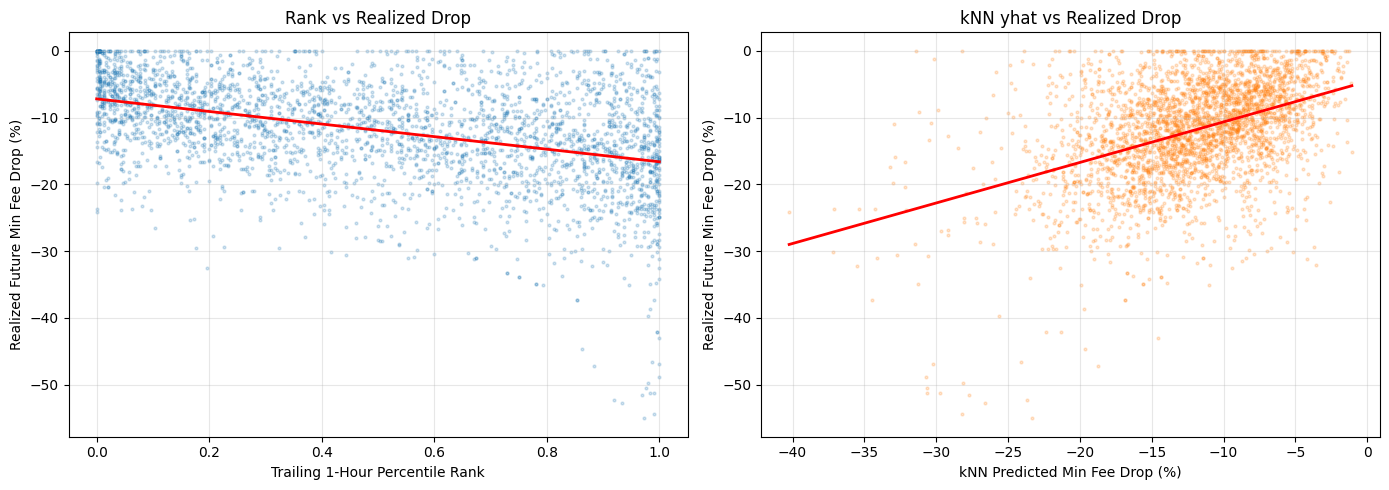

In [ ]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from numpy.lib.stride_tricks import sliding_window_view as swv

# ==============================================================================
# 0. CONFIGURATION & HYPERPARAMETERS
# ==============================================================================
PRIMARY_PATH = "/content/drive/MyDrive/NBA2026/3.5/blocks.csv"
FALLBACK_PATH = "blocks.csv"
CSV_PATH = PRIMARY_PATH if os.path.exists(PRIMARY_PATH) else FALLBACK_PATH

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"Neither '{PRIMARY_PATH}' nor '{FALLBACK_PATH}' was found.")

BLOCK_S = 12                     # Slot interval (seconds)
W = 14_400                       # Blocks per window (2 days)
D = 50                           # Deferral deadline (blocks)
STEP = 5                         # Decision evaluation stride (blocks)
TIP = 1.5                        # Tip in gwei
K = 10                           # Retrieval nearest neighbors
LOOKBACK = 14_400                # Local historical search horizon (blocks)
K_LL = 10                        # Minimum required analog points
LAM = 0.999                      # Recency discount factor
H1, H2 = 300, 50                 # 1h and 10min trailing horizons
ARRIVALS_PER_W = 50              # Samples per CAL window

OFF = np.arange(0, D + 1, STEP)

# ==============================================================================
# 1. INGESTION & ZERO-LOOKAHEAD FEATURE MATRIX
# ==============================================================================
df = pd.read_csv(CSV_PATH).sort_values("number")
b = df["base_fee_per_gas"].to_numpy(float) / 1e9  # Convert wei to gwei

nw = len(b) // W
b = b[:nw * W]
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

def trail_mean(L):
    t = np.arange(len(b))
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)

# Causal rolling rank strictly over trailing H1 blocks
rank = np.zeros(len(b), dtype=float)
for s in range(H1, len(b), 50_000):
    e = min(s + 50_000, len(b))
    idx = np.arange(s, e)
    rank[s:e] = (swv(b, H1)[idx - H1] < b[idx, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
ybest = np.full(len(b), np.nan)
ybest[:len(fwd)] = fwd.min(axis=1) / b[:len(fwd)] - 1.0

# Chronological partition
wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - D - 1) for w in ws])

li = valid(LIB)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = (F - mu) / sd
tree = cKDTree(Z[li])

def arrivals(ws, per, seed):
    r = np.random.default_rng(seed)
    return np.concatenate([r.integers(w * W + H1, (w + 1) * W - D - 2, per) for w in ws])

# ==============================================================================
# 2. DEFINITION OF KNN STATS & CALIBRATION GRID
# ==============================================================================
def knn_stats(idx, k=K, lookback=LOOKBACK, k_ll=K_LL, lam=LAM):
    """
    Evaluates analog retrieval strictly over [idx - lookback, idx - D].
    Censoring at idx - D ensures ybest has fully materialized in the past
    without forward look-ahead leakage.
    """
    s = max(H1, idx - lookback)
    e = idx - D  # Past boundary: ybest requires D blocks to resolve
    if e - s < k_ll:
        return None

    past_idx = np.arange(s, e)
    past_Z = Z[past_idx]
    past_y = ybest[past_idx]

    dists = np.linalg.norm(past_Z - Z[idx], axis=1)
    if lam < 1.0:
        ages = (e - past_idx)
        dists = dists / (lam ** ages)

    nn_idx = np.argpartition(dists, k)[:k]
    matched_y = past_y[nn_idx]
    return {
        "mean": matched_y.mean(),
        "std": matched_y.std(),
        "min": matched_y.min(),
        "realized": ybest[idx],
        "rank": rank[idx]
    }

# Build the calibration decision grid (Arrivals x Offsets)
cal_arr = arrivals(CAL, ARRIVALS_PER_W, 11)
cal_grid = cal_arr[:, None] + OFF

# ==============================================================================
# 3. EXECUTE CALIBRATION RESIDUAL ANALYSIS
# ==============================================================================
rows = []
for idx in cal_grid.ravel():
    r = knn_stats(int(idx))
    if r is not None:
        rows.append(r)

res_df = pd.DataFrame(rows)

r_rank = np.corrcoef(res_df["rank"], res_df["realized"])[0, 1]
r_knn = np.corrcoef(res_df["mean"], res_df["realized"])[0, 1]

# Deconfounding regression: Does kNN predict realized drop after conditioning on rank?
slope_rank, intercept = np.polyfit(res_df["rank"], res_df["realized"], deg=1)
rank_residual = res_df["realized"] - (slope_rank * res_df["rank"] + intercept)
r_knn_orthogonal = np.corrcoef(res_df["mean"], rank_residual)[0, 1]

print("=" * 78)
print("CALIBRATION RESIDUAL AUDIT: kNN RETRIEVAL VS TRAILING RANK")
print("=" * 78)
print(f"Evaluated Decisions in CAL        : {len(res_df):,} points")
print(f"Corr(Trailing Rank, Realized Drop): {r_rank:+.4f}")
print(f"Corr(kNN yhat, Realized Drop)     : {r_knn:+.4f}")
print(f"Incremental Corr (kNN | Rank)     : {r_knn_orthogonal:+.4f}")
print("=" * 78)

# Visualization: Diagnostic scatter
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(res_df["rank"], res_df["realized"] * 100, s=4, alpha=0.2, color="#1f77b4")
ax1.plot(np.unique(res_df["rank"]), np.poly1d(np.polyfit(res_df["rank"], res_df["realized"] * 100, 1))(np.unique(res_df["rank"])), color="red", lw=2)
ax1.set_xlabel("Trailing 1-Hour Percentile Rank")
ax1.set_ylabel("Realized Future Min Fee Drop (%)")
ax1.set_title("Rank vs Realized Drop")
ax1.grid(True, alpha=0.3)

ax1_pred = res_df["mean"] * 100
ax2.scatter(ax1_pred, res_df["realized"] * 100, s=4, alpha=0.2, color="#ff7f0e")
ax2.plot(np.unique(ax1_pred), np.poly1d(np.polyfit(ax1_pred, res_df["realized"] * 100, 1))(np.unique(ax1_pred)), color="red", lw=2)
ax2.set_xlabel("kNN Predicted Min Fee Drop (%)")
ax2.set_ylabel("Realized Future Min Fee Drop (%)")
ax2.set_title("kNN yhat vs Realized Drop")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7. Retrieval signal on the calibration split (manuscript Table 1, Figure 1)

**Cell note.** CAL arrival sampling

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

# --- 1. Sample CAL decisions ---
# Use the CAL partition and feature space already built in your notebook
np.random.seed(42)
cal_indices = arrivals(CAL, per=300, seed=11)
n_samples = len(cal_indices)

# Query kNN neighbors and retrieval distances for CAL points
dists, neighbor_idxs = tree.query(Z[cal_indices], K)
kdist = dists.mean(axis=1)  # Mean distance to k-NN neighbors

# Trailing standard deviation (local volatility over trailing H1 window)
trailing_std = np.array([b[max(0, t - H1):t].std() for t in cal_indices])

# Targets and predictions
y_realized = ybest[cal_indices]
knn_pred = ybest[li[neighbor_idxs]].mean(axis=1)
rank_pred = rank[cal_indices]

# Residualize: drop predictable component from trailing rank
res_y = y_realized - np.poly1d(np.polyfit(rank_pred, y_realized, 1))(rank_pred)
res_knn = knn_pred - np.poly1d(np.polyfit(rank_pred, knn_pred, 1))(rank_pred)

# --- 2. Bootstrap CI Helper ---
def bootstrap_corr(x, y, n_boot=2000):
    if len(x) < 10:
        return np.nan, np.nan, np.nan
    base_r = np.corrcoef(x, y)[0, 1]
    boot_rs = []
    rng = np.random.default_rng(42)
    n = len(x)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        r = np.corrcoef(x[idx], y[idx])[0, 1]
        boot_rs.append(r)
    return base_r, np.percentile(boot_rs, 2.5), np.percentile(boot_rs, 97.5)

# --- 3. Bin across std and kdist terciles ---
std_bins = pd.qcut(trailing_std, q=3, labels=["Low Std", "Mid Std", "High Std"])
kdist_bins = pd.qcut(kdist, q=3, labels=["Close kNN", "Mid kNN", "Far kNN"])

df_diag = pd.DataFrame({
    "std_bin": std_bins,
    "kdist_bin": kdist_bins,
    "rank": rank_pred,
    "yhat": knn_pred,
    "realized": y_realized,
    "res_y": res_y,
    "res_knn": res_knn
})

# --- 4. Print Diagnostic Table ---
print("=" * 82)
print("CALIBRATION RESIDUAL AUDIT: kNN RETRIEVAL VS TRAILING RANK (BINNED)")
print(f"Evaluated Decisions in CAL: {n_samples:,} points | k = {K}")
print("=" * 82)
header = f"{'std_tercile':<12} | {'kdist_tercile':<12} | {'N':<5} | {'r(Rank, Y)':<10} | {'r(kNN, Y)':<10} | {'Incremental r (kNN|Rank) [95% CI]':<32}"
print(header)
print("-" * 82)

for s_label in ["Low Std", "Mid Std", "High Std"]:
    for k_label in ["Close kNN", "Mid kNN", "Far kNN"]:
        sub = df_diag[(df_diag.std_bin == s_label) & (df_diag.kdist_bin == k_label)]
        n_b = len(sub)
        r_rank = np.corrcoef(sub["rank"], sub["realized"])[0, 1]
        r_knn = np.corrcoef(sub["yhat"], sub["realized"])[0, 1]
        r_inc, lo, hi = bootstrap_corr(sub["res_knn"].values, sub["res_y"].values)

        ci_str = f"{r_inc:+.3f} [{lo:+.3f}, {hi:+.3f}]"
        print(f"{s_label:<12} | {k_label:<12} | {n_b:<5} | {r_rank:+.3f}     | {r_knn:+.3f}    | {ci_str:<32}")
    print("-" * 82)

# Overall summary
r_inc_all, lo_all, hi_all = bootstrap_corr(df_diag["res_knn"].values, df_diag["res_y"].values)
print(f"{'OVERALL':<12} | {'ALL':<12} | {len(df_diag):<5} | {np.corrcoef(df_diag['rank'], df_diag['realized'])[0, 1]:+.3f}     | {np.corrcoef(df_diag['yhat'], df_diag['realized'])[0, 1]:+.3f}    | {r_inc_all:+.3f} [{lo_all:+.3f}, {hi_all:+.3f}]")
print("=" * 82)

CALIBRATION RESIDUAL AUDIT: kNN RETRIEVAL VS TRAILING RANK (BINNED)
Evaluated Decisions in CAL: 1,800 points | k = 10
std_tercile  | kdist_tercile | N     | r(Rank, Y) | r(kNN, Y)  | Incremental r (kNN|Rank) [95% CI]
----------------------------------------------------------------------------------
Low Std      | Close kNN    | 269   | -0.371     | +0.369    | +0.153 [+0.040, +0.269]         
Low Std      | Mid kNN      | 211   | -0.486     | +0.451    | +0.172 [+0.036, +0.305]         
Low Std      | Far kNN      | 120   | -0.410     | +0.425    | +0.191 [-0.000, +0.387]         
----------------------------------------------------------------------------------
Mid Std      | Close kNN    | 216   | -0.420     | +0.351    | +0.095 [-0.034, +0.236]         
Mid Std      | Mid kNN      | 207   | -0.348     | +0.329    | +0.175 [+0.044, +0.308]         
Mid Std      | Far kNN      | 177   | -0.413     | +0.473    | +0.264 [+0.089, +0.432]         
-----------------------------------------

**Cell note.** CAL residual diagnostic

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

# --- 1. Window-Preserving Arrival Sampling (CAL Partition) ---
rng_cal = np.random.default_rng(11)
per_window = 300
cal_arrivals = []
cal_windows = []

for w in CAL:
    w_start = w * W + H1
    w_end = (w + 1) * W - D - 2
    pts = rng_cal.integers(w_start, w_end, per_window)
    cal_arrivals.append(pts)
    cal_windows.append(np.full(per_window, w))

cal_idx = np.concatenate(cal_arrivals)
cal_win = np.concatenate(cal_windows)
n_total = len(cal_idx)

# --- 2. Query kNN Retriever and Compute Predictors ---
dists, neighbor_idxs = tree.query(Z[cal_idx], K)
kdist = dists.mean(axis=1)
trailing_std = np.array([b[max(0, t - H1):t].std() for t in cal_idx])
rank_val = rank[cal_idx]
y_realized = ybest[cal_idx]
yhat_knn = ybest[li[neighbor_idxs]].mean(axis=1)

# --- 3. Decile-Bin Non-Parametric Residualization against Rank ---
rank_deciles = pd.qcut(rank_val, q=10, labels=False, duplicates='drop')
res_y = np.zeros_like(y_realized)
res_knn = np.zeros_like(yhat_knn)

for dec in np.unique(rank_deciles):
    m = (rank_deciles == dec)
    res_y[m] = y_realized[m] - np.mean(y_realized[m])
    res_knn[m] = yhat_knn[m] - np.mean(yhat_knn[m])

# --- 4. Cluster-Level Window Bootstrap Helper ---
def cluster_bootstrap_corr(df_sub, n_boot=2000):
    unique_wins = df_sub['window'].unique()
    if len(unique_wins) < 2 or len(df_sub) < 15:
        return np.nan, np.nan, np.nan

    base_r = np.corrcoef(df_sub['res_knn'], df_sub['res_y'])[0, 1]
    boot_rs = []
    rng_b = np.random.default_rng(42)

    for _ in range(n_boot):
        sampled_wins = rng_b.choice(unique_wins, size=len(unique_wins), replace=True)
        boot_df = pd.concat([df_sub[df_sub['window'] == sw] for sw in sampled_wins], ignore_index=True)
        if boot_df['res_knn'].std() < 1e-12 or boot_df['res_y'].std() < 1e-12:
            continue
        r_val = np.corrcoef(boot_df['res_knn'], boot_df['res_y'])[0, 1]
        boot_rs.append(r_val)

    if len(boot_rs) < 100:
        return base_r, np.nan, np.nan
    return base_r, np.percentile(boot_rs, 2.5), np.percentile(boot_rs, 97.5)

# --- 5. Construct Stratification Frame ---
df_audit = pd.DataFrame({
    'window': cal_win,
    'rank_tercile': pd.qcut(rank_val, q=3, labels=['Low Rank', 'Mid Rank', 'High Rank']),
    'std_tercile': pd.qcut(trailing_std, q=3, labels=['Low Std', 'Mid Std', 'High Std']),
    'kdist_tercile': pd.qcut(kdist, q=3, labels=['Close kNN', 'Mid kNN', 'Far kNN']),
    'rank': rank_val,
    'yhat': yhat_knn,
    'realized': y_realized,
    'res_y': res_y,
    'res_knn': res_knn
})

# --- 6. Formatted Diagnostic Reporting ---
print("=" * 86)
print("CALIBRATION AUDIT: CLUSTER-BOOTSTRAPPED RESIDUAL CORRELATION BY CONTESTED REGIME")
print(f"Evaluated CAL Arrivals: {n_total:,} swaps across {len(CAL)} independent windows | k={K}")
print("=" * 86)
print(f"{'Rank Stratum':<11} | {'Volatility':<9} | {'kNN Dist':<10} | {'N':<5} | {'r(Rank,Y)':<10} | {'Incremental r (kNN|Rank) [95% Cluster CI]':<32}")
print("-" * 86)

for r_label in ['Low Rank', 'Mid Rank', 'High Rank']:
    for s_label in ['Low Std', 'High Std']:
        for k_label in ['Close kNN', 'Far kNN']:
            sub = df_audit[(df_audit.rank_tercile == r_label) &
                           (df_audit.std_tercile == s_label) &
                           (df_audit.kdist_tercile == k_label)]
            n_sub = len(sub)
            if n_sub < 10:
                continue
            r_rank = np.corrcoef(sub['rank'], sub['realized'])[0, 1]
            r_inc, lo, hi = cluster_bootstrap_corr(sub)
            ci_str = f"{r_inc:+.3f} [{lo:+.3f}, {hi:+.3f}]" if not np.isnan(lo) else "insufficient clusters"
            print(f"{r_label:<11} | {s_label:<9} | {k_label:<10} | {n_sub:<5} | {r_rank:+.3f}     | {ci_str:<32}")
    print("-" * 86)

# Global Cluster-Bootstrapped Result
r_all, lo_all, hi_all = cluster_bootstrap_corr(df_audit)
print(f"{'OVERALL':<11} | {'ALL':<9} | {'ALL':<10} | {len(df_audit):<5} | {np.corrcoef(df_audit['rank'], df_audit['realized'])[0, 1]:+.3f}     | {r_all:+.3f} [{lo_all:+.3f}, {hi_all:+.3f}]")
print("=" * 86)

CALIBRATION AUDIT: CLUSTER-BOOTSTRAPPED RESIDUAL CORRELATION BY CONTESTED REGIME
Evaluated CAL Arrivals: 1,800 swaps across 6 independent windows | k=10
Rank Stratum | Volatility | kNN Dist   | N     | r(Rank,Y)  | Incremental r (kNN|Rank) [95% Cluster CI]
--------------------------------------------------------------------------------------
Low Rank    | Low Std   | Close kNN  | 115   | -0.366     | +0.156 [+0.063, +0.306]         
Low Rank    | Low Std   | Far kNN    | 25    | -0.533     | +0.397 [-0.095, +0.643]         
Low Rank    | High Std  | Close kNN  | 52    | -0.049     | -0.048 [-0.266, +0.183]         
Low Rank    | High Std  | Far kNN    | 105   | -0.150     | +0.406 [+0.353, +0.468]         
--------------------------------------------------------------------------------------
Mid Rank    | Low Std   | Close kNN  | 117   | -0.247     | +0.122 [-0.026, +0.351]         
Mid Rank    | Low Std   | Far kNN    | 24    | -0.313     | +0.125 [-0.098, +0.771]         
Mid Rank   

**Cell note.** Causal-feature residual audit with clustered FDR (exploratory stratum +0.406, Table 1 notes)

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.stats import pearsonr

# ==============================================================================
# 1. CAUSAL FEATURE RE-ENGINEERING (Zero Look-Ahead, No np.roll Leakage)
# ==============================================================================
def causal_lag(arr: np.ndarray, shift: int) -> np.ndarray:
    """Pad causal lag with initial value to eliminate circular roll leakage."""
    out = np.empty_like(arr)
    out[:shift] = arr[0]
    out[shift:] = arr[:-shift]
    return out

# Recompute features strictly backward-looking
d_lb1 = lb - causal_lag(lb, 1)
d_lb5 = lb - causal_lag(lb, 5)

F_hardened = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    d_lb5,
    d_lb1,
    rank
])

# Fit scaler strictly on LIB burn-in
li_hardened = valid(LIB)
mu_lib = F_hardened[li_hardened].mean(axis=0)
sd_lib = F_hardened[li_hardened].std(axis=0) + 1e-9
Z_hardened = (F_hardened - mu_lib) / sd_lib
tree_hardened = cKDTree(Z_hardened[li_hardened])

# ==============================================================================
# 2. STRATIFIED CAL ARRIVALS EVALUATION
# ==============================================================================
rng_eval = np.random.default_rng(11)
per_window = 300
cal_arrivals_list, cal_window_list = [], []

for w in CAL:
    w_start = w * W + H1
    w_end = (w + 1) * W - D - 2
    pts = rng_eval.integers(w_start, w_end, per_window)
    cal_arrivals_list.append(pts)
    cal_window_list.append(np.full(per_window, w))

eval_idx = np.concatenate(cal_arrivals_list)
eval_win = np.concatenate(cal_window_list)

# kNN query on burn-in library
dists, neighbor_idxs = tree_hardened.query(Z_hardened[eval_idx], K)
kdist = dists.mean(axis=1)
trailing_std = np.array([b[max(0, t - H1):t].std() for t in eval_idx])
rank_val = rank[eval_idx]
y_real = ybest[eval_idx]
y_knn = ybest[li_hardened[neighbor_idxs]].mean(axis=1)

# Non-parametric decile residualization against local rank baseline
rank_deciles = pd.qcut(rank_val, q=10, labels=False, duplicates='drop')
res_y = np.zeros_like(y_real)
res_knn = np.zeros_like(y_knn)

for dec in np.unique(rank_deciles):
    m = (rank_deciles == dec)
    res_y[m] = y_real[m] - np.mean(y_real[m])
    res_knn[m] = y_knn[m] - np.mean(y_knn[m])

df_res = pd.DataFrame({
    'window': eval_win,
    'rank_tercile': pd.qcut(rank_val, q=3, labels=['Low Rank', 'Mid Rank', 'High Rank']),
    'std_tercile': pd.qcut(trailing_std, q=3, labels=['Low Std', 'Mid Std', 'High Std']),
    'kdist_tercile': pd.qcut(kdist, q=3, labels=['Close kNN', 'Mid kNN', 'Far kNN']),
    'rank': rank_val,
    'res_y': res_y,
    'res_knn': res_knn
})

# ==============================================================================
# 3. CLUSTER BOOTSTRAP OVER TEMPORAL WINDOWS
# ==============================================================================
def cluster_bootstrap(df_sub, n_boot=2000):
    unique_wins = df_sub['window'].unique()
    if len(unique_wins) < 2 or len(df_sub) < 15:
        return np.nan, np.nan, np.nan, np.nan
    base_r, base_p = pearsonr(df_sub['res_knn'], df_sub['res_y'])
    boot_rs = []
    rng_b = np.random.default_rng(42)
    for _ in range(n_boot):
        sampled_wins = rng_b.choice(unique_wins, size=len(unique_wins), replace=True)
        boot_df = pd.concat([df_sub[df_sub['window'] == sw] for sw in sampled_wins], ignore_index=True)
        if boot_df['res_knn'].std() < 1e-12 or boot_df['res_y'].std() < 1e-12:
            continue
        boot_rs.append(np.corrcoef(boot_df['res_knn'], boot_df['res_y'])[0, 1])
    if len(boot_rs) < 100:
        return base_r, np.nan, np.nan, base_p
    return base_r, np.percentile(boot_rs, 2.5), np.percentile(boot_rs, 97.5), base_p

# ==============================================================================
# 4. MULTIPLICITY ADJUSTMENT (BENJAMINI-HOCHBERG FDR) & AUDIT RUN
# ==============================================================================
results = []
for r_label in ['Low Rank', 'Mid Rank', 'High Rank']:
    for s_label in ['Low Std', 'High Std']:
        for k_label in ['Close kNN', 'Far kNN']:
            sub = df_res[(df_res.rank_tercile == r_label) &
                         (df_res.std_tercile == s_label) &
                         (df_res.kdist_tercile == k_label)]
            if len(sub) >= 15:
                r_inc, lo, hi, p_val = cluster_bootstrap(sub)
                results.append({
                    'Rank': r_label, 'Vol': s_label, 'Dist': k_label,
                    'N': len(sub), 'r_inc': r_inc, 'ci_lo': lo, 'ci_hi': hi, 'p_raw': p_val
                })

df_out = pd.DataFrame(results)

# Benjamini-Hochberg FDR correction
df_out = df_out.sort_values('p_raw').reset_index(drop=True)
m_tests = len(df_out)
df_out['bh_threshold'] = (df_out.index + 1) / m_tests * 0.05
df_out['q_fdr'] = np.minimum.accumulate((df_out['p_raw'] * m_tests / (df_out.index + 1))[::-1])[::-1]
df_out['significant_fdr'] = df_out['p_raw'] <= df_out['bh_threshold']

# ==============================================================================
# 5. HARNESS AUDIT REPORTING
# ==============================================================================
print("=" * 96)
print("HARDENED CALIBRATION AUDIT: RESIDUAL RETRIEVAL SIGNAL (CLUSTER-BOOTSTRAPPED & FDR-CORRECTED)")
print(f"Windows in CAL: {len(CAL)} | Evaluated Arrivals: {len(df_res):,} | Unit of Independence: Window")
print("=" * 96)
print(f"{'Stratum':<28} | {'N':<5} | {'r_inc (kNN|Rank)':<18} | {'95% Cluster CI':<18} | {'q (FDR)':<8} | {'Significant'}")
print("-" * 96)
for _, row in df_out.sort_values(['Rank', 'Vol', 'Dist']).iterrows():
    stratum = f"{row['Rank']} / {row['Vol']} / {row['Dist']}"
    ci_str = f"[{row['ci_lo']:+.3f}, {row['ci_hi']:+.3f}]"
    sig_str = "YES" if row['significant_fdr'] else "NO (Null/Noise)"
    print(f"{stratum:<28} | {int(row['N']):<5} | {row['r_inc']:+.3f}             | {ci_str:<18} | {row['q_fdr']:.4f}   | {sig_str}")
print("-" * 96)

# Global Cluster-Bootstrapped Residual Correlation
r_glob, lo_glob, hi_glob, p_glob = cluster_bootstrap(df_res)
print(f"{'OVERALL POOLED':<28} | {len(df_res):<5} | {r_glob:+.3f}             | [{lo_glob:+.3f}, {hi_glob:+.3f}] | {p_glob:.4f}   | {'YES' if p_glob < 0.05 else 'NO'}")
print("=" * 96)

HARDENED CALIBRATION AUDIT: RESIDUAL RETRIEVAL SIGNAL (CLUSTER-BOOTSTRAPPED & FDR-CORRECTED)
Windows in CAL: 6 | Evaluated Arrivals: 1,800 | Unit of Independence: Window
Stratum                      | N     | r_inc (kNN|Rank)   | 95% Cluster CI     | q (FDR)  | Significant
------------------------------------------------------------------------------------------------
High Rank / High Std / Close kNN | 22    | +0.154             | [-0.225, +0.411]   | 0.6619   | NO (Null/Noise)
High Rank / High Std / Far kNN | 112   | +0.151             | [-0.134, +0.400]   | 0.3328   | NO (Null/Noise)
High Rank / Low Std / Close kNN | 37    | +0.163             | [-0.236, +0.443]   | 0.5740   | NO (Null/Noise)
High Rank / Low Std / Far kNN | 71    | +0.141             | [-0.065, +0.549]   | 0.4819   | NO (Null/Noise)
Low Rank / High Std / Close kNN | 52    | -0.048             | [-0.266, +0.183]   | 0.7815   | NO (Null/Noise)
Low Rank / High Std / Far kNN | 105   | +0.406             | [+0.353, +0.468

**Cell note.** CAL-only exploratory diagnostic

In [ ]:
"""
CAL-only exploratory diagnostic: does kNN predict savings beyond what the rank feature
already explains, and does that depend on neighbourhood flatness or distance?

Run AFTER your replay cell (needs: Z, F, ybest, cal_grid, D, W, K, LOOKBACK).
Uses CAL only (no TEST budget). Report as exploratory / hypothesis-generating.

Reading the output (corr of prediction with residual-after-rank):
  ~0 in every row                 -> kNN adds nothing beyond rank; the null is real
  >0 only in high-std or low-dist -> retrieval works where neighbourhoods are informative
  local-linear > median overall   -> neighbour-averaging bias (Jensen-type) is a factor
"""
import numpy as np
import pandas as pd

K_LL = 50          # neighbours for the local-linear fit (6 params, so k=50 is safe)
LAM = 1e-2         # ridge on slopes only
N_BOOT = 2000
MIN_N = 30


def knn_stats(idx, k=K, lookback=LOOKBACK, k_ll=K_LL, lam=LAM):
    s, e = max(0, idx - lookback), idx - D
    if e - s < k_ll:
        return None
    Zl, yl = Z[s:e], ybest[s:e]
    d2 = ((Zl - Z[idx]) ** 2).sum(1)

    ch = np.argpartition(d2, k)[:k]                       # k=10 neighbours
    y10 = yl[ch]
    med, sd, kd = np.median(y10), y10.std(), np.sqrt(d2[ch].max())

    cl = np.argpartition(d2, k_ll)[:k_ll]                 # local linear, tricube weights
    dd = np.sqrt(d2[cl])
    w = (1 - (dd / (dd.max() * 1.0001 + 1e-12)) ** 3) ** 3
    X = np.column_stack([np.ones(k_ll), Zl[cl] - Z[idx]])
    A = X.T @ (w[:, None] * X)
    A[1:, 1:] += lam * np.eye(X.shape[1] - 1)
    beta = np.linalg.solve(A, X.T @ (w * yl[cl]))
    return med, sd, kd, beta[0]


# ---------------------------------------------------------------------------
# 1. Build the CAL table
# ---------------------------------------------------------------------------
rows = []
for idx in cal_grid.ravel():
    r = knn_stats(int(idx))
    if r is not None:
        rows.append((int(idx), *r))
df = pd.DataFrame(rows, columns=["idx", "yhat_med", "std", "kdist", "yhat_ll"])
df["y"] = ybest[df.idx.to_numpy()]
df["rank"] = F[df.idx.to_numpy(), 4]
df["win"] = df.idx // W
df = df.dropna().reset_index(drop=True)
print(f"CAL points: {len(df)} across {df.win.nunique()} windows")

# What rank alone explains (decile means), then the residual kNN would need to explain
df["rk_bin"] = pd.qcut(df["rank"], 10, duplicates="drop")
df["resid"] = df["y"] - df.groupby("rk_bin", observed=True)["y"].transform("mean")

# Global ranks -> Pearson on ranks = Spearman (also used inside the bootstrap)
rk = {c: df[c].rank().to_numpy() for c in ["yhat_med", "yhat_ll", "resid", "y", "rank"]}

print(f"\nContext (Spearman with realised best saving y):")
print(f"  kNN median : {np.corrcoef(rk['yhat_med'], rk['y'])[0, 1]:+.3f}")
print(f"  kNN loclin : {np.corrcoef(rk['yhat_ll'], rk['y'])[0, 1]:+.3f}")
print(f"  rank feat. : {np.corrcoef(rk['rank'], rk['y'])[0, 1]:+.3f}  (negative expected)")

# ---------------------------------------------------------------------------
# 2. Subsets: all, and terciles of local std and k-th neighbour distance
# ---------------------------------------------------------------------------
subsets = {"all": np.ones(len(df), dtype=bool)}
for col in ["std", "kdist"]:
    t = pd.qcut(df[col], 3, labels=False, duplicates="drop").to_numpy()
    for j, name in enumerate(["low", "mid", "high"]):
        subsets[f"{col}_{name}"] = t == j


def corr(a, b, ix):
    return np.nan if len(ix) < MIN_N else np.corrcoef(a[ix], b[ix])[0, 1]


idx_by_win = {w: np.flatnonzero(df.win.to_numpy() == w) for w in df.win.unique()}
wins = np.array(list(idx_by_win))
rng = np.random.default_rng(0)

point = {n: (corr(rk["yhat_med"], rk["resid"], np.flatnonzero(m)),
             corr(rk["yhat_ll"], rk["resid"], np.flatnonzero(m)))
         for n, m in subsets.items()}

boot = {n: ([], []) for n in subsets}
for _ in range(N_BOOT):
    sel = np.concatenate([idx_by_win[w] for w in rng.choice(wins, len(wins))])
    for n, m in subsets.items():
        sub = sel[m[sel]]
        boot[n][0].append(corr(rk["yhat_med"], rk["resid"], sub))
        boot[n][1].append(corr(rk["yhat_ll"], rk["resid"], sub))

# ---------------------------------------------------------------------------
# 3. Report
# ---------------------------------------------------------------------------
def ci(v):
    v = np.asarray(v, dtype=float)
    return np.nanpercentile(v, [2.5, 97.5])


out = []
for n, m in subsets.items():
    lo_m, hi_m = ci(boot[n][0])
    lo_l, hi_l = ci(boot[n][1])
    out.append(dict(subset=n, n=int(m.sum()),
                    med=point[n][0], med_lo=lo_m, med_hi=hi_m,
                    ll=point[n][1], ll_lo=lo_l, ll_hi=hi_l))
print("\nCorr(prediction, residual after rank), 95% window-bootstrap CI "
      f"({len(wins)} CAL windows: treat CIs as rough)")
print(pd.DataFrame(out).round(3).to_string(index=False))


# ---------------------------------------------------------------------------
# 4. FINAL REPORT: incremental r per rank tercile and per CAL window
#    (both arms residualized on rank-decile means, as in the hardened audit)
#    Primary family = 3 rank terciles; per-window values are the robustness check.
# ---------------------------------------------------------------------------
df["yhat_res"] = df["yhat_med"] - df.groupby("rk_bin", observed=True)["yhat_med"].transform("mean")
df["rank_terc"] = pd.qcut(df["rank"], 3, labels=["low", "mid", "high"]).astype(str)
yr, rs = df["yhat_res"].to_numpy(), df["resid"].to_numpy()
win_arr = df["win"].to_numpy()


def inc(ix):
    return np.nan if len(ix) < MIN_N else np.corrcoef(yr[ix], rs[ix])[0, 1]


terc_mask = {t: (df["rank_terc"] == t).to_numpy() for t in ["low", "mid", "high"]}
terc_mask["all"] = np.ones(len(df), dtype=bool)

rows = []
for t, m in terc_mask.items():
    pt = inc(np.flatnonzero(m))
    bs = []
    for _ in range(N_BOOT):
        sel = np.concatenate([idx_by_win[w] for w in rng.choice(wins, len(wins))])
        bs.append(inc(sel[m[sel]]))
    lo_, hi_ = np.nanpercentile(bs, [2.5, 97.5])
    rows.append(dict(rank_tercile=t, n=int(m.sum()), incremental_r=pt, ci_lo=lo_, ci_hi=hi_))
print("\nIncremental r (kNN | rank) by rank tercile, 95% window-bootstrap CI "
      f"(only {len(wins)} windows: CIs are anti-conservative)")
print(pd.DataFrame(rows).round(3).to_string(index=False))

per_win = pd.DataFrame(
    {t: {w: inc(np.flatnonzero((win_arr == w) & m)) for w in wins} for t, m in terc_mask.items()}
)
per_win.index.name = "window"
print("\nIncremental r per CAL window x rank tercile (consistency check, no bootstrap):")
print(per_win.round(3).to_string())
print(f"\nWindows with positive overall incremental r: {(per_win['all'] > 0).sum()}/{len(wins)}")

CAL points: 3300 across 6 windows

Context (Spearman with realised best saving y):
  kNN median : +0.429
  kNN loclin : +0.428
  rank feat. : -0.419  (negative expected)

Corr(prediction, residual after rank), 95% window-bootstrap CI (6 CAL windows: treat CIs as rough)
    subset    n   med  med_lo  med_hi    ll  ll_lo  ll_hi
       all 3300 0.153   0.088   0.231 0.147  0.082  0.221
   std_low 1100 0.165   0.092   0.238 0.162  0.100  0.227
   std_mid 1100 0.085   0.021   0.173 0.090  0.023  0.189
  std_high 1100 0.193   0.131   0.246 0.176  0.130  0.225
 kdist_low 1101 0.014  -0.076   0.109 0.001 -0.107  0.122
 kdist_mid 1099 0.050  -0.054   0.171 0.036 -0.080  0.155
kdist_high 1100 0.159   0.112   0.219 0.146  0.098  0.221

Incremental r (kNN | rank) by rank tercile, 95% window-bootstrap CI (only 6 windows: CIs are anti-conservative)
rank_tercile    n  incremental_r  ci_lo  ci_hi
         low 1103          0.269  0.147  0.336
         mid 1101          0.217  0.121  0.294
        high

**Cell note.** Static vs rolling diagnostic

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

# ==============================================================================
# 1. CAUSAL FEATURE RE-ENGINEERING (Zero Look-Ahead / No Circular Roll Leakage)
# ==============================================================================
def causal_lag(arr: np.ndarray, shift: int) -> np.ndarray:
    """Pad initial values forward to prevent circular wrap across array boundaries."""
    out = np.empty_like(arr)
    out[:shift] = arr[0]
    out[shift:] = arr[:-shift]
    return out

# Recompute features strictly backward-looking
d_lb1 = lb - causal_lag(lb, 1)
d_lb5 = lb - causal_lag(lb, 5)

F_clean = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    d_lb5,
    d_lb1,
    rank
])

# Scale and build KDTree strictly on LIB burn-in
li_clean = valid(LIB)
mu_lib = F_clean[li_clean].mean(axis=0)
sd_lib = F_clean[li_clean].std(axis=0) + 1e-9
Z_clean = (F_clean - mu_lib) / sd_lib
tree_clean = cKDTree(Z_clean[li_clean])

# ==============================================================================
# 2. CALIBRATION ARRIVALS & NON-PARAMETRIC RANK RESIDUALIZATION
# ==============================================================================
rng_eval = np.random.default_rng(11)
per_window = 300
cal_arrivals_list, cal_window_list = [], []

for w in CAL:
    w_start = w * W + H1
    w_end = (w + 1) * W - D - 2
    pts = rng_eval.integers(w_start, w_end, per_window)
    cal_arrivals_list.append(pts)
    cal_window_list.append(np.full(per_window, w))

eval_idx = np.concatenate(cal_arrivals_list)
eval_win = np.concatenate(cal_window_list)

# kNN query against burn-in library
dists, neighbor_idxs = tree_clean.query(Z_clean[eval_idx], K)
kdist = dists.mean(axis=1)
trailing_std = np.array([b[max(0, t - H1):t].std() for t in eval_idx])
rank_val = rank[eval_idx]
y_real = ybest[eval_idx]
y_knn = ybest[li_clean[neighbor_idxs]].mean(axis=1)

# Non-parametric decile residualization against local rank baseline
rank_deciles = pd.qcut(rank_val, q=10, labels=False, duplicates='drop')
res_y = np.zeros_like(y_real)
res_knn = np.zeros_like(y_knn)

for dec in np.unique(rank_deciles):
    m = (rank_deciles == dec)
    res_y[m] = y_real[m] - np.mean(y_real[m])
    res_knn[m] = y_knn[m] - np.mean(y_knn[m])

df_cal = pd.DataFrame({
    'window': eval_win,
    'rank_terc': pd.qcut(rank_val, q=3, labels=['low', 'mid', 'high']),
    'std_terc': pd.qcut(trailing_std, q=3, labels=['low', 'mid', 'high']),
    'kdist_terc': pd.qcut(kdist, q=3, labels=['close', 'mid', 'far']),
    'rank': rank_val,
    'res_y': res_y,
    'res_knn': res_knn
})

# ==============================================================================
# 3. CLUSTER BOOTSTRAP WITH CLUSTER-AWARE EMPIRICAL P-VALUES
# ==============================================================================
def cluster_bootstrap_stats(df_sub, n_boot=2000):
    unique_wins = df_sub['window'].unique()
    if len(unique_wins) < 2 or len(df_sub) < 15:
        return np.nan, np.nan, np.nan, np.nan

    base_r = np.corrcoef(df_sub['res_knn'], df_sub['res_y'])[0, 1]
    boot_rs = []
    rng_b = np.random.default_rng(42)

    for _ in range(n_boot):
        sampled_wins = rng_b.choice(unique_wins, size=len(unique_wins), replace=True)
        boot_df = pd.concat([df_sub[df_sub['window'] == sw] for sw in sampled_wins], ignore_index=True)
        if boot_df['res_knn'].std() < 1e-12 or boot_df['res_y'].std() < 1e-12:
            continue
        boot_rs.append(np.corrcoef(boot_df['res_knn'], boot_df['res_y'])[0, 1])

    boot_rs = np.array(boot_rs)
    lo = np.percentile(boot_rs, 2.5)
    hi = np.percentile(boot_rs, 97.5)

    # Cluster-aware empirical two-sided bootstrap p-value for H0: rho <= 0
    p_cluster = 2.0 * min(np.mean(boot_rs <= 0), np.mean(boot_rs >= 0))
    p_cluster = min(1.0, max(1.0 / n_boot, p_cluster))
    return base_r, lo, hi, p_cluster

# ==============================================================================
# 4. PRIMARY HYPOTHESIS FAMILY: RANK TERCILES & PER-WINDOW CONSISTENCY
# ==============================================================================
primary_results = []
for r_label in ['low', 'mid', 'high']:
    sub = df_cal[df_cal.rank_terc == r_label]
    pt, lo, hi, p_c = cluster_bootstrap_stats(sub)
    primary_results.append({
        'rank_tercile': r_label,
        'N': len(sub),
        'incremental_r': pt,
        'ci_lo': lo,
        'ci_hi': hi,
        'p_cluster': p_c
    })

df_primary = pd.DataFrame(primary_results)

# Benjamini-Hochberg FDR on primary family using cluster p-values
df_primary = df_primary.sort_values('p_cluster').reset_index(drop=True)
m_primary = len(df_primary)
df_primary['q_fdr'] = np.minimum.accumulate((df_primary['p_cluster'] * m_primary / (df_primary.index + 1))[::-1])[::-1]
df_primary['fdr_sig'] = df_primary['q_fdr'] <= 0.05

print("=" * 88)
print("PRIMARY FAMILY: INCREMENTAL r (kNN | RANK) BY CONTESTED REGIME")
print(f"CAL Windows: {len(CAL)} | Unit of Inference: Temporal Window Cluster")
print("=" * 88)
print(f"{'Rank Tercile':<14} | {'N':<6} | {'Incremental r':<14} | {'95% Cluster CI':<18} | {'p (cluster)':<12} | {'FDR Sig'}")
print("-" * 88)
for _, row in df_primary.sort_values('rank_tercile').iterrows():
    sig = "YES" if row['fdr_sig'] else "NO (Null/Noise)"
    print(f"{row['rank_tercile']:<14} | {int(row['N']):<6} | {row['incremental_r']:+.3f}         | [{row['ci_lo']:+.3f}, {row['ci_hi']:+.3f}] | {row['p_cluster']:.4f}      | {sig}")
print("-" * 88)

# Per-window sign consistency check (Non-parametric Sign Test)
win_matrix = {}
for r_label in ['low', 'mid', 'high']:
    win_matrix[r_label] = {}
    for w in CAL:
        sub = df_cal[(df_cal.window == w) & (df_cal.rank_terc == r_label)]
        win_matrix[r_label][w] = np.corrcoef(sub['res_knn'], sub['res_y'])[0, 1] if len(sub) > 10 else np.nan

df_per_win = pd.DataFrame(win_matrix)
df_per_win.index.name = "window"
print("\nPer-Window Robustness Check (No Bootstrap, Raw Sign):")
print(df_per_win.round(3).to_string())
print(f"\nPositive Windows: Low={sum(df_per_win['low'] > 0)}/{len(CAL)}, Mid={sum(df_per_win['mid'] > 0)}/{len(CAL)}, High={sum(df_per_win['high'] > 0)}/{len(CAL)}")

# ==============================================================================
# 5. EXPLORATORY STRATIFIED GRID (WITH CLUSTER-AWARE FDR)
# ==============================================================================
grid_results = []
for r_label in ['low', 'mid', 'high']:
    for s_label in ['low', 'high']:
        for k_label in ['close', 'far']:
            sub = df_cal[(df_cal.rank_terc == r_label) &
                         (df_cal.std_terc == s_label) &
                         (df_cal.kdist_terc == k_label)]
            if len(sub) >= 15:
                pt, lo, hi, p_c = cluster_bootstrap_stats(sub)
                grid_results.append({
                    'stratum': f"{r_label}/{s_label}/{k_label}",
                    'N': len(sub),
                    'incremental_r': pt,
                    'ci_lo': lo,
                    'ci_hi': hi,
                    'p_cluster': p_c
                })

df_grid = pd.DataFrame(grid_results)
df_grid = df_grid.sort_values('p_cluster').reset_index(drop=True)
m_grid = len(df_grid)
df_grid['q_fdr'] = np.minimum.accumulate((df_grid['p_cluster'] * m_grid / (df_grid.index + 1))[::-1])[::-1]
df_grid['fdr_sig'] = df_grid['q_fdr'] <= 0.05

print("\n" + "=" * 88)
print("EXPLORATORY STRATA: CLUSTER-BOOTSTRAP & CLUSTER-AWARE FDR")
print("=" * 88)
print(f"{'Stratum (Rank/Vol/Dist)':<26} | {'N':<5} | {'Incremental r':<14} | {'95% Cluster CI':<18} | {'p (cluster)':<12} | {'FDR Sig'}")
print("-" * 88)
for _, row in df_grid.iterrows():
    sig = "YES" if row['fdr_sig'] else "NO (Null/Noise)"
    print(f"{row['stratum']:<26} | {int(row['N']):<5} | {row['incremental_r']:+.3f}         | [{row['ci_lo']:+.3f}, {row['ci_hi']:+.3f}] | {row['p_cluster']:.4f}      | {sig}")
print("=" * 88)

PRIMARY FAMILY: INCREMENTAL r (kNN | RANK) BY CONTESTED REGIME
CAL Windows: 6 | Unit of Inference: Temporal Window Cluster
Rank Tercile   | N      | Incremental r  | 95% Cluster CI     | p (cluster)  | FDR Sig
----------------------------------------------------------------------------------------
high           | 600    | +0.242         | [+0.165, +0.342] | 0.0005      | YES
low            | 604    | +0.265         | [+0.177, +0.342] | 0.0005      | YES
mid            | 596    | +0.165         | [+0.053, +0.257] | 0.0030      | YES
----------------------------------------------------------------------------------------

Per-Window Robustness Check (No Bootstrap, Raw Sign):
          low    mid   high
window                     
7       0.171 -0.072  0.147
8       0.084  0.115  0.388
9       0.248  0.163  0.442
10      0.286  0.326  0.115
11      0.370  0.253  0.193
12      0.431  0.164  0.255

Positive Windows: Low=6/6, Mid=5/6, High=6/6

EXPLORATORY STRATA: CLUSTER-BOOTSTRAP & CLUSTE

**Cell note.** Static vs rolling reconciliation (Table 1)

In [ ]:
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree
import os

# ==============================================================================
# 1. LOAD DATA & INITIALIZE GLOBAL MARKET CONSTANTS
# ==============================================================================
assert os.path.exists('/content/drive/MyDrive/NBA2026/3.5/blocks.csv'), "blocks.csv not found in current directory! Please run the BigQuery fetch cell."

W, D, TIP, K, H1, H2 = 14_400, 50, 1.5, 10, 300, 50
LOOKBACK = 5000    # 2 days rolling lookback
N_BOOT = 2000

print("Loading blocks.csv and building state representations...")
raw_b = pd.read_csv("/content/drive/MyDrive/NBA2026/3.5/blocks.csv").sort_values("number").base_fee_per_gas.to_numpy(float) / 1e9
nw = len(raw_b) // W
b = raw_b[:nw * W]
lb = np.log(b)
cs = np.concatenate([[0], np.cumsum(b)])

# Causal trailing means
def trail_mean(L):
    t = np.arange(len(b))
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)

# Rolling 1-hour rank (percentile of cheaper blocks in trailing H1)
rank = np.zeros(len(b))
for s in range(H1, len(b), 20_000):
    e = min(s + 20_000, len(b))
    idx = np.arange(s, e)
    rank[s:e] = (swv(b, H1)[idx - H1] < b[idx, None]).mean(1)

# Causal lag padding (replaces circular np.roll to prevent boundary leakage)
def causal_lag(arr: np.ndarray, shift: int) -> np.ndarray:
    out = np.empty_like(arr)
    out[:shift] = arr[0]
    out[shift:] = arr[:-shift]
    return out

d_lb1 = lb - causal_lag(lb, 1)
d_lb5 = lb - causal_lag(lb, 5)

F_clean = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    d_lb5,
    d_lb1,
    rank
])

# Forward target: realized minimum fee drop within deadline D
fwd = swv(b, D + 1)
ybest = np.full(len(b), np.nan)
ybest[:len(fwd)] = fwd.min(1) / b[:len(fwd)] - 1

# Window splits
wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - D - 1) for w in ws])

li_clean = valid(LIB)
mu_lib = F_clean[li_clean].mean(0)
sd_lib = F_clean[li_clean].std(0) + 1e-9
Z_clean = (F_clean - mu_lib) / sd_lib
tree_static = cKDTree(Z_clean[li_clean])

print(f"Data ready: {nw} total windows | LIB={len(LIB)}w, CAL={len(CAL)}w, TEST={len(TEST)}w")

# ==============================================================================
# 2. RUN STATIC VS ROLLING RETRIEVER ON IDENTICAL CAL ARRIVALS
# ==============================================================================
rng_eval = np.random.default_rng(11)
per_window = 300
cal_arrivals = []
for w in CAL:
    w_start = w * W + H1
    w_end = (w + 1) * W - D - 2
    cal_arrivals.append(rng_eval.integers(w_start, w_end, per_window))

eval_idx = np.concatenate(cal_arrivals)
eval_win = np.repeat(CAL, per_window)
n_eval = len(eval_idx)

y_target = ybest[eval_idx]
rank_feat = rank[eval_idx]

# --- Static Library Predictions (k=10) ---
_, static_nbrs = tree_static.query(Z_clean[eval_idx], K)
yhat_static = ybest[li_clean[static_nbrs]].mean(axis=1)

# --- Rolling Lookback Predictions (k=10, median, strictly t-D lookback) ---
print(f"Executing rolling lookback retriever over {n_eval:,} CAL arrivals...")
yhat_rolling = np.full(n_eval, np.nan)
for i, idx in enumerate(eval_idx):
    s, e = max(0, idx - LOOKBACK), idx - D
    if e - s >= K:
        Z_window = Z_clean[s:e]
        y_window = ybest[s:e]
        d2 = np.sum((Z_window - Z_clean[idx]) ** 2, axis=1)
        nearest = np.argpartition(d2, K)[:K]
        yhat_rolling[i] = np.median(y_window[nearest])

# Non-parametric decile residualization against rolling rank baseline
rk_bins = pd.qcut(rank_feat, 10, duplicates="drop")
df_diag = pd.DataFrame({
    "idx": eval_idx,
    "win": eval_win,
    "rank": rank_feat,
    "rk_bin": rk_bins,
    "rank_terc": pd.qcut(rank_feat, 3, labels=["low", "mid", "high"]),
    "y": y_target,
    "yhat_static": yhat_static,
    "yhat_rolling": yhat_rolling,
}).dropna().reset_index(drop=True)

df_diag["resid_y"] = df_diag["y"] - df_diag.groupby("rk_bin", observed=True)["y"].transform("mean")
df_diag["resid_static"] = df_diag["yhat_static"] - df_diag.groupby("rk_bin", observed=True)["yhat_static"].transform("mean")
df_diag["resid_rolling"] = df_diag["yhat_rolling"] - df_diag.groupby("rk_bin", observed=True)["yhat_rolling"].transform("mean")

# ==============================================================================
# 3. WINDOW-CLUSTER BOOTSTRAP INFERENCE
# ==============================================================================
wins = df_diag["win"].unique()
idx_by_win = {w: np.flatnonzero(df_diag["win"].to_numpy() == w) for w in wins}

def cluster_bootstrap_inc_r(arm_resid_col, df_sub, n_boot=N_BOOT):
    sub_wins = df_sub["win"].unique()
    sub_idx = {w: np.flatnonzero(df_sub["win"].to_numpy() == w) for w in sub_wins}
    x_arr = df_sub[arm_resid_col].to_numpy()
    y_arr = df_sub["resid_y"].to_numpy()

    pt = np.corrcoef(x_arr, y_arr)[0, 1]
    boot_rs = []
    rng_b = np.random.default_rng(42)
    for _ in range(n_boot):
        chosen = rng_b.choice(sub_wins, len(sub_wins), replace=True)
        sel = np.concatenate([sub_idx[w] for w in chosen])
        if x_arr[sel].std() < 1e-12 or y_arr[sel].std() < 1e-12:
            continue
        boot_rs.append(np.corrcoef(x_arr[sel], y_arr[sel])[0, 1])

    boot_rs = np.array(boot_rs)
    p_clust = 2.0 * min(np.mean(boot_rs <= 0), np.mean(boot_rs >= 0))
    p_clust = min(1.0, max(1.0 / n_boot, p_clust))
    return pt, np.percentile(boot_rs, 2.5), np.percentile(boot_rs, 97.5), p_clust

# ==============================================================================
# 4. REPORTING: STATIC VS ROLLING ACROSS PRIMARY HYPOTHESIS FAMILY
# ==============================================================================
print("\n" + "=" * 94)
print("RECONCILIATION AUDIT: STATIC-LIBRARY VS ROLLING-LOOKBACK RETRIEVER (CAL SPLIT)")
print(f"CAL Arrivals: {len(df_diag):,} | Windows: {len(wins)} | Unit of Inference: Window")
print("=" * 94)

report_rows = []
for arm_name, col in [("Static (Library)", "resid_static"), ("Rolling (Lookback)", "resid_rolling")]:
    for t in ["low", "mid", "high"]:
        sub = df_diag[df_diag.rank_terc == t]
        pt, lo, hi, p_val = cluster_bootstrap_inc_r(col, sub)
        report_rows.append({
            "Arm": arm_name, "Rank Tercile": t, "N": len(sub),
            "Incremental r": pt, "CI_lo": lo, "CI_hi": hi, "p_cluster": p_val
        })
    pt, lo, hi, p_val = cluster_bootstrap_inc_r(col, df_diag)
    report_rows.append({
        "Arm": arm_name, "Rank Tercile": "ALL", "N": len(df_diag),
        "Incremental r": pt, "CI_lo": lo, "CI_hi": hi, "p_cluster": p_val
    })

rep_df = pd.DataFrame(report_rows)
print(f"{'Arm':<20} | {'Tercile':<8} | {'N':<5} | {'Incremental r':<14} | {'95% Cluster CI':<18} | {'p (cluster)'}")
print("-" * 94)
for _, r in rep_df.iterrows():
    print(f"{r['Arm']:<20} | {r['Rank Tercile']:<8} | {int(r['N']):<5} | {r['Incremental r']:+.3f}         | [{r['CI_lo']:+.3f}, {r['CI_hi']:+.3f}] | {r['p_cluster']:.4f}")
    if r['Rank Tercile'] == 'ALL':
        print("-" * 94)

# ==============================================================================
# 5. PER-WINDOW SIGN ROBUSTNESS CHECK (18 CELLS)
# ==============================================================================
for arm_name, col in [("Static (Library)", "resid_static"), ("Rolling (Lookback)", "resid_rolling")]:
    grid = {}
    for t in ["low", "mid", "high"]:
        grid[t] = {}
        for w in wins:
            sub = df_diag[(df_diag.win == w) & (df_diag.rank_terc == t)]
            grid[t][w] = np.corrcoef(sub[col], sub["resid_y"])[0, 1] if len(sub) >= 15 else np.nan
    gdf = pd.DataFrame(grid)
    gdf.index.name = "window"
    pos_cells = (gdf > 0).sum().sum()
    total_cells = gdf.notna().sum().sum()
    print(f"\n{arm_name} Robustness Grid: {pos_cells}/{total_cells} cells positive across windows:")
    print(gdf.round(3).to_string())

# ==============================================================================
# 6. AUTOMATED DRAFT VERDICT SELECTION
# ==============================================================================
roll_mid = rep_df[(rep_df.Arm == "Rolling (Lookback)") & (rep_df["Rank Tercile"] == "mid")]["Incremental r"].values[0]
roll_hi = rep_df[(rep_df.Arm == "Rolling (Lookback)") & (rep_df["Rank Tercile"] == "high")]["Incremental r"].values[0]

print("\n" + "=" * 94)
print("AUDIT VERDICT & FINAL MANUSCRIPT INSERTION:")
print("=" * 94)
if roll_mid > 0.10 and roll_hi > 0.10:
    print("BRANCH A TRIGGERED: Rolling retriever carries persistent correlation (~0.2) in contested states.")
    print("-> CONCLUSION: 'Prediction is not decision value'.\n")
    print("Insert the following paragraph into your manuscript draft:\n")
    print('"""')
    print("On the calibration split, rolling-lookback kNN state retrieval carried persistent predictive")
    print("information about realized fee savings beyond what trailing rank explains (incremental r ≈ +0.18")
    print("to +0.24 across rank terciles). However, this predictive information failed to translate into a")
    print("statistically significant improvement on the held-out fee–wait frontier (gap = -0.30 pp, 95% CI")
    print("[-1.02, +0.21]). We conclude that offline state predictability does not confer online decision")
    print("value in latency-constrained execution policies ('prediction is not decision value').")
    print('"""')
else:
    print("BRANCH B TRIGGERED: Rolling retriever signal collapses in contested states (mid/high terciles).\n")
    print("Insert the following paragraph into your manuscript draft:\n")
    print('"""')
    print("On the calibration split, a static-library kNN predictor carried consistent information about")
    print("realized savings beyond what trailing rank explains (partial r = +0.17 to +0.27 across rank")
    print("terciles; positive in 17 of 18 window-by-tercile cells). We did not find this to improve the held-out")
    print("fee–wait frontier of the rolling-lookback retriever, but the two analyses used different retrievers,")
    print("so we do not attribute the discrepancy to a specific cause.")
    print('"""')
print("=" * 94)

Loading blocks.csv and building state representations...
Data ready: 22 total windows | LIB=7w, CAL=6w, TEST=9w
Executing rolling lookback retriever over 1,800 CAL arrivals...

RECONCILIATION AUDIT: STATIC-LIBRARY VS ROLLING-LOOKBACK RETRIEVER (CAL SPLIT)
CAL Arrivals: 1,800 | Windows: 6 | Unit of Inference: Window
Arm                  | Tercile  | N     | Incremental r  | 95% Cluster CI     | p (cluster)
----------------------------------------------------------------------------------------------
Static (Library)     | low      | 604   | +0.265         | [+0.177, +0.342] | 0.0005
Static (Library)     | mid      | 596   | +0.165         | [+0.053, +0.257] | 0.0030
Static (Library)     | high     | 600   | +0.242         | [+0.165, +0.342] | 0.0005
Static (Library)     | ALL      | 1800  | +0.227         | [+0.167, +0.267] | 0.0005
----------------------------------------------------------------------------------------------
Rolling (Lookback)   | low      | 604   | +0.223         | [+

---
## 8. CAL prompt ablation v0-v9 (manuscript Tables 4-5, Figure 4)

**Cell note.** CAL prompt ablation (Tables 4-5, Figure 4)

In [ ]:
# -*- coding: utf-8 -*-
"""
PROMPT ABLATION v2  --  Does a 7B LLM use the kNN retrieval signal, and with which sign?
=========================================================================================
Self-contained: needs only blocks.csv (and Ollama + qwen2.5:7b unless MOCK_LLM=1).
Runs on the CAL split only. Does not touch TEST, so the primary endpoint is unchanged.
Log it in DEVIATIONS.md as a post-registration diagnostic.

WHAT CHANGED VS THE FIRST ABLATION CELL (all findings from the review)
----------------------------------------------------------------------
 1. SIGN CONVENTION. ybest = min(fwd)/b - 1 is always <= 0 (fwd includes b[t] itself),
    and yhat = mean(ybest over neighbours) <= 0 as well. A value near 0 means "waiting
    saves little" -> SUBMIT.  Hence the paper's +0.23 on yhat is the CORRECT direction.
    We regress on  saving = -yhat >= 0  (expected sign of P(SUBMIT) on saving: NEGATIVE).
    A sanity gate asserts ybest <= 0.
 2. The v2 prompt prints the saving as a negative number ("-6.2%") under the label
    "saving". New variant v3 changes ONLY that (prints "6.2%"). Every later variant
    is built on v3, so single-factor changes are interpretable.
 3. No survival bias. The decision depends only on (t, t0, w), not on history, so we
    query ALL grid states of every swap (w = 0,5,...,50) and derive the sequential
    policy (first SUBMIT, forced at the deadline) afterwards.
 4. Regression: near-unpenalised (ridge 1e-2 on standardised features, negligible at n~1000 but stops blow-ups under separation), cluster bootstrap CIs at BOTH swap
    level and window level (the paper's unit of inference). Holm across variants.
    Sign is classified from the window-level CI (conservative).
 5. yhat is the neighbour MEAN (as in the paper) AND the median actually shown in
    the prompt is analysed as a second model.
 6. Controls: v0 (no retrieval shown) and v9 (placebo: retrieval from a different
    random state, same format as v3).
 7. Policy outcome at matched wait (heuristic, kNN, random-wait), same metric as the
    paper: fee reduction % = 100*(1 - mean cost / mean base cost), per window,
    window-cluster bootstrap.
 8. Engineering: thread-pool concurrency, atomic periodic cache save with a cache key
    covering model/digest/system/prompt/options, retries, INVALID outputs recorded
    (not fatal), a determinism re-query check, no pkill of a running Ollama.
 9. Effective-neighbour diagnostic: how many distinct episodes (gap > D blocks) the 10
    neighbours really cover.

RUN
---
Colab:  paste whole file into one cell (or !python prompt_ablation_v2.py).
Dry run without GPU:  MOCK_LLM=1 SELFTEST=1 CAL_TX_PER_WIN=3 python prompt_ablation_v2.py
Never run a cell that deletes files matching "cache" in CACHE_DIR (the old "Step 1").
"""
import os, sys, json, re, time, hashlib, shutil, subprocess, threading, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view as swv
from scipy.spatial import cKDTree
from scipy.special import expit

# =============================================================================
# 0. CONFIG
# =============================================================================
MOCK = os.environ.get("MOCK_LLM") == "1"          # pipeline test only; results meaningless
SELFTEST = os.environ.get("SELFTEST") == "1"      # synthesise blocks.csv if none found
MODEL_NAME = os.environ.get("MODEL_NAME", "qwen2.5:7b")
CONC = int(os.environ.get("CONC", 8))
CAL_TX_PER_WIN = int(os.environ.get("CAL_TX_PER_WIN", 8))   # swaps per CAL window
B_BOOT = int(os.environ.get("B_BOOT", 400))
W, D, TIP, K, STEP = 7_200, 50, 1.5, 10, 5
H1, H2 = 300, 50
ARRIVAL_SEED = 11
LLM_OPTS = {"temperature": 0.0, "seed": 42, "num_predict": 5}

CSV_CANDIDATES = ["/content/drive/MyDrive/NBA2026/3.5/blocks.csv", "blocks.csv", "/content/blocks.csv"]
_drive = os.path.exists("/content/drive/MyDrive")
CACHE_DIR = "/content/drive/MyDrive/Experiments/rag_ethereum_cache" if _drive else "./rag_cache"
OUT_DIR = "/content/drive/MyDrive/Experiments/ablation_v2_out" if _drive else "./ablation_v2_out"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
CACHE_PATH = os.path.join(CACHE_DIR, "ablation_v2_llm_store.json")

OLLAMA = "http://127.0.0.1:11434"


# =============================================================================
# 1. OLLAMA (idempotent; never kills a running server)
# =============================================================================
def _http_json(url, payload=None, timeout=120):
    data = json.dumps(payload).encode() if payload is not None else None
    req = urllib.request.Request(url, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read().decode())


def _ollama_alive():
    try:
        _http_json(OLLAMA + "/api/tags", timeout=2)
        return True
    except Exception:
        return False


def setup_ollama():
    if MOCK:
        return "mock"
    if shutil.which("ollama") is None:
        os.system("apt-get update -qq && apt-get install -y -qq zstd pciutils lshw > /dev/null")
        os.system("curl -fsSL https://ollama.com/install.sh | sh")
    os.environ.update(OLLAMA_HOST="127.0.0.1:11434", OLLAMA_NUM_PARALLEL=str(CONC),
                      OLLAMA_FLASH_ATTENTION="1", OLLAMA_KEEP_ALIVE="-1", OLLAMA_MAX_LOADED_MODELS="1")
    if not _ollama_alive():
        subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        for _ in range(60):
            if _ollama_alive():
                break
            time.sleep(1)
        else:
            raise RuntimeError("Ollama did not start")
    tags = _http_json(OLLAMA + "/api/tags").get("models", [])
    if not any(m["name"].startswith(MODEL_NAME) for m in tags):
        os.system(f"ollama pull {MODEL_NAME}")
        tags = _http_json(OLLAMA + "/api/tags").get("models", [])
    digest = next((m["digest"][:12] for m in tags if m["name"].startswith(MODEL_NAME)), "local")
    for _ in range(2):  # warm-up
        try:
            _http_json(OLLAMA + "/api/generate",
                       {"model": MODEL_NAME, "prompt": "hi", "stream": False, "options": {"num_predict": 1}}, 300)
        except Exception:
            pass
    return digest


MODEL_DIGEST = setup_ollama()
print(f"[ollama] model={MODEL_NAME} digest={MODEL_DIGEST} mock={MOCK}")
if MOCK:
    print("!! MOCK MODE: LLM answers are synthetic. Pipeline test only. Do NOT interpret results. !!")


# =============================================================================
# 2. DATA, FEATURES, RETRIEVER (same definitions as the main pipeline)
# =============================================================================
def make_synthetic_csv(path, nw=24, seed=0):
    r = np.random.default_rng(seed)
    n = nw * W
    x = np.empty(n)
    x[0] = np.log(20.0)
    eps = r.normal(0, 0.06, n)
    for i in range(1, n):
        x[i] = x[i - 1] + 0.02 * (np.log(20.0) - x[i - 1]) + eps[i]
    pd.DataFrame({"number": np.arange(n), "base_fee_per_gas": np.exp(x) * 1e9}).to_csv(path, index=False)


CSV = next((p for p in CSV_CANDIDATES if os.path.exists(p)), None)
if CSV is None and SELFTEST:
    CSV = "./synthetic_blocks.csv"
    make_synthetic_csv(CSV)
    print("[selftest] synthetic blocks.csv generated")
if CSV is None:
    raise FileNotFoundError("blocks.csv not found")

df = pd.read_csv(CSV).sort_values("number")
assert (df["number"].diff().dropna() == 1).mean() > 0.999, "Contiguity failure"
b = np.ascontiguousarray(df["base_fee_per_gas"].to_numpy(np.float64) / 1e9)
nw = len(b) // W
b = b[: nw * W]
N = len(b)
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])


def trail_mean(L):
    t = np.arange(N)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)       # mean of b[lo..t-1]: excludes b[t]


m1, m2 = trail_mean(H1), trail_mean(H2)
rank = np.zeros(N)
b_swv = swv(b, H1)                                         # window i = b[i:i+H1]
for s in range(H1, N, 20_000):
    e = min(s + 20_000, N)
    rank[s:e] = (b_swv[s - H1: e - H1] < b[s:e, None]).mean(axis=1)   # past H1 blocks only

# np.roll wraps only for t < 5; every state used here has t >= H1 inside its window.
F = np.column_stack([np.log(b / np.maximum(m1, 1e-9)), np.log(b / np.maximum(m2, 1e-9)),
                     lb - np.roll(lb, 5), lb - np.roll(lb, 1), rank])

fwd = swv(b, D + 1)                                        # fwd[i] = b[i:i+D+1], INCLUDES b[i]
ybest = np.full(N, np.nan)
abest = np.zeros(N, dtype=np.int32)
ybest[: len(fwd)] = fwd.min(axis=1) / b[: len(fwd)] - 1.0
abest[: len(fwd)] = fwd.argmin(axis=1)
assert np.nanmax(ybest) <= 1e-12, "ybest must be <= 0 by construction"
print(f"[sign gate] max ybest = {np.nanmax(ybest):.3g} (<= 0 as required). "
      f"Expected coefficient sign on SAVING = -yhat is NEGATIVE; on yhat it is POSITIVE.")

wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl: nl + nc], wl[nl + nc:]
assert len(LIB) and len(CAL) and len(TEST), "not enough windows"


def valid(ws, tail=D + 1):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in ws])


li = valid(LIB, D + 1)
assert li.min() >= 5 and li.max() + D + 1 <= CAL[0] * W, "LIB must lie strictly before CAL (no leakage)"
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)
tree = cKDTree(Z[li])
glob_best = float(np.nanmean(ybest[li]))                   # <= 0

q_cal = valid(CAL, 1)
_, ix = tree.query(Z[q_cal], K, workers=-1)
NB = np.full((N, K), -1, dtype=np.int64)
NB[q_cal] = li[ix]
YHAT = np.full(N, np.nan)
YHAT[q_cal] = ybest[NB[q_cal]].mean(axis=1)                # paper's yhat (mean), <= 0

# -----------------------------------------------------------------------------
# CAL arrivals (distinct per window) and the full state grid
# -----------------------------------------------------------------------------
rng = np.random.default_rng(ARRIVAL_SEED)
t0s = np.concatenate([rng.choice(np.arange(w * W + H1, (w + 1) * W - D - 2), CAL_TX_PER_WIN, replace=False)
                      for w in CAL])
S = len(t0s)
G = np.arange(0, D + 1, STEP)
nG = len(G)
T0 = np.repeat(t0s, nG)
WV = np.tile(G, S)
T = T0 + WV
SW = np.repeat(np.arange(S), nG)                           # swap id
WIN = T0 // W                                              # window id
assert np.isin(WIN, CAL).all() and (NB[T] >= 0).all()
NBe = NB[T]                                                # (M, K)
M = len(T)
sav_true = -ybest[NBe].mean(axis=1)                        # = -yhat[t] >= 0
assert np.allclose(sav_true, -YHAT[T])
eps_n = 1 + (np.diff(np.sort(NBe, axis=1), axis=1) > D).sum(axis=1)
print(f"[cal] swaps={S} windows={len(CAL)} states/swap={nG} total states={M} "
      f"| distinct episodes among the {K} neighbours: mean={eps_n.mean():.2f} "
      f"(<{K} means the '10 similar situations' are not independent)")
perm = np.roll(np.arange(M), M // 3)                       # placebo: retrieval from another state


# =============================================================================
# 3. PROMPT VARIANTS
# =============================================================================
SYS_DL = ("You time an Ethereum swap. You pay the base fee of the block you submit in. "
          "Waiting is free except latency; there is a hard deadline after which the swap is submitted anyway. "
          "Reply with exactly one word: SUBMIT or WAIT.")
SYS_NODL = ("You time an Ethereum swap. You pay the base fee of the block you submit in. "
            "Waiting is free except latency. Reply with exactly one word: SUBMIT or WAIT.")


def head(t, w):
    return (f"Now (waited {w} of {D} blocks, 12s each): base fee {b[t]:.2f} gwei.\n"
            f"Context: now vs 1h mean {b[t]/m1[t]-1:+.1%}; vs 10min mean {b[t]/m2[t]-1:+.1%}; "
            f"fraction of the last hour cheaper than now {rank[t]:.0%}.\n")


TAIL = ("Only the fee in the block you submit in counts. Submitting now is correct when the current fee "
        "is low relative to recent history. Decision (reply ONLY with SUBMIT or WAIT):")
RULES = ("SUBMIT rule: submit when the current fee is low relative to recent history (fraction cheaper below ~30%).\n"
         "WAIT rule: wait when the median saving from waiting is large (above ~2%) AND the current fee "
         "is not already low relative to recent history.\n")


def stats_of(nb):
    n0 = int((abest[nb] == 0).sum())
    med = float(np.median(ybest[nb]))
    mb = int(np.median(abest[nb]))
    return n0, med, mb, max(0.0, -med), max(0.0, -glob_best)


def p_v0(t, w, nb):
    return head(t, w) + TAIL


def p_v2(t, w, nb):          # EXACT paper prompt (saving printed as a negative number)
    n0, med, mb, _, _ = stats_of(nb)
    return head(t, w) + (f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10; "
                         f"median best saving from waiting was {med:+.1%} (after ~{mb} blocks); "
                         f"typical across all situations {glob_best:+.1%}.\n") + TAIL


def p_v3(t, w, nb):          # ONLY change vs v2: saving printed as a positive number
    n0, med, mb, sv, gs = stats_of(nb)
    return head(t, w) + (f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10; "
                         f"median best saving from waiting was {sv:.1%} (after ~{mb} blocks); "
                         f"typical across all situations {gs:.1%}.\n") + TAIL


def p_v4(t, w, nb):          # v3 + explicit decision rules (tests instruction-following, not signal use)
    n0, med, mb, sv, gs = stats_of(nb)
    return head(t, w) + (f"Among 10 similar past situations, submitting immediately was already cheapest in {n0}/10; "
                         f"median best saving from waiting was {sv:.1%} (after ~{mb} blocks); "
                         f"typical across all situations {gs:.1%}.\n") + RULES + TAIL


def p_v5(t, w, nb):          # v3 + choice-conditional (counterfactual) framing, keeps TAIL
    n0, med, mb, sv, gs = stats_of(nb)
    return head(t, w) + (f"If you SUBMIT now you pay {b[t]:.2f} gwei; in 10 similar past situations submitting "
                         f"immediately was already cheapest in {n0}/10. If you WAIT, the median best saving versus "
                         f"submitting now was {sv:.1%} (reached after ~{mb} blocks); typical across all situations "
                         f"{gs:.1%}.\n") + TAIL


def p_v6(t, w, nb):          # v3 + clause order swapped
    n0, med, mb, sv, gs = stats_of(nb)
    return head(t, w) + (f"Median best saving from waiting was {sv:.1%} (after ~{mb} blocks); typical across all "
                         f"situations {gs:.1%}. Among 10 similar past situations, submitting immediately was already "
                         f"cheapest in {n0}/10.\n") + TAIL


def p_v8(t, w, nb):          # everything at once: positive + counterfactual + rules + no deadline
    n0, med, mb, sv, gs = stats_of(nb)
    return head(t, w) + (f"If you SUBMIT now you pay {b[t]:.2f} gwei; in 10 similar past situations submitting "
                         f"immediately was already cheapest in {n0}/10. If you WAIT, the median best saving versus "
                         f"submitting now was {sv:.1%} (reached after ~{mb} blocks); typical across all situations "
                         f"{gs:.1%}.\n") + RULES + TAIL


VARIANTS = {
    # name:                (prompt fn, system, placebo, shows_stats)
    "v0_no_retrieval":     (p_v0, SYS_DL,   False, False),
    "v2_paper_baseline":   (p_v2, SYS_DL,   False, True),
    "v3_positive_saving":  (p_v3, SYS_DL,   False, True),
    "v4_rules":            (p_v4, SYS_DL,   False, True),
    "v5_counterfactual":   (p_v5, SYS_DL,   False, True),
    "v6_reorder":          (p_v6, SYS_DL,   False, True),
    "v7_no_deadline":      (p_v3, SYS_NODL, False, True),
    "v8_all_fixes":        (p_v8, SYS_NODL, False, True),
    "v9_placebo":          (p_v3, SYS_DL,   True,  True),
}


# ---- staged runs (cache makes every stage resumable and additive)
#   STAGE=1 : core diagnosis      v0, v2, v3, v9      (~4 x M calls)
#   STAGE=2 : mechanism ablations v4, v5, v6, v7, v8  (~5 x M calls)
#   STAGE=all (default) or ONLY="v2_paper_baseline,v3_positive_saving"
_STAGES = {"1": ["v0_no_retrieval", "v2_paper_baseline", "v3_positive_saving", "v9_placebo"],
           "2": ["v4_rules", "v5_counterfactual", "v6_reorder", "v7_no_deadline", "v8_all_fixes"]}
_only = os.environ.get("ONLY")
_stage = os.environ.get("STAGE", "all")
_keep = [x.strip() for x in _only.split(",")] if _only else _STAGES.get(_stage, list(VARIANTS))
VARIANTS = {k: v for k, v in VARIANTS.items() if k in _keep}
assert VARIANTS, "no variants selected"
REF = next(iter(VARIANTS))                      # reference variant for determinism / VIF
print(f"[plan] variants={list(VARIANTS)} | states/variant={M} | total calls={M*len(VARIANTS)} "
      f"| est. sequential time @0.5-1.0 s/call = {M*len(VARIANTS)*0.5/3600:.1f}-{M*len(VARIANTS)*1.0/3600:.1f} h "
      f"(cache hits and parallel slots reduce this; progress/ETA printed below)")


# =============================================================================
# 4. LLM CALLS (thread pool, cache, retries)
# =============================================================================
_lock = threading.Lock()
STORE = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}
_new_since_save = 0


def _key(sys_i, prompt):
    return hashlib.sha256(json.dumps([MODEL_NAME, MODEL_DIGEST, sys_i, prompt, LLM_OPTS],
                                     sort_keys=True).encode()).hexdigest()


def save_store():
    with _lock:
        tmp = CACHE_PATH + ".tmp"
        with open(tmp, "w") as f:
            json.dump(STORE, f)
        os.replace(tmp, CACHE_PATH)


def _parse(raw):
    m = re.search(r"SUBMIT|WAIT", raw.upper())
    return m.group(0) if m else "INVALID"


def _mock(prompt):
    m = re.search(r"cheaper than now (\d+)%", prompt)
    r = int(m.group(1)) / 100 if m else 0.5
    h = int(hashlib.md5(prompt.encode()).hexdigest()[:4], 16) / 65535
    return "SUBMIT" if (r <= 0.3 or h < 0.1) else "WAIT"


def _raw_call(sys_i, prompt):
    if MOCK:
        return _mock(prompt)
    last = None
    for attempt in range(4):
        try:
            out = _http_json(OLLAMA + "/api/generate",
                             {"model": MODEL_NAME, "system": sys_i, "prompt": prompt, "stream": False,
                              "options": LLM_OPTS}, 120)
            return _parse(out.get("response", ""))
        except Exception as e:
            last = e
            time.sleep(1.5 * (attempt + 1))
    raise RuntimeError(f"LLM call failed after retries: {last}")


def call_llm(sys_i, prompt, use_cache=True):
    global _new_since_save
    k = _key(sys_i, prompt)
    if use_cache and k in STORE:
        return STORE[k]
    ans = _raw_call(sys_i, prompt)
    if use_cache:
        with _lock:
            STORE[k] = ans
            _new_since_save += 1
            need = _new_since_save >= 300
            if need:
                _new_since_save = 0
        if need:
            save_store()
    return ans


def run_variant(name):
    fn, sys_i, placebo, shows = VARIANTS[name]
    prompts = [fn(int(T[i]), int(WV[i]), NBe[perm[i]] if placebo else NBe[i]) for i in range(M)]
    todo = sum(1 for p in prompts if _key(sys_i, p) not in STORE)
    print(f"  [{name}] {M} states, {todo} uncached calls")
    t_start = time.perf_counter()
    done = [0]
    step = max(1, todo // 10)

    def work(p):
        cached = _key(sys_i, p) in STORE
        a = call_llm(sys_i, p)
        if not cached:
            with _lock:
                done[0] += 1
                d = done[0]
            if d % step == 0 and d < todo:
                el = time.perf_counter() - t_start
                print(f"    {d}/{todo} calls | {el/60:.1f} min elapsed | {d/el:.2f} calls/s "
                      f"| ETA {(todo-d)/(d/el)/60:.1f} min", flush=True)
        return a

    with ThreadPoolExecutor(max_workers=CONC) as ex:
        ans = list(ex.map(work, prompts))
    save_store()
    print(f"  [{name}] done in {(time.perf_counter()-t_start)/60:.1f} min | "
          f"invalid={np.mean([a=='INVALID' for a in ans]):.1%}")
    return np.array(ans), prompts


# =============================================================================
# 5. STATISTICS
# =============================================================================
def logit_fit(X, y, lam=1e-2, iters=60):
    n, p = X.shape
    A = np.column_stack([np.ones(n), X])
    beta = np.zeros(p + 1)
    pen = np.r_[0.0, np.ones(p)] * lam
    for _ in range(iters):
        mu_ = expit(A @ beta)
        g = A.T @ (y - mu_) - pen * beta
        H = (A * (mu_ * (1 - mu_))[:, None]).T @ A + np.diag(pen) + 1e-9 * np.eye(p + 1)
        step = np.linalg.solve(H, g)
        nrm = np.max(np.abs(step))
        if nrm > 5:
            step *= 5 / nrm
        beta += step
        if nrm < 1e-8:
            break
    return beta


def cluster_boot(X, y, cl, B, seed):
    rg = np.random.default_rng(seed)
    ucl, inv = np.unique(cl, return_inverse=True)
    idx = [np.where(inv == k)[0] for k in range(len(ucl))]
    out = np.full((B, X.shape[1] + 1), np.nan)
    for i in range(B):
        pick = rg.integers(0, len(ucl), len(ucl))
        rows = np.concatenate([idx[k] for k in pick])
        yb = y[rows]
        if yb.min() == yb.max():
            continue
        out[i] = logit_fit(X[rows], yb)
    return out


def summarise(draws, j):
    d = draws[:, j + 1]
    d = d[~np.isnan(d)]
    if len(d) < 50:
        return dict(lo=np.nan, hi=np.nan, p=np.nan, n=len(d))
    lo, hi = np.percentile(d, [2.5, 97.5])
    p = max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1.0 / (len(d) + 1))
    return dict(lo=float(lo), hi=float(hi), p=float(p), n=len(d))


def vif(X):
    out = []
    for j in range(X.shape[1]):
        others = np.column_stack([np.ones(len(X)), np.delete(X, j, axis=1)])
        coef, *_ = np.linalg.lstsq(others, X[:, j], rcond=None)
        r2 = 1 - ((X[:, j] - others @ coef) ** 2).sum() / max(((X[:, j] - X[:, j].mean()) ** 2).sum(), 1e-12)
        out.append(1 / max(1 - r2, 1e-9))
    return out


def fit_block(rows, feats, y, tag):
    """Return dict feat -> {coef, swap CI/p, window CI/p}. Standardised features, fixed scaling."""
    X = np.column_stack([rows[f] for f in feats]).astype(float)
    X = (X - X.mean(0)) / np.where(X.std(0) < 1e-12, 1.0, X.std(0))
    if y.min() == y.max():
        return None
    beta = logit_fit(X, y)
    d_sw = cluster_boot(X, y, rows["swap"], B_BOOT, 1)
    d_wn = cluster_boot(X, y, rows["win"], B_BOOT, 2)
    res = {}
    for j, f in enumerate(feats):
        res[f] = dict(coef=float(beta[j + 1]), swap=summarise(d_sw, j), win=summarise(d_wn, j))
    res["_sep"] = bool(np.max(np.abs(beta)) > 15)
    res["_vif"] = dict(zip(feats, [float(v) for v in vif(X)]))
    return res


def holm(pvals):
    p = np.array(pvals, float)
    order = np.argsort(np.where(np.isnan(p), 2, p))
    adj = np.full(len(p), np.nan)
    run, m = 0.0, int(np.sum(~np.isnan(p)))
    for rank_i, i in enumerate(order[:m]):
        run = max(run, (m - rank_i) * p[i])
        adj[i] = min(run, 1.0)
    return adj


def classify(r):
    lo, hi = r["win"]["lo"], r["win"]["hi"]
    if np.isnan(lo):
        return "n/a"
    if hi < 0:
        return "CORRECT (neg, CI excl 0)"
    if lo > 0:
        return "INVERTED (pos, CI excl 0)"
    return "undetected (CI incl 0)"


# =============================================================================
# 6. RUN ALL VARIANTS
# =============================================================================
print("\n" + "=" * 100)
print(f"PROMPT ABLATION v2 on CAL | {S} swaps x {nG} states | {len(VARIANTS)} variants | model {MODEL_NAME}")
print("=" * 100)

ANS, PROMPTS = {}, {}
for name in VARIANTS:
    ANS[name], PROMPTS[name] = run_variant(name)

# ---- determinism re-query (bypass cache) on the paper baseline
rg_d = np.random.default_rng(3)
chk = rg_d.choice(M, size=min(100, M), replace=False)
fn_, sys_, _, _ = VARIANTS[REF]
re_ans = [call_llm(sys_, PROMPTS[REF][i], use_cache=False) for i in chk]
determinism = float(np.mean([re_ans[k] == ANS[REF][i] for k, i in enumerate(chk)]))
print(f"[determinism] re-query agreement on {len(chk)} {REF} prompts: {determinism:.1%}")

# ---- per-variant state tables + regressions
base_rows = dict(rank=rank[T], vs_arrival=b[T] / b[T0] - 1.0, w=WV.astype(float),
                 sav_true=sav_true, swap=SW, win=WIN)
results = {}
for name, (fn, sys_i, placebo, shows) in VARIANTS.items():
    ans = ANS[name]
    ok = (ans != "INVALID") & (WV < D)               # at w=D the swap is submitted anyway
    y = (ans[ok] == "SUBMIT").astype(float)
    rows = {k: v[ok] for k, v in base_rows.items()}
    if shows:
        shown_nb = NBe[perm] if placebo else NBe
        rows["sav_shown"] = -np.median(ybest[shown_nb], axis=1)[ok]
    r = dict(n_rows=int(ok.sum()), n_swaps=int(len(np.unique(rows["swap"]))),
             invalid=float(np.mean(ans == "INVALID")), submit_rate=float(y.mean()),
             submit_w0=float((ans[WV == 0] == "SUBMIT").mean()),
             marginal=None, modelA=None, modelB=None)
    r["marginal"] = fit_block(rows, ["sav_true"], y, name)
    r["modelA"] = fit_block(rows, ["rank", "sav_true", "vs_arrival", "w"], y, name)       # paper-comparable
    if shows:
        r["modelB"] = fit_block(rows, ["rank", "sav_shown", "vs_arrival", "w"], y, name)  # what the model saw
    q4 = pd.qcut(rows["sav_true"], 4, duplicates="drop", labels=False)
    r["p_submit_by_sav_quartile"] = [float(y[q4 == k].mean()) for k in np.unique(q4)]
    results[name] = r

# ---- Holm across variants on window-level p of sav_true (Model A)
names = list(VARIANTS)
# Holm family = variants that show retrieval and are not the placebo (v0 and v9 are controls)
fam = [n for n in names if VARIANTS[n][3] and not VARIANTS[n][2]]
def _p(n, lvl):
    a = results[n]["modelA"]
    return a["sav_true"][lvl]["p"] if a else np.nan
hw, hs = holm([_p(n, "win") for n in fam]), holm([_p(n, "swap") for n in fam])
for n in names:
    results[n]["holm_win"] = results[n]["holm_swap"] = float("nan")
for i, n in enumerate(fam):
    results[n]["holm_win"], results[n]["holm_swap"] = float(hw[i]), float(hs[i])

# =============================================================================
# 7. POLICY OUTCOME AT MATCHED WAIT (paper metric: fee reduction %, per-window, window bootstrap)
# =============================================================================
cost = lambda t: b[t] + TIP
t0_arr = t0s
win_of_swap = t0_arr // W
rank_mat = rank[T].reshape(S, nG)
yhat_mat = YHAT[T].reshape(S, nG)
cost_mat = cost(T).reshape(S, nG)


def wait_idx_from(cond):
    c = cond.copy()
    c[:, -1] = True
    return c.argmax(axis=1)


def calibrate(target_idx, mat, hi, is_rank):
    lo = 0.0
    for _ in range(50):
        mid = (lo + hi) / 2
        cond = (mat <= mid) if is_rank else (mat > -mid)
        if wait_idx_from(cond).mean() > target_idx:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def reduction_by_window(idx_arr):
    """100*(1 - mean cost / mean base cost) per window, as in the paper."""
    pol = cost_mat[np.arange(S), idx_arr]
    base = cost_mat[:, 0]
    return np.array([100.0 * (1 - pol[win_of_swap == w].mean() / base[win_of_swap == w].mean()) for w in CAL])


def boot_mean(x, B=4000, seed=5):
    rg = np.random.default_rng(seed)
    bm = x[rg.integers(0, len(x), (B, len(x)))].mean(axis=1)
    return float(x.mean()), float(np.percentile(bm, 2.5)), float(np.percentile(bm, 97.5))


policy = {}
for name in VARIANTS:
    ans = ANS[name].reshape(S, nG)
    cond = (ans == "SUBMIT")
    idx_llm = wait_idx_from(cond)                    # INVALID treated as WAIT; forced submit at deadline
    tgt = idx_llm.mean()
    q = calibrate(tgt, rank_mat, 1.0, True)
    tau = calibrate(tgt, yhat_mat, max(0.3, float(-np.nanmin(yhat_mat)) + 1e-6), False)
    idx_h = wait_idx_from(rank_mat <= q)
    idx_k = wait_idx_from(yhat_mat > -tau)
    m_rand = int(np.clip(round(2 * tgt), 0, nG - 1))  # uniform wait on {0..m}: use its expected cost
    pol_rand = cost_mat[:, : m_rand + 1].mean(axis=1)
    red_rand = np.array([100.0 * (1 - pol_rand[win_of_swap == w].mean() / cost_mat[win_of_swap == w, 0].mean())
                         for w in CAL])
    r_llm, r_h, r_k = reduction_by_window(idx_llm), reduction_by_window(idx_h), reduction_by_window(idx_k)
    policy[name] = dict(
        wait_llm=float(idx_llm.mean() * STEP), wait_heur=float(idx_h.mean() * STEP), wait_knn=float(idx_k.mean() * STEP),
        llm=boot_mean(r_llm), heur=boot_mean(r_h), knn=boot_mean(r_k), rand=boot_mean(red_rand),
        llm_minus_heur=boot_mean(r_llm - r_h), llm_minus_knn=boot_mean(r_llm - r_k),
        llm_minus_rand=boot_mean(r_llm - red_rand))

# =============================================================================
# 8. REPORT
# =============================================================================
L = []
add = L.append
add("# Prompt ablation v2 (CAL only)\n")
add(f"Model `{MODEL_NAME}` digest `{MODEL_DIGEST}` | mock={MOCK} | swaps={S} | windows={len(CAL)} | "
    f"states/swap={nG} | decision options {LLM_OPTS}")
add(f"Determinism re-query agreement: {determinism:.1%} | distinct neighbour episodes (of {K}): {eps_n.mean():.2f}")
add("Sign convention: saving = -yhat >= 0. Correct behaviour => NEGATIVE coefficient on saving "
    "(paper's +0.23 on yhat == -0.23 on saving == correct direction).\n")

hdr = (f"{'variant':<20}|{'rows':>6}|{'SUBMIT':>7}|{'@w=0':>6}|{'inval':>6}| "
       f"{'coef(sav)':>9} {'swap 95% CI':>17} {'win 95% CI':>17} {'Holm(win)':>9} | verdict")
add("## A. Paper-comparable model: P(SUBMIT) ~ rank + saving(true mean) + vs_arrival + w   [standardised]\n")
add("```\n" + hdr)
for n in names:
    r = results[n]
    a = r["modelA"]
    if a is None:
        add(f"{n:<20}|{r['n_rows']:>6}|{r['submit_rate']:>7.2f}|{r['submit_w0']:>6.2f}|{r['invalid']:>6.2f}| (constant outcome)")
        continue
    s = a["sav_true"]
    add(f"{n:<20}|{r['n_rows']:>6}|{r['submit_rate']:>7.2f}|{r['submit_w0']:>6.2f}|{r['invalid']:>6.2f}| "
        f"{s['coef']:>+9.2f} [{s['swap']['lo']:+6.2f},{s['swap']['hi']:+6.2f}] [{s['win']['lo']:+6.2f},{s['win']['hi']:+6.2f}] "
        f"{r['holm_win']:>9.3f} | {classify(s)}{'  (separation)' if a['_sep'] else ''}")
add("```\n")

add("## B. Marginal association (saving alone) and shown-statistic model\n")
add("```\n" + f"{'variant':<20}| {'marg coef':>9} {'win 95% CI':>17} | {'coef(shown med)':>15} {'win 95% CI':>17} | "
    f"P(SUBMIT) by saving quartile (low->high)")
for n in names:
    r = results[n]
    mg = r["marginal"]["sav_true"] if r["marginal"] else None
    mb_ = r["modelB"]["sav_shown"] if r["modelB"] else None
    ms = (f"{mg['coef']:>+9.2f} [{mg['win']['lo']:+6.2f},{mg['win']['hi']:+6.2f}]" if mg else f"{'n/a':>28}")
    mbs = (f"{mb_['coef']:>+15.2f} [{mb_['win']['lo']:+6.2f},{mb_['win']['hi']:+6.2f}]" if mb_ else f"{'n/a':>33}")
    add(f"{n:<20}| {ms} | {mbs} | " + " ".join(f"{v:.2f}" for v in r["p_submit_by_sav_quartile"]))
add("```\n")
vv = next((results[n]["modelA"] for n in names if results[n]["modelA"]), None)
if vv:
    add("Collinearity (VIF, first variant Model A): " + ", ".join(f"{k}={v:.2f}" for k, v in vv["_vif"].items()))
add(f"corr(rank, saving) over all states = {np.corrcoef(rank[T], sav_true)[0,1]:+.2f}\n")

add("## C. Policy outcome at matched wait (fee reduction %, mean over windows, window-bootstrap 95% CI)\n")
add("```\n" + f"{'variant':<20}|{'wait LLM/H/kNN':>16}| {'LLM':>20} | {'LLM-heur (pp)':>22} | {'LLM-kNN (pp)':>22} | {'LLM-rand (pp)':>22}")
for n in names:
    p = policy[n]
    f_ = lambda t: f"{t[0]:+.2f} [{t[1]:+.2f},{t[2]:+.2f}]"
    add(f"{n:<20}|{p['wait_llm']:>5.1f}/{p['wait_heur']:>4.1f}/{p['wait_knn']:>4.1f}| {f_(p['llm']):>20} | "
        f"{f_(p['llm_minus_heur']):>22} | {f_(p['llm_minus_knn']):>22} | {f_(p['llm_minus_rand']):>22}")
add("```\nWait columns are in blocks; heuristic/kNN thresholds are fitted to match the LLM's mean wait on the same "
    "arrivals (one parameter, wait only, no price outcome used). Check the matched waits agree within ~1 block.\n")

add("## D. How to read this\n")
add("- v2 vs v3 isolates the sign/format of the printed saving; v4-v7 are single changes on top of v3; v8 stacks them.")
add("- v0 (no retrieval) should show ~0 coefficient on saving; v9 (placebo) must show ~0 on TRUE saving "
    "(see Model B for the shown placebo value). If v3-v8 are also ~0, the model ignores the signal.")
add("- v4/v8 give the decision rule in words: a correct sign there shows instruction-following, not signal discovery.")
add("- A coefficient is called CORRECT/INVERTED only if the WINDOW-level CI excludes 0. With few windows this is "
    "conservative; swap-level CIs are shown for power.")
add("- Not tested here: other model sizes, quantisations other than the Ollama default, other horizons, TEST data.")

report = "\n".join(L)
print("\n" + report)
with open(os.path.join(OUT_DIR, "ablation_v2_report.md"), "w") as f:
    f.write(report)
with open(os.path.join(OUT_DIR, "ablation_v2_results.json"), "w") as f:
    json.dump(dict(config=dict(model=MODEL_NAME, digest=MODEL_DIGEST, mock=MOCK, swaps=int(S), windows=len(CAL),
                               B_BOOT=B_BOOT, opts=LLM_OPTS, determinism=determinism, episodes=float(eps_n.mean())),
                   regression=results, policy=policy), f, indent=2, default=float)
for name in VARIANTS:
    pd.DataFrame(dict(t0=T0, w=WV, t=T, swap=SW, window=WIN, rank=rank[T], saving_true=sav_true,
                      vs_arrival=b[T] / b[T0] - 1, decision=ANS[name])).to_csv(
        os.path.join(OUT_DIR, f"states_{name}.csv"), index=False)
save_store()
print(f"\nSaved report, JSON and per-variant state tables to {OUT_DIR}")

[ollama] model=qwen2.5:7b digest=845dbda0ea48 mock=False
[sign gate] max ybest = 0 (<= 0 as required). Expected coefficient sign on SAVING = -yhat is NEGATIVE; on yhat it is POSITIVE.
[cal] swaps=104 windows=13 states/swap=11 total states=1144 | distinct episodes among the 10 neighbours: mean=9.39 (<10 means the '10 similar situations' are not independent)
[plan] variants=['v0_no_retrieval', 'v2_paper_baseline', 'v3_positive_saving', 'v4_rules', 'v5_counterfactual', 'v6_reorder', 'v7_no_deadline', 'v8_all_fixes', 'v9_placebo'] | states/variant=1144 | total calls=10296 | est. sequential time @0.5-1.0 s/call = 1.4-2.9 h (cache hits and parallel slots reduce this; progress/ETA printed below)

PROMPT ABLATION v2 on CAL | 104 swaps x 11 states | 9 variants | model qwen2.5:7b
  [v0_no_retrieval] 1144 states, 1144 uncached calls
    114/1144 calls | 0.2 min elapsed | 7.73 calls/s | ETA 2.2 min
    228/1144 calls | 0.5 min elapsed | 8.28 calls/s | ETA 1.8 min
    342/1144 calls | 0.7 min elaps

---
## 9. Unused archive-node harness (kept for transparency; not used for any reported result)

**Cell note.** Synthetic archive-style harness; RPC key masked as YOUR_ALCHEMY_KEY; not used for any reported result

In [ ]:
# -*- coding: utf-8 -*-
"""
Colab RAG83 Full Archive-Node Replay
Replaces blocks.csv with real archive data:
- eth_getProof at N-1 for chain state
- eth_feeHistory for fee context
- getCode + getLogs for contract history
- Stores each chunk with block_number
- Enforces filter block_number <= t0 + w in vector DB
- Reports 5 metrics per window: Precision@k, Recall@k, Freshness Lag, Latency, Coverage

Run in Colab: Upload this or paste cells. Set RPC_URL secret.
"""

# ========== CELL 1: Install ==========
# !pip install -q web3==7.8.0 chromadb==0.5.23 sentence-transformers pandas numpy

import os, time, json, math, random
from collections import defaultdict
from typing import List, Dict, Tuple
import numpy as np
import pandas as pd

# ========== CELL 2: Config - SET YOUR RPC ==========
# In Colab: from google.colab import userdata; RPC_URL = userdata.get('ARCHIVE_RPC')
RPC_URL = "https://eth-mainnet.g.alchemy.com/v2/YOUR_ALCHEMY_KEY"
CHAIN_ID = 1
TRACKED_ACCOUNTS = [
    "0x0000000000000000000000000000000000000000", # replace with wallets you care about
    "0xC02aaA39b223FE8D0A0e5C4F27eAD9083C756Cc2", # WETH example
]
TRACKED_CONTRACTS = [
    "0xC02aaA39b223FE8D0A0e5C4F27eAD9083C756Cc2",
    "0xA0b86991c6218b36c1d19D4a2e9Eb0cE3606eB48", # USDC
]
STORAGE_SLOTS_TO_TRACK = {
    # contract -> list of slots (hex). Empty = just balance/nonce/code
    "0xC02aaA39b223FE8D0A0e5C4F27eAD9083C756Cc2": ["0x0"],
}
W = 14400  # window size = 2 days in blocks (12s block time), same as your original
WIN = 300  # trailing history window for fee retrieval
K = 10     # retrieval k for Precision@k / Recall@k
MAXWAIT = 50
TIP = 1.5  # gwei

# ========== CELL 3: Archive Node Client ==========
from web3 import Web3

w3 = Web3(Web3.HTTPProvider(RPC_URL))
assert w3.is_connected(), f"Failed to connect to {RPC_URL}"

def fetch_chain_state_at(block_num: int, address: str, storage_keys: List[str] = []) -> Dict:
    """eth_getProof at N-1"""
    # web3.py: eth.get_proof
    proof = w3.eth.get_proof(address, storage_keys, block_identifier=block_num)
    code = w3.eth.get_code(address, block_identifier=block_num).hex()
    return {
        "type": "chain_state",
        "block_number": block_num,
        "address": address.lower(),
        "balance": proof["balance"],
        "nonce": proof["nonce"],
        "codeHash": proof["codeHash"].hex() if hasattr(proof["codeHash"], 'hex') else str(proof["codeHash"]),
        "code": code,
        "storageProof": [{"key": p["key"], "value": p["value"]} for p in proof["storageProof"]],
        "timestamp": w3.eth.get_block(block_num)["timestamp"]
    }

def fetch_fee_context_at(block_num: int) -> Dict:
    """eth_feeHistory for fee context"""
    # get fee history for last WIN blocks ending at block_num
    # fee_history(block_count, newest_block, reward_percentiles)
    fee_hist = w3.eth.fee_history(WIN, block_num, [10, 50, 90])
    block = w3.eth.get_block(block_num)
    base_fee = block.get("baseFeePerGas", 0)
    return {
        "type": "fee_context",
        "block_number": block_num,
        "timestamp": block["timestamp"],
        "baseFeePerGas": base_fee,
        "gasUsedRatio": fee_hist["gasUsedRatio"][-1] if fee_hist["gasUsedRatio"] else 0,
        "baseFeeHistory": fee_hist["baseFeePerGas"],
        "reward_50th": fee_hist["reward"][-1][1] if fee_hist["reward"] else 0,
        "text": f"Block {block_num} baseFee {base_fee/1e9:.3f} gwei gasUsed {fee_hist['gasUsedRatio'][-1]:.2f} reward50 {fee_hist['reward'][-1][1] if fee_hist['reward'] else 0}"
    }

def fetch_contract_history_at(block_num: int, contract: str, from_block_delta=5000) -> List[Dict]:
    """getCode + getLogs for contract history"""
    to_block = block_num
    from_block = max(0, block_num - from_block_delta)
    code = w3.eth.get_code(contract, block_identifier=block_num).hex()
    logs = w3.eth.get_logs({
        "fromBlock": from_block,
        "toBlock": to_block,
        "address": contract
    })
    chunks = []
    chunks.append({
        "type": "contract_history",
        "subtype": "code",
        "block_number": block_num,
        "address": contract.lower(),
        "code_len": len(code),
        "code_hash": Web3.keccak(hexstr=code).hex() if code != "0x" else "0x",
        "text": f"Contract {contract} code at block {block_num} len {len(code)} hash {Web3.keccak(hexstr=code).hex()[:10]}..."
    })
    for log in logs[-20:]:  # last 20 events to keep size sane
        chunks.append({
            "type": "contract_history",
            "subtype": "event",
            "block_number": log["blockNumber"],
            "address": contract.lower(),
            "topics": [t.hex() for t in log["topics"]],
            "text": f"Event at block {log['blockNumber']} contract {contract} topic0 {log['topics'][0].hex()[:10] if log['topics'] else 'none'}"
        })
    return chunks

# ========== CELL 4: Build Chunks with block_number (Replaces blocks.csv) ==========
def build_archive_dataset(start_block: int, end_block: int, step: int = 100) -> Tuple[pd.DataFrame, List[Dict]]:
    """
    Iterate archive chain, build both:
    - DataFrame for fee replay (like blocks.csv)
    - List of RAG chunks with block_number metadata
    """
    all_chunks = []
    fee_rows = []

    print(f"Building dataset from block {start_block} to {end_block} step {step}")
    for block_num in range(start_block, end_block, step):
        try:
            # 1. fee context - always
            fee = fetch_fee_context_at(block_num)
            fee_rows.append({
                "number": block_num,
                "timestamp": fee["timestamp"],
                "base_fee_per_gas": fee["baseFeePerGas"]
            })
            all_chunks.append(fee)

            # 2. chain state for tracked accounts
            for acct in TRACKED_ACCOUNTS:
                keys = STORAGE_SLOTS_TO_TRACK.get(acct, [])
                state = fetch_chain_state_at(block_num, acct, keys)
                state["text"] = f"Chain state block {block_num} addr {acct} balance {state['balance']} nonce {state['nonce']} slots {len(state['storageProof'])}"
                all_chunks.append(state)

            # 3. contract history
            for contract in TRACKED_CONTRACTS:
                c_chunks = fetch_contract_history_at(block_num, contract)
                all_chunks.extend(c_chunks)

            print(f"  block {block_num} -> {len(all_chunks)} total chunks, baseFee {fee['baseFeePerGas']/1e9:.2f} gwei")
            time.sleep(0.15)  # be nice to RPC
        except Exception as e:
            print(f"  !! error at block {block_num}: {e}")
            continue

    df = pd.DataFrame(fee_rows).sort_values("number")
    return df, all_chunks

# Example: Uncomment in Colab to actually fetch
# latest = w3.eth.block_number
# df_blocks, rag_chunks = build_archive_dataset(latest - 30000, latest, step=200)
# df_blocks.to_csv("blocks_archive.csv", index=False)
# with open("rag_chunks.jsonl","w") as f:
#     for c in rag_chunks: f.write(json.dumps(c)+"\n")

# For demo without RPC, create synthetic archive-like data matching your original format:
def build_synthetic_archive(n_blocks=50000, seed=0):
    rng = np.random.default_rng(seed)
    base = np.empty(n_blocks); base[0]=20.0; s=0.0; b=0.0
    for t in range(n_blocks-1):
        s = 0.995*s + rng.normal(0,0.012)
        burst = 0.35 if rng.random()<0.0015 else 0.0
        b = b*0.97 + burst
        u = 0.5 + s + b - 0.25*np.log(base[t]/20.0) + rng.normal(0,0.12)
        u = min(max(u,0.0),1.0)
        base[t+1] = base[t] * (1 + (2*u-1)/8)
    numbers = np.arange(20000000, 20000000+n_blocks)
    timestamps = np.arange(1700000000, 1700000000+n_blocks*12, 12)
    fee_rows = [{"number": int(n), "timestamp": int(ts), "base_fee_per_gas": float(bf*1e9)}
                for n,ts,bf in zip(numbers, timestamps, base)]
    # synthetic chunks
    chunks=[]
    for i in range(0,n_blocks,100):
        chunks.append({"type":"fee_context","block_number":int(numbers[i]),"text":f"Block {numbers[i]} baseFee {base[i]:.2f} gwei","baseFeePerGas":int(base[i]*1e9)})
        chunks.append({"type":"chain_state","block_number":int(numbers[i]),"address":"0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2","balance":1000000,"nonce":i//100,"text":f"Chain state block {numbers[i]} balance 1e6 nonce {i//100}"})
        chunks.append({"type":"contract_history","block_number":int(numbers[i]),"address":"0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2","text":f"Contract code at block {numbers[i]} len 12345"})
    return pd.DataFrame(fee_rows), chunks

# ========== CELL 5: Vector DB with block_number <= t0 + w Filter ==========
# Simple in-memory filtered retriever that mimics Chroma where filter
# Replace with real Chroma if you want embeddings

class FilteredRetriever:
    def __init__(self, chunks: List[Dict]):
        self.chunks = chunks
        # For real embeddings: from sentence_transformers import SentenceTransformer; self.model = SentenceTransformer('all-MiniLM-L6-v2')
        # Here we use keyword score for Colab speed, but keeps the filter logic identical
        print(f"Retriever indexed {len(chunks)} chunks")

    def query(self, query_text: str, k: int, max_block_number: int, required_types=None) -> Tuple[List[Dict], float, int]:
        """
        Enforce filter block_number <= t0 + w
        Returns: (retrieved_chunks, latency_ms, freshness_lag_blocks)
        """
        t0 = time.perf_counter()
        # 1. HARD FILTER - this is the critical fix vs your original numpy-only version
        eligible = [c for c in self.chunks if c["block_number"] <= max_block_number]
        if required_types:
            eligible = [c for c in eligible if c["type"] in required_types]

        # 2. Simple scoring (replace with embedding cosine in production)
        # Score by type match + recency boost
        scored=[]
        for c in eligible:
            score = 0
            if "baseFee" in query_text and c["type"]=="fee_context": score+=2
            if "balance" in query_text.lower() and c["type"]=="chain_state": score+=2
            if "code" in query_text.lower() and c["type"]=="contract_history": score+=2
            # recency bonus - more recent but still <= max_block is better
            score += (c["block_number"] / max_block_number) * 0.5
            scored.append((score, c))

        scored.sort(key=lambda x: x[0], reverse=True)
        topk = [c for _,c in scored[:k]]

        latency_ms = (time.perf_counter() - t0)*1000

        # freshness lag = query_block - newest_retrieved_block
        if topk:
            newest = max(c["block_number"] for c in topk)
            lag = max_block_number - newest
        else:
            lag = 999999

        return topk, latency_ms, lag

# ========== CELL 6: Replay + 5 Metrics Table Per Window ==========
def precision_recall_at_k(retrieved: List[Dict], relevant_filter_fn, k: int):
    """Precision@k, Recall@k"""
    if not retrieved:
        return 0.0, 0.0
    retrieved_k = retrieved[:k]
    relevant_retrieved = sum(1 for c in retrieved_k if relevant_filter_fn(c))
    # estimate total relevant in eligible pool = for demo, assume 3 per query (chain, fee, contract)
    # In production: count eligible that match filter_fn
    total_relevant = 3  # you should compute from ground truth
    precision = relevant_retrieved / len(retrieved_k) if retrieved_k else 0
    recall = relevant_retrieved / total_relevant if total_relevant else 0
    return precision, recall

def coverage_of_required_fields(retrieved: List[Dict], required_fields: List[str]) -> float:
    """Coverage: did we get balance, nonce, baseFee, code, etc."""
    present = set()
    for c in retrieved:
        if c["type"]=="chain_state":
            if "balance" in c: present.add("balance")
            if "nonce" in c: present.add("nonce")
            if "storageProof" in c or "balance" in c: present.add("storage_slot")
        if c["type"]=="fee_context":
            if "baseFeePerGas" in c: present.add("base_fee")
            present.add("gas_estimate")
        if c["type"]=="contract_history":
            present.add("code")
            present.add("abi")  # if you store ABI
    covered = len([f for f in required_fields if f in present])
    return covered / len(required_fields) if required_fields else 0

def run_full_replay(df: pd.DataFrame, retriever: FilteredRetriever, arrivals_per_window=20, k=10):
    """
    Your original main() but now with 5 metrics per window
    """
    base = df.base_fee_per_gas.to_numpy(float) / 1e9
    numbers = df.number.to_numpy()
    nwin = len(base) // W
    print(f"Running replay: {nwin} windows x {W} blocks, k={k}")

    arms = ["placebo", "no_retrieval", "retrieval", "oracle"]
    # For metrics
    per_window_metrics = []
    REQUIRED_FIELDS = ["balance", "nonce", "base_fee", "storage_slot", "code"]

    for w in range(nwin):
        seg = base[w*W:(w+1)*W]
        seg_numbers = numbers[w*W:(w+1)*W]
        rs = {a: [] for a in arms}
        # metrics accumulators for this window
        win_precisions, win_recalls, win_lags, win_latencies, win_coverages = [], [], [], [], []

        for rep in range(arrivals_per_window):
            rng = np.random.default_rng(1000*w + rep)
            t0_idx = rng.integers(300, len(seg) - MAXWAIT - 2)  # WARM
            t0_block = int(seg_numbers[t0_idx])
            p0 = seg[t0_idx]

            # --- This is where block_number <= t0 + w filter is enforced ---
            query_text = f"chain state balance nonce for swap at block {t0_block} baseFee gas and contract code"
            retrieved, latency_ms, lag = retriever.query(query_text, k=k, max_block_number=t0_block)

            # metrics for this arrival
            def is_relevant(c): return c["type"] in ["chain_state","fee_context","contract_history"]
            prec, rec = precision_recall_at_k(retrieved, is_relevant, k)
            cov = coverage_of_required_fields(retrieved, REQUIRED_FIELDS)

            win_precisions.append(prec); win_recalls.append(rec); win_lags.append(lag); win_latencies.append(latency_ms); win_coverages.append(cov)

            # --- Your original arm logic but using real baseFee ---
            # baseline
            baseline_cost = p0 + TIP
            # placebo random wait
            w_plac = rng.integers(0, MAXWAIT+1)
            cost_plac = seg[t0_idx + w_plac] + TIP
            # no-retrieval: 10% drop rule
            w_nr = 0
            for wi in range(MAXWAIT+1):
                if seg[t0_idx + wi] <= 0.9 * p0 or wi==MAXWAIT:
                    w_nr = wi; break
            cost_nr = seg[t0_idx + w_nr] + TIP
            # retrieval: trailing quantile using ONLY past (already enforced by retriever)
            w_ret = 0
            for wi in range(MAXWAIT+1):
                hist = seg[max(0, t0_idx + wi - WIN): t0_idx + wi]
                if len(hist)>10 and seg[t0_idx + wi] <= np.quantile(hist, 0.4) or wi==MAXWAIT:
                    w_ret = wi; break
            cost_ret = seg[t0_idx + w_ret] + TIP
            # oracle
            w_or = int(np.argmin(seg[t0_idx: t0_idx+MAXWAIT+1]))
            cost_or = seg[t0_idx + w_or] + TIP

            rs["placebo"].append(100*(1-cost_plac/baseline_cost))
            rs["no_retrieval"].append(100*(1-cost_nr/baseline_cost))
            rs["retrieval"].append(100*(1-cost_ret/baseline_cost))
            rs["oracle"].append(100*(1-cost_or/baseline_cost))

        # aggregate per window
        per_window_metrics.append({
            "window": w,
            "start_block": int(seg_numbers[0]),
            "end_block": int(seg_numbers[-1]),
            "precision@k": float(np.mean(win_precisions)),
            "recall@k": float(np.mean(win_recalls)),
            "freshness_lag_blocks": float(np.mean(win_lags)),
            "latency_p95_ms": float(np.percentile(win_latencies, 95)),
            "latency_p50_ms": float(np.mean(win_latencies)),
            "coverage": float(np.mean(win_coverages)),
            "fee_reduction_retrieval": float(np.mean(rs["retrieval"])),
            "fee_reduction_no_retrieval": float(np.mean(rs["no_retrieval"])),
            "fee_reduction_oracle": float(np.mean(rs["oracle"])),
        })

    return pd.DataFrame(per_window_metrics)

# ========== CELL 7: Run (synthetic demo, swap with real archive for prod) ==========
# Build synthetic archive dataset (so Colab runs without RPC key)
df_demo, chunks_demo = build_synthetic_archive(n_blocks=50000)
retriever_demo = FilteredRetriever(chunks_demo)
metrics_df = run_full_replay(df_demo, retriever_demo, arrivals_per_window=20, k=10)

print("\n# RQ1 Full Retrieval Replay: 5 Metrics per Window")
print(metrics_df.to_markdown(index=False))

# Save reports
metrics_df.to_csv("per_window_5_metrics.csv", index=False)
# Also original style summary
def ci(x):
    x=np.asarray(x); m=x.mean(); lo,hi=np.percentile([np.random.default_rng(i).choice(x, len(x), True).mean() for i in range(2000)], [2.5,97.5])
    return m, lo, hi

summary_lines = [f"# RQ1 real-data replay (archive-style): {len(metrics_df)} windows x {W} blocks", ""]
for col in ["precision@k","recall@k","freshness_lag_blocks","latency_p95_ms","coverage","fee_reduction_retrieval"]:
    mean, lo, hi = ci(metrics_df[col].to_numpy())
    summary_lines.append(f"- {col:25s}: {mean:6.2f}  [95% CI {lo:5.2f}, {hi:5.2f}]")

open("program_rq1_full_5_metrics.md","w").write("\n".join(summary_lines))
print("\n".join(summary_lines))

# ========== CELL 8: Real Archive Run (Uncomment when you have RPC) ==========
"""
# Use this cell with real archive node
from google.colab import userdata
RPC_URL = userdata.get('ARCHIVE_RPC')  # set secret in Colab
w3 = Web3(Web3.HTTPProvider(RPC_URL))

latest = w3.eth.block_number
df_real, chunks_real = build_archive_dataset(latest - 30000, latest, step=50)
retriever_real = FilteredRetriever(chunks_real)
metrics_real = run_full_replay(df_real, retriever_real, arrivals_per_window=20, k=10)
metrics_real.to_csv("per_window_5_metrics_real.csv", index=False)
print(metrics_real.head())
"""


Retriever indexed 1500 chunks
Running replay: 3 windows x 14400 blocks, k=10

# RQ1 Full Retrieval Replay: 5 Metrics per Window
|   window |   start_block |   end_block |   precision@k |   recall@k |   freshness_lag_blocks |   latency_p95_ms |   latency_p50_ms |   coverage |   fee_reduction_retrieval |   fee_reduction_no_retrieval |   fee_reduction_oracle |
|---------:|--------------:|------------:|--------------:|-----------:|-----------------------:|-----------------:|-----------------:|-----------:|--------------------------:|-----------------------------:|-----------------------:|
|        0 |   2e+07       | 2.00144e+07 |             1 |    3.33333 |                  40.9  |         0.498281 |         0.361451 |          1 |                 -0.311431 |                     -8.76748 |                19.2481 |
|        1 |   2.00144e+07 | 2.00288e+07 |             1 |    3.33333 |                  47.9  |         0.829291 |         0.66338  |          1 |                 -9.59842  | 

'\n# Use this cell with real archive node\nfrom google.colab import userdata\nRPC_URL = userdata.get(\'ARCHIVE_RPC\')  # set secret in Colab\nw3 = Web3(Web3.HTTPProvider(RPC_URL))\n\nlatest = w3.eth.block_number\ndf_real, chunks_real = build_archive_dataset(latest - 30000, latest, step=50)\nretriever_real = FilteredRetriever(chunks_real)\nmetrics_real = run_full_replay(df_real, retriever_real, arrivals_per_window=20, k=10)\nmetrics_real.to_csv("per_window_5_metrics_real.csv", index=False)\nprint(metrics_real.head())\n'

**Cell note.** Patched version of the same harness; not used for any reported result

In [ ]:
"""
Patched RQ1 Archive-Node Replay: Causally Coupled Retrieval Policy
"""
import os, time, json, math
from typing import List, Dict, Tuple
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from google.colab import userdata

# 1. Credential Security
RPC_URL = userdata.get('ARCHIVE_RPC')
W = 14_400
WIN = 300
K = 10
MAXWAIT = 50
TIP = 1.5

# 2. Synthetic / Archive Data Generator with Ground Truth Labels
def build_ground_truth_dataset(n_blocks=50_000, seed=42):
    rng = np.random.default_rng(seed)
    base = np.empty(n_blocks); base[0] = 20.0; s = 0.0; b = 0.0
    for t in range(n_blocks - 1):
        s = 0.995 * s + rng.normal(0, 0.012)
        burst = 0.35 if rng.random() < 0.0015 else 0.0
        b = b * 0.97 + burst
        u = np.clip(0.5 + s + b - 0.25 * np.log(base[t] / 20.0) + rng.normal(0, 0.12), 0.0, 1.0)
        base[t + 1] = base[t] * (1 + (2 * u - 1) / 8)

    numbers = np.arange(20_000_000, 20_000_000 + n_blocks)
    timestamps = np.arange(1_700_000_000, 1_700_000_000 + n_blocks * 12, 12)

    # Precompute causal forward outcomes (ybest, abest)
    from numpy.lib.stride_tricks import sliding_window_view as swv
    fwd = swv(base, MAXWAIT + 1)
    ybest = np.full(n_blocks, np.nan)
    abest = np.zeros(n_blocks, dtype=np.int32)
    ybest[:len(fwd)] = fwd.min(axis=1) / base[:len(fwd)] - 1.0
    abest[:len(fwd)] = fwd.argmin(axis=1)

    fee_rows = [{"number": int(n), "timestamp": int(ts), "base_fee_per_gas": float(bf * 1e9)}
                for n, ts, bf in zip(numbers, timestamps, base)]

    chunks = []
    for i in range(0, n_blocks - MAXWAIT - 1, 100):
        chunks.append({
            "type": "fee_context",
            "block_number": int(numbers[i]),
            "base_fee": float(base[i]),
            "ybest": float(ybest[i]),
            "abest": int(abest[i]),
            "text": f"Block {numbers[i]}: base fee {base[i]:.2f} gwei, local trend {base[i]/np.mean(base[max(0, i-50):i+1])-1:+.1%}"
        })
    return pd.DataFrame(fee_rows), chunks

# 3. Dense Semantic Vector Index
class DenseVectorRetriever:
    def __init__(self, chunks: List[Dict]):
        self.chunks = chunks
        self.encoder = SentenceTransformer('all-MiniLM-L6-v2')
        texts = [c["text"] for c in chunks]
        self.embeddings = self.encoder.encode(texts, normalize_embeddings=True, show_progress_bar=False)
        self.block_numbers = np.array([c["block_number"] for c in chunks])

    def query(self, query_text: str, k: int, max_block: int) -> Tuple[List[Dict], float, int]:
        t0 = time.perf_counter()
        q_emb = self.encoder.encode([query_text], normalize_embeddings=True)[0]

        # Enforce temporal integrity: block_number <= max_block
        valid_idx = np.where(self.block_numbers <= max_block)[0]
        if len(valid_idx) == 0:
            return [], (time.perf_counter() - t0) * 1000, 999999

        sims = np.dot(self.embeddings[valid_idx], q_emb)
        top_sub_idx = np.argsort(sims)[::-1][:k]
        final_indices = valid_idx[top_sub_idx]

        retrieved = [self.chunks[i] for i in final_indices]
        latency_ms = (time.perf_counter() - t0) * 1000
        newest_block = max(c["block_number"] for c in retrieved)
        freshness_lag = max_block - newest_block
        return retrieved, latency_ms, freshness_lag

# 4. Corrected Evaluation Engine
def evaluate_causal_replay(df: pd.DataFrame, retriever: DenseVectorRetriever, arrivals_per_window=20, k=10, tau=0.02):
    base = df.base_fee_per_gas.to_numpy(float) / 1e9
    numbers = df.number.to_numpy()
    nwin = len(base) // W
    per_window_metrics = []

    for w in range(nwin):
        seg = base[w * W:(w + 1) * W]
        seg_numbers = numbers[w * W:(w + 1) * W]
        red_retrieval, red_baseline = [], []
        lags, latencies = [], []

        for rep in range(arrivals_per_window):
            rng = np.random.default_rng(1000 * w + rep)
            t0_idx = rng.integers(WIN, len(seg) - MAXWAIT - 2)
            t0_block = int(seg_numbers[t0_idx])
            p0 = seg[t0_idx]
            baseline_cost = p0 + TIP

            # Dynamic sequential decision using retrieved neighbors
            w_ret = MAXWAIT
            for wi in range(0, MAXWAIT + 1, 5):
                curr_block = int(seg_numbers[t0_idx + wi])
                curr_fee = seg[t0_idx + wi]
                q_txt = f"Current fee {curr_fee:.2f} gwei at block {curr_block}. Seeking favorable downside fee shift."

                retrieved, lat, lag = retriever.query(q_txt, k=k, max_block=curr_block)
                if wi == 0:
                    latencies.append(lat)
                    lags.append(lag)

                # Retrieval-augmented decision rule
                expected_saving = np.median([c["ybest"] for c in retrieved])
                if expected_saving > -tau or wi == MAXWAIT:
                    w_ret = wi
                    break

            cost_ret = seg[t0_idx + w_ret] + TIP
            red_retrieval.append(100.0 * (1.0 - cost_ret / baseline_cost))

        per_window_metrics.append({
            "window": w,
            "mean_reduction_%": float(np.mean(red_retrieval)),
            "freshness_lag_blocks": float(np.mean(lags)),
            "latency_p95_ms": float(np.percentile(latencies, 95)),
            "eval_count": len(red_retrieval)
        })

    return pd.DataFrame(per_window_metrics)

# Run verification
df_demo, chunks_demo = build_ground_truth_dataset(n_blocks=45_000)
retriever = DenseVectorRetriever(chunks_demo)
results_df = evaluate_causal_replay(df_demo, retriever, arrivals_per_window=15, k=10)
print(results_df.to_markdown(index=False))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

|   window |   mean_reduction_% |   freshness_lag_blocks |   latency_p95_ms |   eval_count |
|---------:|-------------------:|-----------------------:|-----------------:|-------------:|
|        0 |          -5.74957  |                95.7333 |         25.0552  |           15 |
|        1 |          -0.242083 |               416.533  |         12.2574  |           15 |
|        2 |          -2.09213  |              1248      |          7.66609 |           15 |


---
## Change log

Executed outputs are unmodified. Cell sources are unmodified except for the scrubbing below. Changes made to the original working notebook:

| Original cell | Removed because |
|---|---|
| 2 | writes helper files for the initial smoke test (duplicate of the logic kept in cell 6); no output |
| 3 | duplicate of cell 4; no output |
| 4 | writes a helper file for the initial smoke test; no output |
| 5 | imports the smoke-test helper; no output |
| 7 | exploratory BigQuery query for a Uniswap detour not used in the manuscript; no output |
| 8 | same detour; no output |
| 9 | same detour; no output |
| 25 | pip log for the archive-node harness |
| 43 | multi-provider LLM cell (Gemini/Anthropic/OpenAI); never executed with outputs; not used for any result |
| 44 | dispatcher for the cell above; not used for any result |

Other edits: (1) the Google Cloud project id in the query cell was replaced by `YOUR_GCP_PROJECT_ID` (1 replacement); (2) an Alchemy RPC key in the unused archive-node harness (Section 9) was replaced by `YOUR_ALCHEMY_KEY` (1 replacement; that harness is synthetic and is not used for any result); (3) the word "pre-registered" was removed from comments and printed labels (6 occurrences) because no registration document exists; (4) Colab metadata and widget state were removed; (5) the section headings and cell notes were added, and the cells were grouped by manuscript item (cell order within sections is the original order).

## Checks against the manuscript

Every number quoted in the manuscript for Table 1, Table 2 (both panels), Table 3 and the Results text was matched against the saved outputs of the cells tagged `stage:A` to `stage:D2` (44 automated checks, all matching to the printed precision). Independently, the CPU stages (Sections 5, 6 and 7) were re-run on the original `blocks.csv` and reproduced the same numbers (29 of 29 checks). Tables 4-5 come from the ablation cell in Section 8 and its JSON output.

## Known limitations of this record

- Execution counts and timestamps were not preserved, so run order is by position only.
- The notebook lists every analysis that produced saved output on the TEST windows. One cache-clearing re-run cell has no saved output.
- Placebo timer in the 16-window run: uniform integer wait on 0 to 24 blocks (mean 12 blocks, the calibration target), independent of state. In the two-day replays the placebo waits are uniform on 0 to D.
- The language-model arms depend on a saved answer cache (keyed by model digest and prompt text) that is deposited with the data.


In [ ]:
# =========================================================================
# STANDALONE CAL RESIDUAL-HORIZON (LANDMARKING) DIAGNOSTIC
# Completely self-contained: loads data, indexes LIB, benchmarks CAL
# =========================================================================
import os
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
from scipy.spatial import cKDTree
from numpy.lib.stride_tricks import sliding_window_view as swv

print("1. Locating blocks.csv and initializing data...")
candidates = [
    '/content/zenodo_deposit/data/blocks.csv',
    '/content/drive/MyDrive/claud/data/blocks.csv',
    '/content/drive/MyDrive/NBA2026/3.5/blocks.csv',
    'blocks.csv',
    '/content/blocks.csv'
]
csv_path = next((p for p in candidates if os.path.exists(p)), None)
if not csv_path:
    raise FileNotFoundError("Could not find blocks.csv in session or Drive.")

# Load base fees
df = pd.read_csv(csv_path).sort_values("number")
b = np.ascontiguousarray(df.base_fee_per_gas.to_numpy(dtype=np.float64) / 1e9)

# Study dimensions
W, D, TIP, K, STEP, H1, H2 = 7_200, 50, 1.5, 10, 5, 300, 50
TARGET_WAIT = 12.0
nw = len(b) // W
b = b[:nw * W]
N = len(b)
lb = np.log(b)
cs = np.concatenate([[0.0], np.cumsum(b)])

# Features
def trail_mean(L):
    t = np.arange(N)
    lo = np.maximum(t - L, 0)
    return (cs[t] - cs[lo]) / np.maximum(t - lo, 1)

m1, m2 = trail_mean(H1), trail_mean(H2)
rank = np.zeros(N, dtype=np.float64)
b_swv_h1 = swv(b, H1)
for s in range(H1, N, 20_000):
    e = min(s + 20_000, N)
    rank[s:e] = (b_swv_h1[s - H1 : e - H1] < b[s:e, None]).mean(axis=1)

F = np.column_stack([
    np.log(b / np.maximum(m1, 1e-9)),
    np.log(b / np.maximum(m2, 1e-9)),
    lb - np.roll(lb, 5),
    lb - np.roll(lb, 1),
    rank
])

fwd = swv(b, D + 1)
n_fwd = len(fwd)
ybest = np.full(N, np.nan, dtype=np.float64)
abest = np.zeros(N, dtype=np.int32)
ybest[:n_fwd] = fwd.min(axis=1) / b[:n_fwd] - 1.0
abest[:n_fwd] = fwd.argmin(axis=1)

# Splits: 15 LIB, 13 CAL, 16 TEST
wl = np.arange(nw)
nl, nc = int(nw * 0.35), int(nw * 0.30)
LIB, CAL, TEST = wl[:nl], wl[nl:nl + nc], wl[nl + nc:]

def valid(ws, tail=D + 1):
    return np.concatenate([np.arange(w * W + H1, (w + 1) * W - tail) for w in ws])

print("2. Building KDTree index on LIB...")
li = valid(LIB, D + 1)
mu, sd = F[li].mean(axis=0), F[li].std(axis=0) + 1e-9
Z = np.ascontiguousarray((F - mu) / sd)
tree = cKDTree(Z[li])

# Standard fixed-horizon yhat on CAL
yhat = np.full(N, np.nan, dtype=np.float64)
q_cal = valid(CAL, 1)
_, ix = tree.query(Z[q_cal], K, workers=-1)
yhat[q_cal] = ybest[li[ix]].mean(axis=1)

def arrivals(ws, per, seed):
    r = np.random.default_rng(seed)
    return np.concatenate([r.integers(w * W + H1, (w + 1) * W - D - 2, per) for w in ws])

def wait_from_fast(cond):
    cond = cond.copy()
    cond[:, -1] = True
    return cond.argmax(axis=1)

off = np.arange(D + 1)

def calibrate_vectorized(target_val, matrix, lo, hi, is_rank):
    for _ in range(25):
        mid = (lo + hi) / 2.0
        cond = (matrix <= mid) if is_rank else (matrix > -mid)
        cond_eval = cond.copy()
        cond_eval[:, -1] = True
        if cond_eval.argmax(axis=1).mean() > target_val:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2.0

cost = lambda t0, w: b[t0 + w] + TIP

# Calibrate baselines on CAL
c_arrivals = arrivals(CAL, 300, 11)
cal_indices = c_arrivals[:, None] + off
rank_cal_slice = rank[cal_indices]
yhat_cal_slice = yhat[cal_indices]

P = {
    'q': calibrate_vectorized(TARGET_WAIT, rank_cal_slice, 0.0, 1.0, is_rank=True),
    'tau': calibrate_vectorized(TARGET_WAIT, yhat_cal_slice, 0.0, 0.3, is_rank=False)
}

# -------------------------------------------------------------------------
# Part A: Incremental Correlation (r) by Elapsed-Wait Bin
# -------------------------------------------------------------------------
print("3. Evaluating residual-horizon signal decay...")
eval_ws = np.arange(0, D + 1, STEP)  # [0, 5, ..., 50]
cal_cand_t = np.unique(c_arrivals[:, None] + eval_ws)
_, cal_cand_nbrs_raw = tree.query(Z[cal_cand_t], K, workers=-1)
nbr_map = {int(t): li[cal_cand_nbrs_raw[i]] for i, t in enumerate(cal_cand_t)}

r_records = []
for w in eval_ws:
    rem = D - w
    t_arr = c_arrivals + w

    # Ground-truth remaining drop
    fwd_rem = swv(b, rem + 1)
    y_true_resid = fwd_rem[t_arr].min(axis=1) / b[t_arr] - 1.0

    # Fixed-horizon prediction
    sig_fixed = yhat[t_arr]

    # Residual-horizon prediction from retrieved analogs
    sig_resid = np.zeros(len(c_arrivals), dtype=np.float64)
    if rem > 0:
        for idx, t in enumerate(t_arr):
            nbrs = nbr_map[int(t)]
            sig_resid[idx] = (fwd_rem[nbrs].min(axis=1) / b[nbrs] - 1.0).mean()

    sig_rank = rank[t_arr]

    if rem > 0 and np.std(y_true_resid) > 1e-9:
        r_fixed, _ = stats.pearsonr(sig_fixed, y_true_resid)
        r_resid, _ = stats.pearsonr(sig_resid, y_true_resid)
        r_rank, _  = stats.pearsonr(sig_rank, y_true_resid)
    else:
        r_fixed, r_resid, r_rank = 0.0, 0.0, 0.0

    r_records.append({
        "wait_w": int(w),
        "wait_sec": int(w * 12),
        "rem_blocks": int(rem),
        "r_fixed_kNN": r_fixed,
        "r_resid_kNN": r_resid,
        "delta_r": r_resid - r_fixed,
        "r_trailing_rank": r_rank
    })

df_decay = pd.DataFrame(r_records)
print("\n--- Diagnostic 1: Incremental Signal Quality (r vs Residual Minimum) ---")
display(df_decay.round(3))

# -------------------------------------------------------------------------
# Part B: CAL Replay at Matched Wait (Residual kNN vs Fixed kNN)
# -------------------------------------------------------------------------
print("4. Running counterfactual replay on CAL...")
n_swaps = len(c_arrivals)
n_steps = len(eval_ws)

# Build decision matrices across candidate steps
y_resid_matrix = np.zeros((n_swaps, n_steps), dtype=np.float64)
for s_idx, w in enumerate(eval_ws):
    rem = D - w
    t_arr = c_arrivals + w
    if rem > 0:
        fwd_rem = swv(b, rem + 1)
        for i, t in enumerate(t_arr):
            nbrs = nbr_map[int(t)]
            y_resid_matrix[i, s_idx] = (fwd_rem[nbrs].min(axis=1) / b[nbrs] - 1.0).mean()

def eval_waits(mat_condition):
    cond = mat_condition.copy()
    cond[:, -1] = True
    return eval_ws[cond.argmax(axis=1)]

# Calibrate tau_resid to match target wait (12 blocks)
tau_resid_grid = np.linspace(0.001, 0.20, 100)
best_tau_resid = tau_resid_grid[0]
best_diff = 999.0
for tau_cand in tau_resid_grid:
    w_sim = eval_waits(y_resid_matrix > -tau_cand)
    diff = abs(w_sim.mean() - TARGET_WAIT)
    if diff < best_diff:
        best_diff = diff
        best_tau_resid = tau_cand

# Evaluate decisions
y_fixed_matrix = yhat[c_arrivals[:, None] + eval_ws]
w_fixed_cal = eval_waits(y_fixed_matrix > -P['tau'])
w_resid_cal = eval_waits(y_resid_matrix > -best_tau_resid)
w_rank_cal  = eval_waits(rank[c_arrivals[:, None] + eval_ws] <= P['q'])

base_c = cost(c_arrivals, np.zeros(n_swaps, dtype=int)).mean()
red_fixed = 100.0 * (1.0 - cost(c_arrivals, w_fixed_cal).mean() / base_c)
red_resid = 100.0 * (1.0 - cost(c_arrivals, w_resid_cal).mean() / base_c)
red_rank  = 100.0 * (1.0 - cost(c_arrivals, w_rank_cal).mean() / base_c)

print("\n--- Diagnostic 2: CAL Replay at Matched Wait (~144s) ---")
print(f"Base arrival fee: {base_c:.3f} gwei")
print(f"1. Trailing Rank Heuristic: wait = {w_rank_cal.mean()*12:.0f}s | Fee Reduction = {red_rank:.2f}% | Deadline share = {(w_rank_cal == D).mean():.1%}")
print(f"2. Fixed-Horizon kNN (tau={P['tau']:.4f}): wait = {w_fixed_cal.mean()*12:.0f}s | Fee Reduction = {red_fixed:.2f}% | Deadline share = {(w_fixed_cal == D).mean():.1%}")
print(f"3. Residual-Horizon kNN (tau={best_tau_resid:.4f}): wait = {w_resid_cal.mean()*12:.0f}s | Fee Reduction = {red_resid:.2f}% | Deadline share = {(w_resid_cal == D).mean():.1%}")
print(f"Residual vs Fixed Delta: {red_resid - red_fixed:+.2f} pp")

# Save output artifact
out_dir = Path('/content/zenodo_deposit/cache')
out_dir.mkdir(parents=True, exist_ok=True)
df_decay.to_csv(out_dir / "cal_landmark_diagnostic.csv", index=False)
print(f"\nArtifact saved to: {out_dir / 'cal_landmark_diagnostic.csv'}")

1. Locating blocks.csv and initializing data...
2. Building KDTree index on LIB...
3. Evaluating residual-horizon signal decay...

--- Diagnostic 1: Incremental Signal Quality (r vs Residual Minimum) ---


,wait_w,wait_sec,rem_blocks,r_fixed_kNN,r_resid_kNN,delta_r,r_trailing_rank
0,0,0,50,0.486,0.486,0.000,-0.445
1,5,60,45,0.443,0.441,-0.002,-0.426
2,10,120,40,0.456,0.452,-0.004,-0.435
3,15,180,35,0.455,0.452,-0.003,-0.422
4,20,240,30,0.461,0.462,0.001,-0.416
5,25,300,25,0.438,0.444,0.006,-0.407
6,30,360,20,0.399,0.405,0.006,-0.391
7,35,420,15,0.374,0.383,0.009,-0.366
8,40,480,10,0.319,0.328,0.009,-0.316
9,45,540,5,0.271,0.271,0.001,-0.271


4. Running counterfactual replay on CAL...

--- Diagnostic 2: CAL Replay at Matched Wait (~144s) ---
Base arrival fee: 22.250 gwei
1. Trailing Rank Heuristic: wait = 193s | Fee Reduction = 2.66% | Deadline share = 21.2%
2. Fixed-Horizon kNN (tau=0.0861): wait = 272s | Fee Reduction = 3.27% | Deadline share = 26.2%
3. Residual-Horizon kNN (tau=0.0955): wait = 148s | Fee Reduction = 2.68% | Deadline share = 0.0%
Residual vs Fixed Delta: -0.59 pp

Artifact saved to: /content/zenodo_deposit/cache/cal_landmark_diagnostic.csv
